# Setup — rebuild state up to (but not including) sech2/GMM

This notebook rebuilds everything from the master notebook:
- loads the FITS tables
- runs the pre-chem selection
- applies the low-α + [Fe/H] cut
- applies the [Al/Fe]-[Mg/Mn] polygon cut → `t_final`
- builds galactocentric phase-space arrays
- builds `star_pack`, `segm`, `crowd_bounds`, error arrays, and shared binning settings

No diagnostic plots — just the objects you need for downstream work.


## 1. Imports


In [1]:
import numpy as np
import astropy.table as at
import astropy.units as u
import astropy.coordinates as coord
from astropy.table import Table
from astropy.coordinates import SkyCoord, Distance
from matplotlib.path import Path
import jax
import jax.numpy as jnp
import jax.random as jr
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.stats import binned_statistic

jax.config.update("jax_enable_x64", True)
%matplotlib inline

## 2. Load tables


In [2]:
t = Table.read("astraAllStarASPCAP-0.8.fits.gz", format="fits", hdu=2)
t["sdss4_apogee_id"] = t["sdss4_apogee_id"].filled(-1)

dr17 = Table.read("allStarLite-dr17-synspec_rev1.fits", hdu=1)
t = at.join(
    t,
    dr17["APOGEE_ID", "SNR", "VHELIO_AVG"],
    keys_left="sdss4_apogee_id",
    keys_right="APOGEE_ID",
    join_type="left",
)
print("loaded t:", len(t))


loaded t: 2576187


In [4]:
t.colnames

['sdss_id',
 'sdss4_apogee_id',
 'gaia_dr2_source_id',
 'gaia_dr3_source_id',
 'tic_v8_id',
 'healpix',
 'lead',
 'version_id',
 'catalogid',
 'catalogid21',
 'catalogid25',
 'catalogid31',
 'n_associated',
 'n_neighborhood',
 'sdss5_target_flags',
 'sdss4_apogee_target1_flags',
 'sdss4_apogee_target2_flags',
 'sdss4_apogee2_target1_flags',
 'sdss4_apogee2_target2_flags',
 'sdss4_apogee2_target3_flags',
 'sdss4_apogee_member_flags',
 'sdss4_apogee_extra_target_flags',
 'ra',
 'dec',
 'l',
 'b',
 'plx',
 'e_plx',
 'pmra',
 'e_pmra',
 'pmde',
 'e_pmde',
 'gaia_v_rad',
 'gaia_e_v_rad',
 'g_mag',
 'bp_mag',
 'rp_mag',
 'j_mag',
 'e_j_mag',
 'h_mag',
 'e_h_mag',
 'k_mag',
 'e_k_mag',
 'ph_qual',
 'bl_flg',
 'cc_flg',
 'w1_mag',
 'e_w1_mag',
 'w1_flux',
 'w1_dflux',
 'w1_frac',
 'w2_mag',
 'e_w2_mag',
 'w2_flux',
 'w2_dflux',
 'w2_frac',
 'w1uflags',
 'w2uflags',
 'w1aflags',
 'w2aflags',
 'mag4_5',
 'd4_5m',
 'rms_f4_5',
 'sqf_4_5',
 'mf4_5',
 'csf',
 'zgr_teff',
 'zgr_e_teff',
 'zgr_logg',

In [3]:
row = t[60423]

i = ['sdss5_target_flags',
 'sdss4_apogee_target1_flags',
 'sdss4_apogee_target2_flags',
 'sdss4_apogee2_target1_flags',
 'sdss4_apogee2_target2_flags',
 'sdss4_apogee2_target3_flags',
 'sdss4_apogee_member_flags',
 'sdss4_apogee_extra_target_flags']
for name in i:
    print(row[name])

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 8 0 0 0 0 0 0 0 0 0 0 0 0 0 4 0 0 0]
0
0
0
0
0
0
0


## 3. Pre-chem selection → `t_sel`


In [5]:
from src.selection import build_prechem_selection

master_mask, sel_diag, sel_arrays = build_prechem_selection(t)
t_sel = t[master_mask]
print("pre-chem selected:", sel_diag["prechem_selected"])


pre-chem selected: 630079


## 4. Low-α + [Fe/H] chemistry cut


In [6]:
from src.coords import build_galactocentric_xyz
from src.chemistry import apply_low_alpha_cut, FEH_CUT

x, y, z = build_galactocentric_xyz(t_sel)
chem_result = apply_low_alpha_cut(t_sel, x=x, y=y, z=z, feh_cut=FEH_CUT)

t_sel = chem_result["table"]
fe   = chem_result["fe"]
mgfe = chem_result["mgfe"]
print(f"after low-α + [Fe/H] >= {FEH_CUT}:", len(t_sel))


after low-α + [Fe/H] >= -1.2: 467098


## 5. [Al/Fe]–[Mg/Mn] polygon cut → `t_final`


In [7]:
from src.chemistry import apply_alfe_mgmn_polygon_cut

t_final, final_diag, final_arrays = apply_alfe_mgmn_polygon_cut(t_sel)
print("t_final size:", final_diag["output_size"])


t_final size: 391560


## 6. Galactocentric phase space


In [8]:
from src.coords import build_galactocentric_phase_space

phase, phase_diag = build_galactocentric_phase_space(t_final)

X    = phase["X"]
Y    = phase["Y"]
Z    = phase["Z"]
R    = phase["R"]
vphi = phase["vphi"]
vz   = phase["vz"]
print("N stars in phase-space sample:", phase_diag["phase_space_size"])


N stars in phase-space sample: 353522


## 7. `star_pack` + segment setup + error arrays + binning settings

This matches the configuration used in cell 16 of the master notebook (the one that feeds the 2x3 warp-comparison panel and everything downstream).


In [9]:
from src.utils import col_to_float_array
from src.coords import build_star_pack, build_segment_setup

star_pack, star_diag = build_star_pack(
    t_final,
    rmax_keep=16,
    plx_min=None
)

R_star    = star_pack["R_star"]
Z_star    = star_pack["Z_star"]
phi_star  = star_pack["phi_star"]
mgfe_star = star_pack["mgfe_star"]
t_star    = star_pack["t_star"]

segm, crowd_bounds, window_edges, seg_diag = build_segment_setup(
    phi_star,
    phi0=np.pi,
    crowd_halfwidth_deg=45,
    n_crowd=11
)

SEG_PLOT      = list(range(1, seg_diag["n_crowd"] + 2))   # crowded segments + rest
SEG_PLOT_heat = list(range(1, seg_diag["n_crowd"] + 1))   # crowded segments only

e_mg_h_star = col_to_float_array(t_star, "e_mg_h")
e_fe_h_star = col_to_float_array(t_star, "e_fe_h")

assert len(R_star) == len(Z_star) == len(phi_star) == len(mgfe_star)
assert len(R_star) == len(e_mg_h_star) == len(e_fe_h_star)
assert len(R_star) == len(segm[1])

print("star_pack final size:", star_diag["final_size"])


star_pack final size: 389650


In [10]:
# shared binning + fitting settings (same as master notebook)
z_edges    = np.linspace(-3.0, 3.0, 181)
mgfe_edges = np.linspace(-0.2, 0.6, 161)
R_edges    = np.arange(0.5, 15.5 + 0.5, 0.5)

minN_seg_total   = 15
min_bin_count    = 5
min_bins_for_fit = 8
z_fit_min, z_fit_max = -1.5, 1.5
zlim = 0.6


State is now ready: `t_final`, `star_pack`, `R_star`, `Z_star`, `phi_star`, `mgfe_star`, `t_star`, `e_mg_h_star`, `e_fe_h_star`, `segm`, `crowd_bounds`, `seg_diag`, `SEG_PLOT`, `SEG_PLOT_heat`, plus the binning settings. Pick up your sech2/GMM work below.


In [11]:
import jax
import jax.numpy as jnp
import jax.random as jr
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import binned_statistic

import arviz as az
import numpyro
import numpyro.distributions as dist
import numpyro.infer as infer

jax.config.update("jax_enable_x64", True)
%matplotlib inline


In [12]:
# per-star [Mg/Fe] error proxy: σ([Mg/Fe]) = sqrt(σ([Mg/H])² + σ([Fe/H])²)
mgfe_err_star = np.sqrt(np.asarray(e_mg_h_star, float)**2 + np.asarray(e_fe_h_star, float)**2)

# bookkeeping for finite values
finite_all = (
    np.isfinite(R_star) & np.isfinite(Z_star) & np.isfinite(phi_star) &
    np.isfinite(mgfe_star) & np.isfinite(mgfe_err_star) & (mgfe_err_star > 0)
)
print("stars with finite (R, Z, phi, mgfe, mgfe_err):", int(finite_all.sum()), "/", len(R_star))


stars with finite (R, Z, phi, mgfe, mgfe_err): 378544 / 389650


## 3. Model + priors 

In [13]:
def mixture_of_sech2(z, A1, A2, h1, h2, z0):
    # z0 shifts the dip's center along z; the minimum of the curve sits at z = z0
    dz = z - z0
    return A1 * (1 / jnp.cosh(dz / h1)) ** 2 + A2 * (1 / jnp.cosh(dz / h2)) ** 2


In [14]:
# def model(data):
#     A1 = numpyro.sample("A1", dist.TruncatedNormal(-1.0, 5.0, low=None, high=0.0))
#     A2 = numpyro.sample("A2", dist.TruncatedNormal(-1.0, 5.0, low=None, high=0.0))
#     h1 = numpyro.sample("h1", dist.Uniform(0.1, 1.0))
#     d_h2 = numpyro.sample("d_h2", dist.Uniform(0.1, 20.0))
#     h2 = h1 + d_h2
#     z0 = numpyro.sample("z0", dist.Normal(0.0, 1.0))
#     offset = numpyro.sample("offset", dist.Normal(0.0, 5.0))

#     model_y = mixture_of_sech2(data["z"], A1, A2, h1, h2, z0) + offset
#     numpyro.sample("obs", dist.Normal(model_y, data["mg_fe_err"]), obs=data["mg_fe"])


In [15]:
# # def model(data):
#     # amplitudes: dip depth in [Mg/Fe] is ~0.05–0.15 dex, not order unity
#     #A1 = numpyro.sample("A1", dist.TruncatedNormal(-0.05, 0.10, low=None, high=0.0))
#     #A2 = numpyro.sample("A2", dist.TruncatedNormal(-0.05, 0.10, low=None, high=0.0))
#     A1 = -numpyro.sample("A1", dist.HalfNormal(0, 0.1))
#     A2 = -numpyro.sample("A2", dist.HalfNormal(0, 0.1))

    
#     # scale heights: thin disk ~0.3 kpc, thick disk ~0.9 kpc, so cap h2 at ~3 kpc
#     h1   = numpyro.sample("h1",   dist.Uniform(0.1, 1.0))
#     d_h2 = numpyro.sample("d_h2", dist.Uniform(0.1, 2.0))     # was Uniform(0.1, 20)
#     h2 = h1 + d_h2

#     # midplane location: real warp amplitudes ~0.1–0.3 kpc, so 0.5 kpc is plenty
#     z0 = numpyro.sample("z0", dist.Normal(0.0, 0.2))           # was Normal(0, 1)

#     # baseline: [Mg/Fe] for low-α giants sits ~0.05 dex, with stddev ~0.1 dex
#     offset = numpyro.sample("offset", dist.Normal(0.05, 0.10))  # was Normal(0, 5)

#     model_y = mixture_of_sech2(data["z"], A1, A2, h1, h2, z0) + offset
#     numpyro.sample("obs", dist.Normal(model_y, data["mg_fe_err"]), obs=data["mg_fe"])

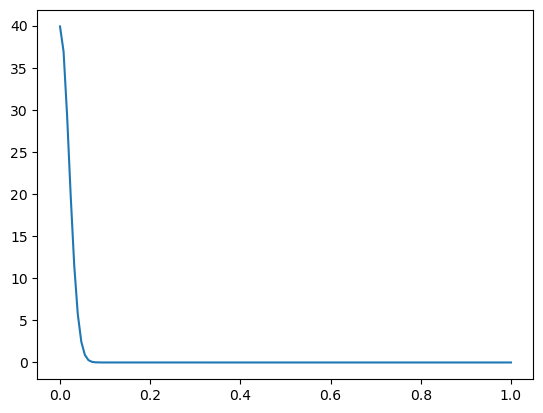

In [120]:
tmp = dist.TruncatedNormal(0.0, 0.02, low=0, high=1.0)
grid = np.linspace(0, 1, 128)
plt.plot(grid, np.exp(tmp.log_prob(grid)))

In [121]:
def model(data):
    _A1 = numpyro.sample("_A1", dist.HalfNormal(0.1))
    _A2 = numpyro.sample("_A2", dist.HalfNormal(0.1))
    A1 = numpyro.deterministic("A1", -_A1)
    A2 = numpyro.deterministic("A2", -_A2)

    h1   = numpyro.sample("h1",   dist.Uniform(0.04, 1.0))
    d_h2 = numpyro.sample("d_h2", dist.Uniform(0.04, 0.5))     
    h2 = numpyro.deterministic("h2", h1 + d_h2)

    z0 = numpyro.sample("z0", dist.Normal(0.0, 0.2))           

    offset = numpyro.sample("offset", dist.Normal(0.05, 0.10)) 

    model_y = mixture_of_sech2(data["z"], A1, A2, h1, h2, z0) + offset

    # Q = numpyro.sample("Q", dist.Beta(1.0, 9.0))
    Q = numpyro.sample("Q", dist.TruncatedNormal(0.0, 0.05, low=0, high=1.0))
    mix = dist.Categorical(probs=jnp.array([Q, 1.0 - Q]))
    components = [
        dist.Normal(0.0, jnp.sqrt(1.0**2 + data["mg_fe_err"]**2)),
        dist.Normal(model_y, data["mg_fe_err"]),
    ]

    numpyro.sample(
        "obs",
        dist.Mixture(mix, components),
        obs=data["mg_fe"],
    )

## 4. Per-bin binning + per-segment fit helpers

The binning is the demo's exact code (weighted mean + intrinsic-scatter inflation), wrapped into a function. The MCMC runner uses the demo's exact NUTS settings: `dense_mass=True`, `num_warmup=1000`, `num_samples=1000`, `num_chains=2`.


In [54]:
# z-bins for the binned-mean fit (same grid the demo uses)
Z_BINS_FIT = np.arange(-5, 5 + 1e-3, 0.1)


def bin_one(z, mgfe, mgfe_err, z_bins=Z_BINS_FIT):
    """Identical binning recipe to the demo."""
    stat1 = binned_statistic(z, mgfe / mgfe_err**2, bins=z_bins, statistic="sum")
    stat2 = binned_statistic(z, 1 / mgfe_err**2, bins=z_bins, statistic="sum")
    stat_std = binned_statistic(z, mgfe, bins=z_bins, statistic="std")
    stat_count = binned_statistic(z, mgfe, bins=z_bins, statistic="count")

    intrinsic_scatter = stat_std.statistic / np.sqrt(stat_count.statistic)

    mean_mg_fe = stat1.statistic / stat2.statistic
    mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
    z_binc = 0.5 * (z_bins[1:] + z_bins[:-1])

    counts = stat_count.statistic
    return z_binc, mean_mg_fe, mean_mg_fe_err, counts


# def fit_sech2(z_binc, mean_mg_fe, mean_mg_fe_err, key,
#               num_warmup=1000, num_samples=1000, num_chains=2,
#               progress_bar=False):
#     """Same NUTS settings as the demo. progress_bar off for the loop."""
#     sampler = infer.MCMC(
#         infer.NUTS(model, dense_mass=True),
#         num_warmup=num_warmup,
#         num_samples=num_samples,
#         num_chains=num_chains,
#         progress_bar=progress_bar,
#     )
#     data = {
#         "z": jnp.asarray(z_binc),
#         "mg_fe": jnp.asarray(mean_mg_fe),
#         "mg_fe_err": jnp.asarray(mean_mg_fe_err),
#     }
#     sampler.run(key, data=data)
#     return sampler


def fit_sech2(z_binc, mean_mg_fe, mean_mg_fe_err, key,
              num_warmup=1000, num_samples=1000, num_chains=2,
              progress_bar=False):
    sampler = infer.MCMC(
        infer.NUTS(
            model,
            dense_mass=True,
            target_accept_prob=0.95,                       # was default 0.8
            init_strategy=infer.init_to_median(num_samples=20),
        ),
        num_warmup=num_warmup, num_samples=num_samples,
        num_chains=num_chains, progress_bar=progress_bar,
    )
    data = {
        "z": jnp.asarray(z_binc),
        "mg_fe": jnp.asarray(mean_mg_fe),
        "mg_fe_err": jnp.asarray(mean_mg_fe_err),
    }
    sampler.run(key, data=data)
    return sampler

def select_annulus_segment(R_use, Z_use, mgfe_use, mgfe_err_use, seg_mask,
                           Rmin, Rmax,
                           min_bin_count=min_bin_count,
                           min_bins_for_fit=min_bins_for_fit,
                           z_fit_min=z_fit_min, z_fit_max=z_fit_max):
    """Select stars, run the binning, return the data ready to be fed to MCMC.

    Returns (z_binc, mean_mg_fe, mean_mg_fe_err, n_stars, ok) where `ok` is
    False if the (annulus, segment) doesn't have enough data to fit.
    """
    m = (
        seg_mask
        & (R_use >= Rmin) & (R_use < Rmax)
        & np.isfinite(Z_use) & np.isfinite(mgfe_use)
        & np.isfinite(mgfe_err_use) & (mgfe_err_use > 0)
    )
    n_stars = int(m.sum())
    if n_stars < minN_seg_total:
        return None, None, None, n_stars, False

    z_binc, mean_mg_fe, mean_mg_fe_err, counts = bin_one(
        Z_use[m], mgfe_use[m], mgfe_err_use[m]
    )

    # demo-style: drop bins with NaN/Inf or too few stars; restrict to fit window
    good = (
        np.isfinite(mean_mg_fe) & np.isfinite(mean_mg_fe_err)
        & (counts >= min_bin_count)
        & (z_binc >= z_fit_min) & (z_binc <= z_fit_max)
    )
    if good.sum() < min_bins_for_fit:
        return None, None, None, n_stars, False

    return (
        np.asarray(z_binc[good], float),
        np.asarray(mean_mg_fe[good], float),
        np.asarray(mean_mg_fe_err[good], float),
        n_stars,
        True,
    )


## 5. Test on one (annulus, segment)

Pick one (annulus, segment) pair and run through the full demo workflow: bin, fit, posterior summary, posterior-predictive plot, `z0` median/stddev. This validates the pipeline before the full loop.


In [55]:
# pick a well-populated annulus and a crowded segment
Rmin_focus, Rmax_focus = 8.0, 8.5
seg_focus = 6  # any of 1..seg_diag['n_crowd']

z_binc_t, mean_mg_fe_t, mean_mg_fe_err_t, n_stars_t, ok_t = select_annulus_segment(
    R_star, Z_star, mgfe_star, mgfe_err_star,
    seg_mask=segm[seg_focus],
    Rmin=Rmin_focus, Rmax=Rmax_focus,
)
print(f"stars in segment {seg_focus}, R=[{Rmin_focus},{Rmax_focus}]:", n_stars_t, "| fittable bins:", len(z_binc_t) if ok_t else 0)

assert ok_t, "smoke-test bin too sparse — pick a different (annulus, segment)"

sampler_t = fit_sech2(z_binc_t, mean_mg_fe_t, mean_mg_fe_err_t, jr.PRNGKey(0), progress_bar=True)
samples_t = sampler_t.get_samples()
idata_t   = az.from_numpyro(sampler_t)
az.summary(idata_t)


/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_6080/3181619348.py:14: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_6080/3181619348.py:15: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_6080/3181619348.py:45: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


stars in segment 6, R=[8.0,8.5]: 19662 | fittable bins: 30


sample: 100%|█| 2000/2000 [00:08<00:00, 238.17it/s, 255 steps of size 1.26e-02. 
sample: 100%|█| 2000/2000 [00:09<00:00, 203.75it/s, 255 steps of size 9.19e-03. 


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
A1,-0.031,0.017,-0.054,-0.000,0.001,0.001,237.0,130.0,1.01
A2,-0.027,0.017,-0.054,-0.001,0.001,0.000,259.0,196.0,1.01
Q,0.035,0.021,0.000,0.070,0.001,0.001,686.0,627.0,1.00
_A1,0.031,0.017,0.000,0.054,0.001,0.001,237.0,130.0,1.01
_A2,0.027,0.017,0.001,0.054,0.001,0.000,259.0,196.0,1.01
d_h2,0.250,0.130,0.044,0.469,0.004,0.002,956.0,885.0,1.00
h1,0.773,0.095,0.579,0.928,0.006,0.006,322.0,287.0,1.01
h2,1.023,0.135,0.812,1.277,0.006,0.003,475.0,881.0,1.01
offset,0.058,0.003,0.053,0.064,0.000,0.000,1289.0,1078.0,1.00
z0,-0.057,0.009,-0.072,-0.041,0.000,0.000,1244.0,1144.0,1.00


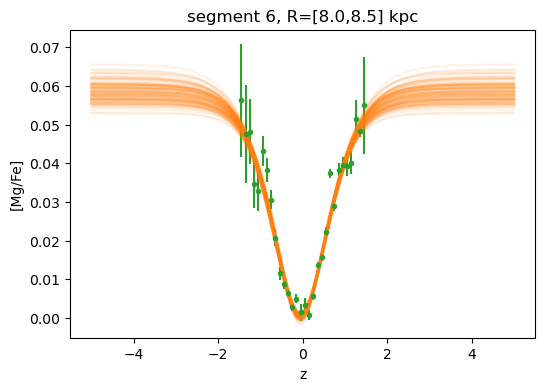

z0 median = -0.0573
z0 stddev = 0.009
SNR(z0)   = 6.65


In [56]:
z_grid = np.linspace(-5, 5, 1000)

plt.figure(figsize=(6, 4))
plt.errorbar(
    z_binc_t, mean_mg_fe_t, yerr=mean_mg_fe_err_t,
    color="C2", linestyle="", marker=".",
)
for i in range(100):
    A1 = samples_t["A1"][i]
    A2 = samples_t["A2"][i]
    h1 = samples_t["h1"][i]
    h2 = h1 + samples_t["d_h2"][i]
    z0 = samples_t["z0"][i]
    y_pred = mixture_of_sech2(z_grid, A1, A2, h1, h2, z0) + samples_t["offset"][i]
    plt.plot(z_grid, y_pred, color="C1", alpha=0.1, marker="")

plt.xlabel("z")
plt.ylabel("[Mg/Fe]")
plt.title(f"segment {seg_focus}, R=[{Rmin_focus},{Rmax_focus}] kpc")
plt.show()

print(f"z0 median = {np.median(samples_t['z0']):+.4f}")
print(f"z0 stddev = {np.std(samples_t['z0']):.3f}")
SNR_z0 = np.abs(np.median(samples_t['z0']) / np.std(samples_t['z0']))
print(f"SNR(z0)   = {SNR_z0:.2f}")


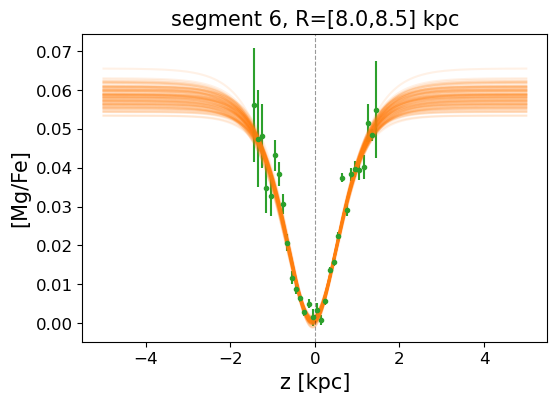

z0 median = -0.0574
z0 stddev = 0.008
SNR(z0)   = 6.91


In [49]:
z_grid = np.linspace(-5, 5, 1000)
plt.figure(figsize=(6, 4))
plt.errorbar(
    z_binc_t, mean_mg_fe_t, yerr=mean_mg_fe_err_t,
    color="C2", linestyle="", marker=".",
)
for i in range(100):
    A1 = samples_t["A1"][i]
    A2 = samples_t["A2"][i]
    h1 = samples_t["h1"][i]
    h2 = h1 + samples_t["d_h2"][i]
    z0 = samples_t["z0"][i]
    y_pred = mixture_of_sech2(z_grid, A1, A2, h1, h2, z0) + samples_t["offset"][i]
    plt.plot(z_grid, y_pred, color="C1", alpha=0.1, marker="")
plt.axvline(0, color="k", lw=0.8, ls="--", alpha=0.4)
plt.xlabel("z [kpc]", fontsize=15)
plt.ylabel("[Mg/Fe]", fontsize=15)
plt.title(f"segment {seg_focus}, R=[{Rmin_focus},{Rmax_focus}] kpc", fontsize=15)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.show()
print(f"z0 median = {np.median(samples_t['z0']):+.4f}")
print(f"z0 stddev = {np.std(samples_t['z0']):.3f}")
SNR_z0 = np.abs(np.median(samples_t['z0']) / np.std(samples_t['z0']))
print(f"SNR(z0)   = {SNR_z0:.2f}")

In [114]:
# pick a well-populated annulus and a crowded segment
Rmin_focus, Rmax_focus = 12.0, 12.5
seg_focus = 4  # any of 1..seg_diag['n_crowd']

z_binc_t, mean_mg_fe_t, mean_mg_fe_err_t, n_stars_t, ok_t = select_annulus_segment(
    R_star, Z_star, mgfe_star, mgfe_err_star,
    seg_mask=segm[seg_focus],
    Rmin=Rmin_focus, Rmax=Rmax_focus,
)
print(f"stars in segment {seg_focus}, R=[{Rmin_focus},{Rmax_focus}]:", n_stars_t, "| fittable bins:", len(z_binc_t) if ok_t else 0)

assert ok_t, "smoke-test bin too sparse — pick a different (annulus, segment)"

sampler_t = fit_sech2(z_binc_t, mean_mg_fe_t, mean_mg_fe_err_t, jr.PRNGKey(0), progress_bar=True)
samples_t = sampler_t.get_samples()
idata_t   = az.from_numpyro(sampler_t)
az.summary(idata_t)


/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_29533/3181619348.py:14: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_29533/3181619348.py:15: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_29533/3181619348.py:45: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


stars in segment 4, R=[12.0,12.5]: 1210 | fittable bins: 24


sample: 100%|█| 2000/2000 [00:05<00:00, 389.71it/s, 127 steps of size 2.75e-02. 
sample: 100%|█| 2000/2000 [00:05<00:00, 373.17it/s, 127 steps of size 2.71e-02. 


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
A1,-0.009,0.008,-0.024,-0.000,0.000,0.001,391.0,286.0,1.01
A2,-0.096,0.032,-0.158,-0.039,0.002,0.001,428.0,224.0,1.00
Q,0.062,0.042,0.001,0.138,0.001,0.001,1057.0,654.0,1.00
_A1,0.009,0.008,0.000,0.024,0.000,0.001,391.0,286.0,1.01
_A2,0.096,0.032,0.039,0.158,0.002,0.001,428.0,224.0,1.00
d_h2,1.420,0.389,0.717,1.990,0.014,0.008,749.0,878.0,1.01
h1,0.736,0.227,0.282,1.000,0.009,0.008,709.0,602.0,1.01
h2,2.156,0.395,1.479,2.882,0.014,0.007,796.0,873.0,1.01
offset,0.120,0.029,0.068,0.174,0.001,0.001,544.0,720.0,1.00
z0,0.317,0.069,0.193,0.444,0.002,0.002,1124.0,1257.0,1.00


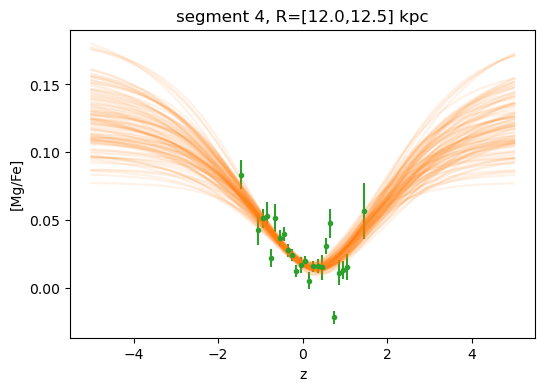

z0 median = +0.3134
z0 stddev = 0.069
SNR(z0)   = 4.52


In [115]:
z_grid = np.linspace(-5, 5, 1000)

plt.figure(figsize=(6, 4))
plt.errorbar(
    z_binc_t, mean_mg_fe_t, yerr=mean_mg_fe_err_t,
    color="C2", linestyle="", marker=".",
)
for i in range(100):
    A1 = samples_t["A1"][i]
    A2 = samples_t["A2"][i]
    h1 = samples_t["h1"][i]
    h2 = h1 + samples_t["d_h2"][i]
    z0 = samples_t["z0"][i]
    y_pred = mixture_of_sech2(z_grid, A1, A2, h1, h2, z0) + samples_t["offset"][i]
    plt.plot(z_grid, y_pred, color="C1", alpha=0.1, marker="")

plt.xlabel("z")
plt.ylabel("[Mg/Fe]")
plt.title(f"segment {seg_focus}, R=[{Rmin_focus},{Rmax_focus}] kpc")
plt.show()

print(f"z0 median = {np.median(samples_t['z0']):+.4f}")
print(f"z0 stddev = {np.std(samples_t['z0']):.3f}")
SNR_z0 = np.abs(np.median(samples_t['z0']) / np.std(samples_t['z0']))
print(f"SNR(z0)   = {SNR_z0:.2f}")


In [116]:
# pick a well-populated annulus and a crowded segment
Rmin_focus, Rmax_focus = 8.5, 9.0
seg_focus = 6  # any of 1..seg_diag['n_crowd']

z_binc_t, mean_mg_fe_t, mean_mg_fe_err_t, n_stars_t, ok_t = select_annulus_segment(
    R_star, Z_star, mgfe_star, mgfe_err_star,
    seg_mask=segm[seg_focus],
    Rmin=Rmin_focus, Rmax=Rmax_focus,
)
print(f"stars in segment {seg_focus}, R=[{Rmin_focus},{Rmax_focus}]:", n_stars_t, "| fittable bins:", len(z_binc_t) if ok_t else 0)

assert ok_t, "smoke-test bin too sparse — pick a different (annulus, segment)"

sampler_t = fit_sech2(z_binc_t, mean_mg_fe_t, mean_mg_fe_err_t, jr.PRNGKey(0), progress_bar=True)
samples_t = sampler_t.get_samples()
idata_t   = az.from_numpyro(sampler_t)
az.summary(idata_t)


/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_29533/3181619348.py:14: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_29533/3181619348.py:15: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_29533/3181619348.py:45: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


stars in segment 6, R=[8.5,9.0]: 22987 | fittable bins: 30


sample: 100%|█| 2000/2000 [00:05<00:00, 336.27it/s, 127 steps of size 2.37e-02. 
sample: 100%|█| 2000/2000 [00:05<00:00, 349.76it/s, 63 steps of size 3.98e-02. a


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
A1,-0.014,0.005,-0.023,-0.008,0.001,0.001,91.0,171.0,1.02
A2,-0.094,0.027,-0.166,-0.065,0.005,0.005,72.0,25.0,1.03
Q,0.038,0.034,0.000,0.105,0.001,0.001,616.0,769.0,1.00
_A1,0.014,0.005,0.008,0.023,0.001,0.001,91.0,171.0,1.02
_A2,0.094,0.027,0.065,0.166,0.005,0.005,72.0,25.0,1.03
d_h2,1.083,0.316,0.778,1.924,0.053,0.058,66.0,26.0,1.03
h1,0.206,0.104,0.100,0.388,0.011,0.006,143.0,392.0,1.03
h2,1.289,0.400,0.892,2.276,0.065,0.064,67.0,44.0,1.03
offset,0.093,0.031,0.058,0.174,0.005,0.006,64.0,26.0,1.03
z0,-0.001,0.006,-0.013,0.011,0.000,0.000,895.0,1197.0,1.00


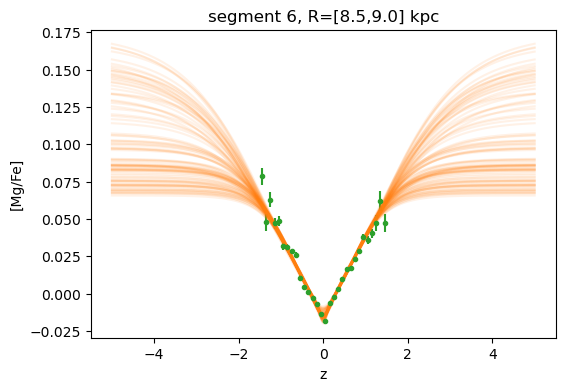

z0 median = -0.0010
z0 stddev = 0.006
SNR(z0)   = 0.16


In [117]:
z_grid = np.linspace(-5, 5, 1000)

plt.figure(figsize=(6, 4))
plt.errorbar(
    z_binc_t, mean_mg_fe_t, yerr=mean_mg_fe_err_t,
    color="C2", linestyle="", marker=".",
)
for i in range(100):
    A1 = samples_t["A1"][i]
    A2 = samples_t["A2"][i]
    h1 = samples_t["h1"][i]
    h2 = h1 + samples_t["d_h2"][i]
    z0 = samples_t["z0"][i]
    y_pred = mixture_of_sech2(z_grid, A1, A2, h1, h2, z0) + samples_t["offset"][i]
    plt.plot(z_grid, y_pred, color="C1", alpha=0.1, marker="")

plt.xlabel("z")
plt.ylabel("[Mg/Fe]")
plt.title(f"segment {seg_focus}, R=[{Rmin_focus},{Rmax_focus}] kpc")
plt.show()

print(f"z0 median = {np.median(samples_t['z0']):+.4f}")
print(f"z0 stddev = {np.std(samples_t['z0']):.3f}")
SNR_z0 = np.abs(np.median(samples_t['z0']) / np.std(samples_t['z0']))
print(f"SNR(z0)   = {SNR_z0:.2f}")


In [21]:
from itertools import product

n_R   = len(R_edges) - 1
n_seg = len(SEG_PLOT_heat)
z0_med  = np.full((n_R, n_seg), np.nan)
z0_std  = np.full((n_R, n_seg), np.nan)
n_stars = np.zeros((n_R, n_seg), dtype=int)
n_bins  = np.zeros((n_R, n_seg), dtype=int)
ok_grid = np.zeros((n_R, n_seg), dtype=bool)
per_cell = {}   # (i_R, j_seg) -> dict with binned data + samples

key = jr.PRNGKey(0)
pairs = list(product(range(n_R), range(n_seg)))

for k, (i_R, j_seg) in enumerate(pairs, 1):
    Rmin = float(R_edges[i_R]); Rmax = float(R_edges[i_R + 1])
    seg_id = SEG_PLOT_heat[j_seg]
    z_binc_k, mean_k, err_k, ns_k, ok_k = select_annulus_segment(
        R_star, Z_star, mgfe_star, mgfe_err_star,
        seg_mask=segm[seg_id], Rmin=Rmin, Rmax=Rmax,
    )
    n_stars[i_R, j_seg] = ns_k
    if not ok_k:
        continue
    n_bins[i_R, j_seg] = len(z_binc_k)
    try:
        key, sub = jr.split(key)
        sampler_k = fit_sech2(z_binc_k, mean_k, err_k, sub, progress_bar=False)
        samples_k = sampler_k.get_samples()
        z0_med[i_R, j_seg] = float(np.median(samples_k["z0"]))
        z0_std[i_R, j_seg] = float(np.std(samples_k["z0"]))
        ok_grid[i_R, j_seg] = True
        # NEW: keep what we need for the plot (first 200 draws is plenty)
        per_cell[(i_R, j_seg)] = {
            "z_binc": np.asarray(z_binc_k),
            "mean":   np.asarray(mean_k),
            "err":    np.asarray(err_k),
            "samples": {kk: np.asarray(vv[:1000]) for kk, vv in samples_k.items()},
        }
    except Exception as e:
        print(f"  fit failed: seg={seg_id} R=[{Rmin:.1f},{Rmax:.1f}] -> {e}")
    if k % 10 == 0 or k == len(pairs):
        print(f"  done {k}/{len(pairs)}", flush=True)

print("fits complete:", int(ok_grid.sum()), "/", ok_grid.size)

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_29533/3181619348.py:14: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_29533/3181619348.py:15: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_29533/3181619348.py:45: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


KeyboardInterrupt: 

In [118]:
from itertools import product
import os, pickle

# ---- where to save / load from ----
RESULTS_PATH = "sech2_mcmc_results2.pkl"
FORCE_RERUN  = False    # set True if you want to re-run the loop from scratch

# ---- try to load instead of re-fitting ----
if os.path.exists(RESULTS_PATH) and not FORCE_RERUN:
    with open(RESULTS_PATH, "rb") as f:
        saved = pickle.load(f)
    z0_med   = saved["z0_med"]
    z0_std   = saved["z0_std"]
    n_stars  = saved["n_stars"]
    n_bins   = saved["n_bins"]
    ok_grid  = saved["ok_grid"]
    per_cell = saved["per_cell"]
    print(f"loaded results from {RESULTS_PATH}  "
          f"({int(ok_grid.sum())}/{ok_grid.size} cells)")
else:
    n_R   = len(R_edges) - 1
    n_seg = len(SEG_PLOT_heat)
    z0_med  = np.full((n_R, n_seg), np.nan)
    z0_std  = np.full((n_R, n_seg), np.nan)
    n_stars = np.zeros((n_R, n_seg), dtype=int)
    n_bins  = np.zeros((n_R, n_seg), dtype=int)
    ok_grid = np.zeros((n_R, n_seg), dtype=bool)
    per_cell = {}

    key   = jr.PRNGKey(0)
    pairs = list(product(range(n_R), range(n_seg)))

    for k, (i_R, j_seg) in enumerate(pairs, 1):
        Rmin = float(R_edges[i_R]); Rmax = float(R_edges[i_R + 1])
        seg_id = SEG_PLOT_heat[j_seg]
        z_binc_k, mean_k, err_k, ns_k, ok_k = select_annulus_segment(
            R_star, Z_star, mgfe_star, mgfe_err_star,
            seg_mask=segm[seg_id], Rmin=Rmin, Rmax=Rmax,
        )
        n_stars[i_R, j_seg] = ns_k
        if not ok_k:
            continue
        n_bins[i_R, j_seg] = len(z_binc_k)
        try:
            key, sub = jr.split(key)
            sampler_k = fit_sech2(z_binc_k, mean_k, err_k, sub, progress_bar=False)
            samples_k = sampler_k.get_samples()
            z0_med[i_R, j_seg] = float(np.median(samples_k["z0"]))
            z0_std[i_R, j_seg] = float(np.std(samples_k["z0"]))
            ok_grid[i_R, j_seg] = True
            per_cell[(i_R, j_seg)] = {
                "z_binc": np.asarray(z_binc_k),
                "mean":   np.asarray(mean_k),
                "err":    np.asarray(err_k),
                "samples": {kk: np.asarray(vv[:1000]) for kk, vv in samples_k.items()},
            }
        except Exception as e:
            print(f"  fit failed: seg={seg_id} R=[{Rmin:.1f},{Rmax:.1f}] -> {e}")
        if k % 10 == 0 or k == len(pairs):
            print(f"  done {k}/{len(pairs)}", flush=True)

    print("fits complete:", int(ok_grid.sum()), "/", ok_grid.size)

    # ---- save everything for next time ----
    with open(RESULTS_PATH, "wb") as f:
        pickle.dump({
            "z0_med":   z0_med,
            "z0_std":   z0_std,
            "n_stars":  n_stars,
            "n_bins":   n_bins,
            "ok_grid":  ok_grid,
            "per_cell": per_cell,
            # metadata so you remember what these results correspond to
            "R_edges":       R_edges,
            "SEG_PLOT_heat": SEG_PLOT_heat,
            "crowd_bounds":  np.asarray(crowd_bounds),
        }, f)
    print(f"saved to {RESULTS_PATH}")

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_29533/3181619348.py:14: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_29533/3181619348.py:15: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_29533/3181619348.py:45: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


  done 70/330
  done 130/330
  done 140/330
  done 150/330
  done 160/330
  done 170/330
  done 180/330
  done 190/330
  done 200/330
  done 210/330
  done 220/330
  done 230/330
  done 240/330
  done 250/330
  done 260/330
  done 270/330
  done 280/330
  done 290/330
  done 300/330
fits complete: 206 / 330
saved to sech2_mcmc_results2.pkl


In [57]:
import pickle

with open("sech2_mcmc_results2.pkl", "rb") as f:
    results = pickle.load(f)

per_cell = results["per_cell"]
z0_med   = results["z0_med"]
z0_std   = results["z0_std"]

In [58]:
per_cell.keys()

dict_keys([(6, 2), (6, 3), (6, 4), (6, 6), (7, 3), (7, 4), (7, 6), (7, 7), (8, 3), (8, 4), (8, 5), (8, 6), (8, 7), (9, 1), (9, 2), (9, 3), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (10, 3), (10, 4), (10, 5), (10, 6), (10, 7), (10, 8), (11, 0), (11, 1), (11, 2), (11, 3), (11, 4), (11, 5), (11, 6), (11, 7), (11, 8), (11, 9), (11, 10), (12, 0), (12, 1), (12, 2), (12, 3), (12, 4), (12, 5), (12, 6), (12, 7), (12, 8), (12, 9), (12, 10), (13, 0), (13, 1), (13, 2), (13, 3), (13, 4), (13, 5), (13, 6), (13, 7), (13, 8), (13, 9), (13, 10), (14, 0), (14, 1), (14, 2), (14, 3), (14, 4), (14, 5), (14, 6), (14, 7), (14, 8), (14, 9), (14, 10), (15, 1), (15, 2), (15, 3), (15, 4), (15, 5), (15, 6), (15, 7), (15, 8), (15, 9), (15, 10), (16, 0), (16, 1), (16, 2), (16, 3), (16, 4), (16, 5), (16, 6), (16, 7), (16, 8), (16, 9), (16, 10), (17, 0), (17, 1), (17, 2), (17, 3), (17, 4), (17, 5), (17, 6), (17, 7), (17, 8), (17, 9), (17, 10), (18, 0), (18, 1), (18, 2), (18, 3), (18, 4), (18, 5), (18, 6), (18, 7), (18,

In [121]:
cell_samples = per_cell[6,2]["samples"]

cell_sample = {k:v[0] for k,v in cell_samples.items()}
#temporary fix, remove later
cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]


In [122]:
from scipy.optimize import root

def root_func(z, pars):
    Ystar = mixture_of_sech2(
        z, pars["A1"], pars["A2"], pars["h1"], pars["h2"], pars["z0"]
    )
    return Ystar - 0.5 * (pars["A1"] + pars["A2"])

result = root(root_func, x0=cell_sample["z0"] + 1e-3, args=(cell_sample,))


In [123]:
zstar = result.x[0]
h_eff = np.abs(zstar - cell_sample["z0"])

print(h_eff)
print(cell_sample["h1"])
print(cell_sample["h2"])

0.5257644202669591
0.4549586119645603
0.7925393760447758


In [124]:
h_effs = []
for i in range(200):
    cell_sample = {k: v[i] for k, v in cell_samples.items()}
    cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]  
    result = root(root_func, x0=cell_sample["z0"] + 1e-3, args=(cell_sample,))
    h_eff = np.abs(result.x[0] - cell_sample["z0"])
    h_effs.append(h_eff)

In [185]:
h_effs = []
for i in range(200):
    cell_sample = {k: v[i] for k, v in cell_samples.items()}
    cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
    hi = 8 * max(cell_sample["h1"], cell_sample["h2"])
    try:
        zstar = brentq(root_func, cell_sample["z0"] + 1e-9, hi, args=(cell_sample,))
        h_effs.append(zstar - cell_sample["z0"])
    except ValueError:
        continue   # failed

In [186]:
h_effs = np.array(h_effs)
print(f"h_eff median = {np.median(h_effs):.3f} kpc")
print(f"h_eff stddev = {np.std(h_effs):.3f} kpc")

h_eff median = 0.897 kpc
h_eff stddev = 0.355 kpc


computing h_eff: 100%|████████████████████████| 206/206 [01:39<00:00,  2.07it/s]


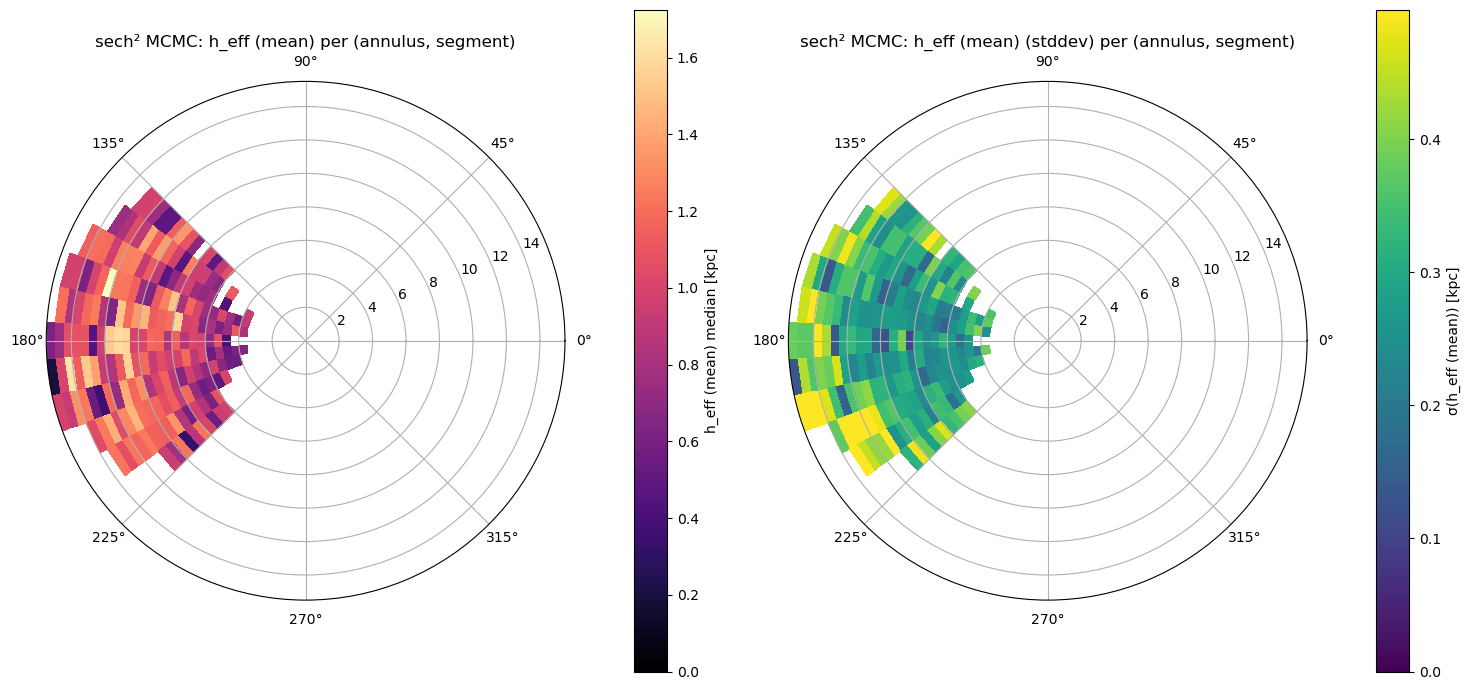

In [153]:
from tqdm import tqdm
h_eff_med = np.full((n_R, n_seg), np.nan)
h_eff_std = np.full((n_R, n_seg), np.nan)

for (i_R, j_seg), cell in tqdm(per_cell.items(), desc="computing h_eff"):
    s = cell["samples"]
    
    h_effs = []
    for i in range(256):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        result = root(root_func, x0=cell_sample["z0"] + 1e-3, args=(cell_sample,))
        if result.success:
            h_eff = np.abs(result.x[0] - cell_sample["z0"])
            h_effs.append(h_eff)
    
    if len(h_effs) > 0:
        h_eff_med[i_R, j_seg] = np.mean(h_effs)
        h_eff_std[i_R, j_seg] = np.std(h_effs)
heatmap_pair(h_eff_med, h_eff_std, name="h_eff (mean)", units="[kpc]", vmin=0.0, vmax=None)

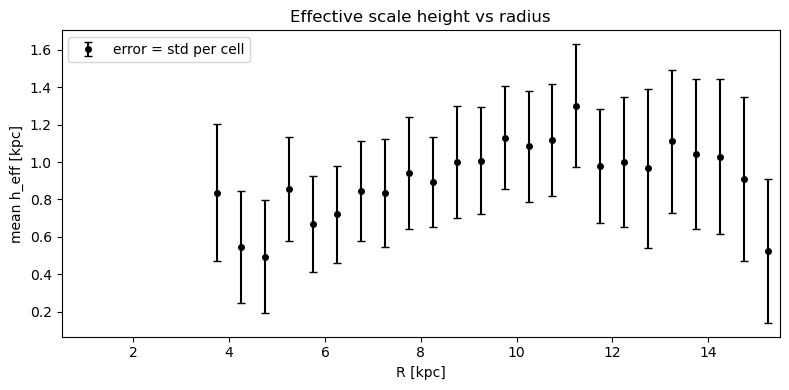

In [154]:
h_eff_med[i_R, j_seg] = np.mean(h_effs)
h_eff_std[i_R, j_seg] = np.std(h_effs)

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(R_centers, h_eff_med_R, yerr=h_eff_std_R,
            fmt="o", color="k", ms=4, capsize=3,
            label="error = std per cell")
ax.legend(loc="upper left")
ax.set_xlabel("R [kpc]")
ax.set_ylabel("mean h_eff [kpc]")
ax.set_title("Effective scale height vs radius")
ax.set_xlim(R_edges[0], R_edges[-1])
plt.tight_layout()
plt.show()

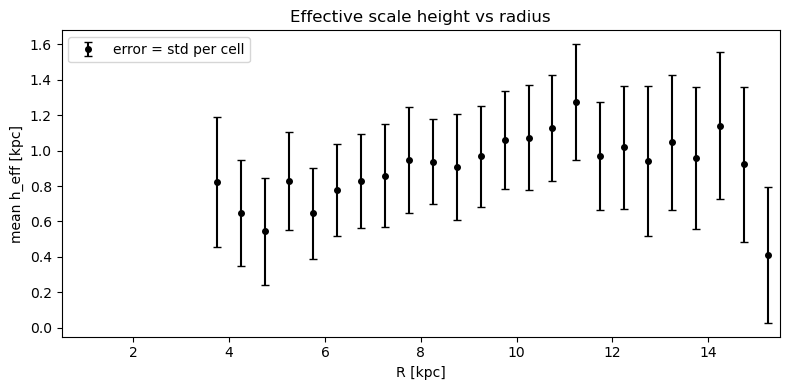

In [157]:
h_effs_arr = np.array(h_effs)
h_eff_med[i_R, j_seg] = np.median(h_effs_arr)
pcl = np.percentile(h_effs_arr, [16, 84])
h_eff_std[i_R, j_seg] = 0.5 * (pcl[1] - pcl[0])

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(R_centers, h_eff_med_R, yerr=h_eff_std_R,
            fmt="o", color="k", ms=4, capsize=3,
            label="error = std per cell")
ax.legend(loc="upper left")
ax.set_xlabel("R [kpc]")
ax.set_ylabel("median h_eff [kpc]")
ax.set_title("Effective scale height vs radius")
ax.set_xlim(R_edges[0], R_edges[-1])
plt.tight_layout()
plt.show()

computing h_eff: 100%|████████████████████████| 206/206 [01:10<00:00,  2.92it/s]
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_29533/3637857576.py:34: RuntimeWarning: Mean of empty slice
  h_eff_med_R = np.nanmean(h_eff_med, axis=1)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_29533/3637857576.py:35: RuntimeWarning: Mean of empty slice
  h_eff_std_R = np.nanmean(h_eff_std, axis=1)


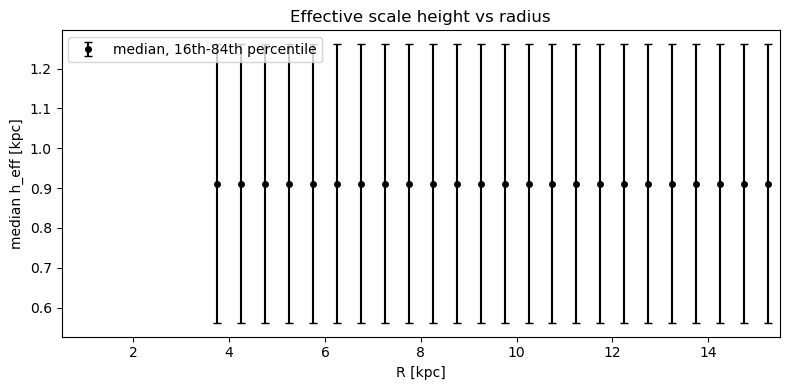

In [204]:
from tqdm import tqdm

h_eff_med = np.full((n_R, n_seg), np.nan)
h_eff_std = np.full((n_R, n_seg), np.nan)

for (i_R, j_seg), cell in tqdm(per_cell.items(), desc="computing h_eff"):
    s = cell["samples"]
    
    # h_effs = []
    # for i in range(256):
    #     cell_sample = {k: v[i] for k, v in s.items()}
    #     cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
    #     result = root(root_func, x0=cell_sample["z0"] + 1e-3, args=(cell_sample,))
    #     if result.success:
    #         h_effs.append(np.abs(result.x[0] - cell_sample["z0"]))

    h_effs = []
    for i in range(256):
        cell_sample = {k: v[i] for k, v in cell_samples.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        hi = 8 * max(cell_sample["h1"], cell_sample["h2"])
        try:
            zstar = brentq(root_func, cell_sample["z0"] + 1e-9, hi, args=(cell_sample,))
            h_effs.append(zstar - cell_sample["z0"])
        except ValueError:
            continue   # failed
        
    if len(h_effs) > 0:
        h_effs = np.array(h_effs)
        h_eff_med[i_R, j_seg] = np.median(h_effs)
        pcl = np.percentile(h_effs, [16, 84])
        h_eff_std[i_R, j_seg] = 0.5 * (pcl[1] - pcl[0])

h_eff_med_R = np.nanmean(h_eff_med, axis=1)
h_eff_std_R = np.nanmean(h_eff_std, axis=1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(R_centers, h_eff_med_R, yerr=h_eff_std_R,
            fmt="o", color="k", ms=4, capsize=3,
            label="median, 16th-84th percentile")

ax.legend(loc="upper left")
ax.set_xlabel("R [kpc]")
ax.set_ylabel("median h_eff [kpc]")
ax.set_title("Effective scale height vs radius")
ax.set_xlim(R_edges[0], R_edges[-1])
plt.tight_layout()
plt.show()

In [198]:
from tqdm import tqdm

i_R_focus = np.searchsorted(R_edges, 8.0)
cells_in_R = [(i_R, j_seg) for (i_R, j_seg) in per_cell.keys() if i_R == i_R_focus]

h_eff_med = np.full((n_R, n_seg), np.nan)
h_eff_std = np.full((n_R, n_seg), np.nan)

for (i_R, j_seg) in tqdm(cells_in_R, desc="computing h_eff"):
    cell = per_cell[(i_R, j_seg)]
    s = cell["samples"]
    
    h_effs = []
    for i in range(256):
        cell_sample = {k: v[i] for k, v in s.items()}  # fixed: was cell_samples
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        hi = 8 * max(cell_sample["h1"], cell_sample["h2"])
        try:
            zstar = brentq(root_func, cell_sample["z0"] + 1e-9, hi, args=(cell_sample,))
            h_effs.append(zstar - cell_sample["z0"])
        except ValueError:
            continue

    if len(h_effs) > 0:
        h_effs = np.array(h_effs)
        h_eff_med[i_R, j_seg] = np.median(h_effs)
        pcl = np.percentile(h_effs, [16, 84])
        h_eff_std[i_R, j_seg] = 0.5 * (pcl[1] - pcl[0])

# plot just the R=8-8.5 bin
print("h_eff per segment at R=[8.0,8.5]:")
for (i_R, j_seg) in cells_in_R:
    seg_id = SEG_PLOT_heat[j_seg]
    print(f"  seg {seg_id}: median={h_eff_med[i_R, j_seg]:.3f}, "
          f"uncertainty={h_eff_std[i_R, j_seg]:.3f}")

computing h_eff: 100%|██████████████████████████| 10/10 [00:04<00:00,  2.29it/s]

h_eff per segment at R=[8.0,8.5]:
  seg 2: median=1.185, uncertainty=0.404
  seg 3: median=0.818, uncertainty=0.339
  seg 4: median=1.528, uncertainty=0.236
  seg 5: median=1.222, uncertainty=0.277
  seg 6: median=0.801, uncertainty=0.094
  seg 7: median=0.907, uncertainty=0.167
  seg 8: median=0.829, uncertainty=0.279
  seg 9: median=0.878, uncertainty=0.227
  seg 10: median=0.536, uncertainty=0.222
  seg 11: median=1.158, uncertainty=0.468


In [193]:
i_R_focus = np.searchsorted(R_edges, 8.0)
cells_in_R = [(i_R, j_seg) for (i_R, j_seg) in per_cell.keys() if i_R == i_R_focus]

for (i_R, j_seg) in cells_in_R:
    cell = per_cell[(i_R, j_seg)]
    seg_id = SEG_PLOT_heat[j_seg]
    s = cell["samples"]
    
    zstar_vals = []
    h_eff_vals = []
    failed = 0
    
    for i in range(200):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        hi = 8 * max(cell_sample["h1"], cell_sample["h2"])
        
        try:
            zstar = brentq(root_func, cell_sample["z0"] + 1e-9, hi, args=(cell_sample,))
            h_eff = zstar - cell_sample["z0"]
            zstar_vals.append(zstar)
            h_eff_vals.append(h_eff)
        except ValueError:
            failed += 1
    
    print(f"seg {seg_id}: failed={failed}/200, "
          f"h_eff min={min(h_eff_vals):.3f}, max={max(h_eff_vals):.3f}, "
          f"median={np.median(h_eff_vals):.3f}")

seg 2: failed=0/200, h_eff min=0.293, max=2.511, median=1.237
seg 3: failed=0/200, h_eff min=0.343, max=1.807, median=0.888
seg 4: failed=0/200, h_eff min=0.960, max=1.903, median=1.546
seg 5: failed=0/200, h_eff min=0.601, max=1.632, median=1.193
seg 6: failed=0/200, h_eff min=0.693, max=1.296, median=0.802
seg 7: failed=0/200, h_eff min=0.692, max=1.702, median=0.908
seg 8: failed=0/200, h_eff min=0.480, max=1.640, median=0.844
seg 9: failed=0/200, h_eff min=0.547, max=1.746, median=0.898
seg 10: failed=0/200, h_eff min=0.265, max=1.237, median=0.552
seg 11: failed=0/200, h_eff min=0.130, max=2.356, median=1.183


In [195]:
i_R_focus = np.searchsorted(R_edges, 8.0)
cells_in_R = [(i_R, j_seg) for (i_R, j_seg) in per_cell.keys() if i_R == i_R_focus]

for (i_R, j_seg) in cells_in_R:
    cell = per_cell[(i_R, j_seg)]
    seg_id = SEG_PLOT_heat[j_seg]
    s = cell["samples"]
    
    zstar_vals = []
    h_eff_vals = []
    failed = 0
    
    for i in range(200):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        hi = 8 * max(cell_sample["h1"], cell_sample["h2"])
        
        try:
            zstar = brentq(root_func, cell_sample["z0"] + 1e-9, hi, args=(cell_sample,))
            h_eff = zstar - cell_sample["z0"]
            zstar_vals.append(zstar)
            h_eff_vals.append(h_eff)
        except ValueError:
            failed += 1
    
    print(f"seg {seg_id}: failed={failed}/200")
    print(f"  zstar:  min={min(zstar_vals):.3f}, max={max(zstar_vals):.3f}, "
          f"mean={np.mean(zstar_vals):.3f}, median={np.median(zstar_vals):.3f}")
    print(f"  h_eff:  min={min(h_eff_vals):.3f}, max={max(h_eff_vals):.3f}, "
          f"mean={np.mean(h_eff_vals):.3f}, median={np.median(h_eff_vals):.3f}")

seg 2: failed=0/200
  zstar:  min=0.352, max=2.411, mean=1.181, median=1.127
  h_eff:  min=0.293, max=2.511, mean=1.263, median=1.237
seg 3: failed=0/200
  zstar:  min=0.393, max=1.812, mean=0.964, median=0.884
  h_eff:  min=0.343, max=1.807, mean=0.955, median=0.888
seg 4: failed=0/200
  zstar:  min=0.951, max=1.922, mean=1.545, median=1.573
  h_eff:  min=0.960, max=1.903, mean=1.528, median=1.546
seg 5: failed=0/200
  zstar:  min=0.596, max=1.637, mean=1.190, median=1.200
  h_eff:  min=0.601, max=1.632, mean=1.187, median=1.193
seg 6: failed=0/200
  zstar:  min=0.631, max=1.245, mean=0.778, median=0.744
  h_eff:  min=0.693, max=1.296, mean=0.836, median=0.802
seg 7: failed=0/200
  zstar:  min=0.723, max=1.808, mean=1.056, median=0.990
  h_eff:  min=0.692, max=1.702, mean=0.983, median=0.908
seg 8: failed=0/200
  zstar:  min=0.419, max=1.591, mean=0.848, median=0.801
  h_eff:  min=0.480, max=1.640, mean=0.892, median=0.844
seg 9: failed=0/200
  zstar:  min=0.472, max=1.730, mean=0.929

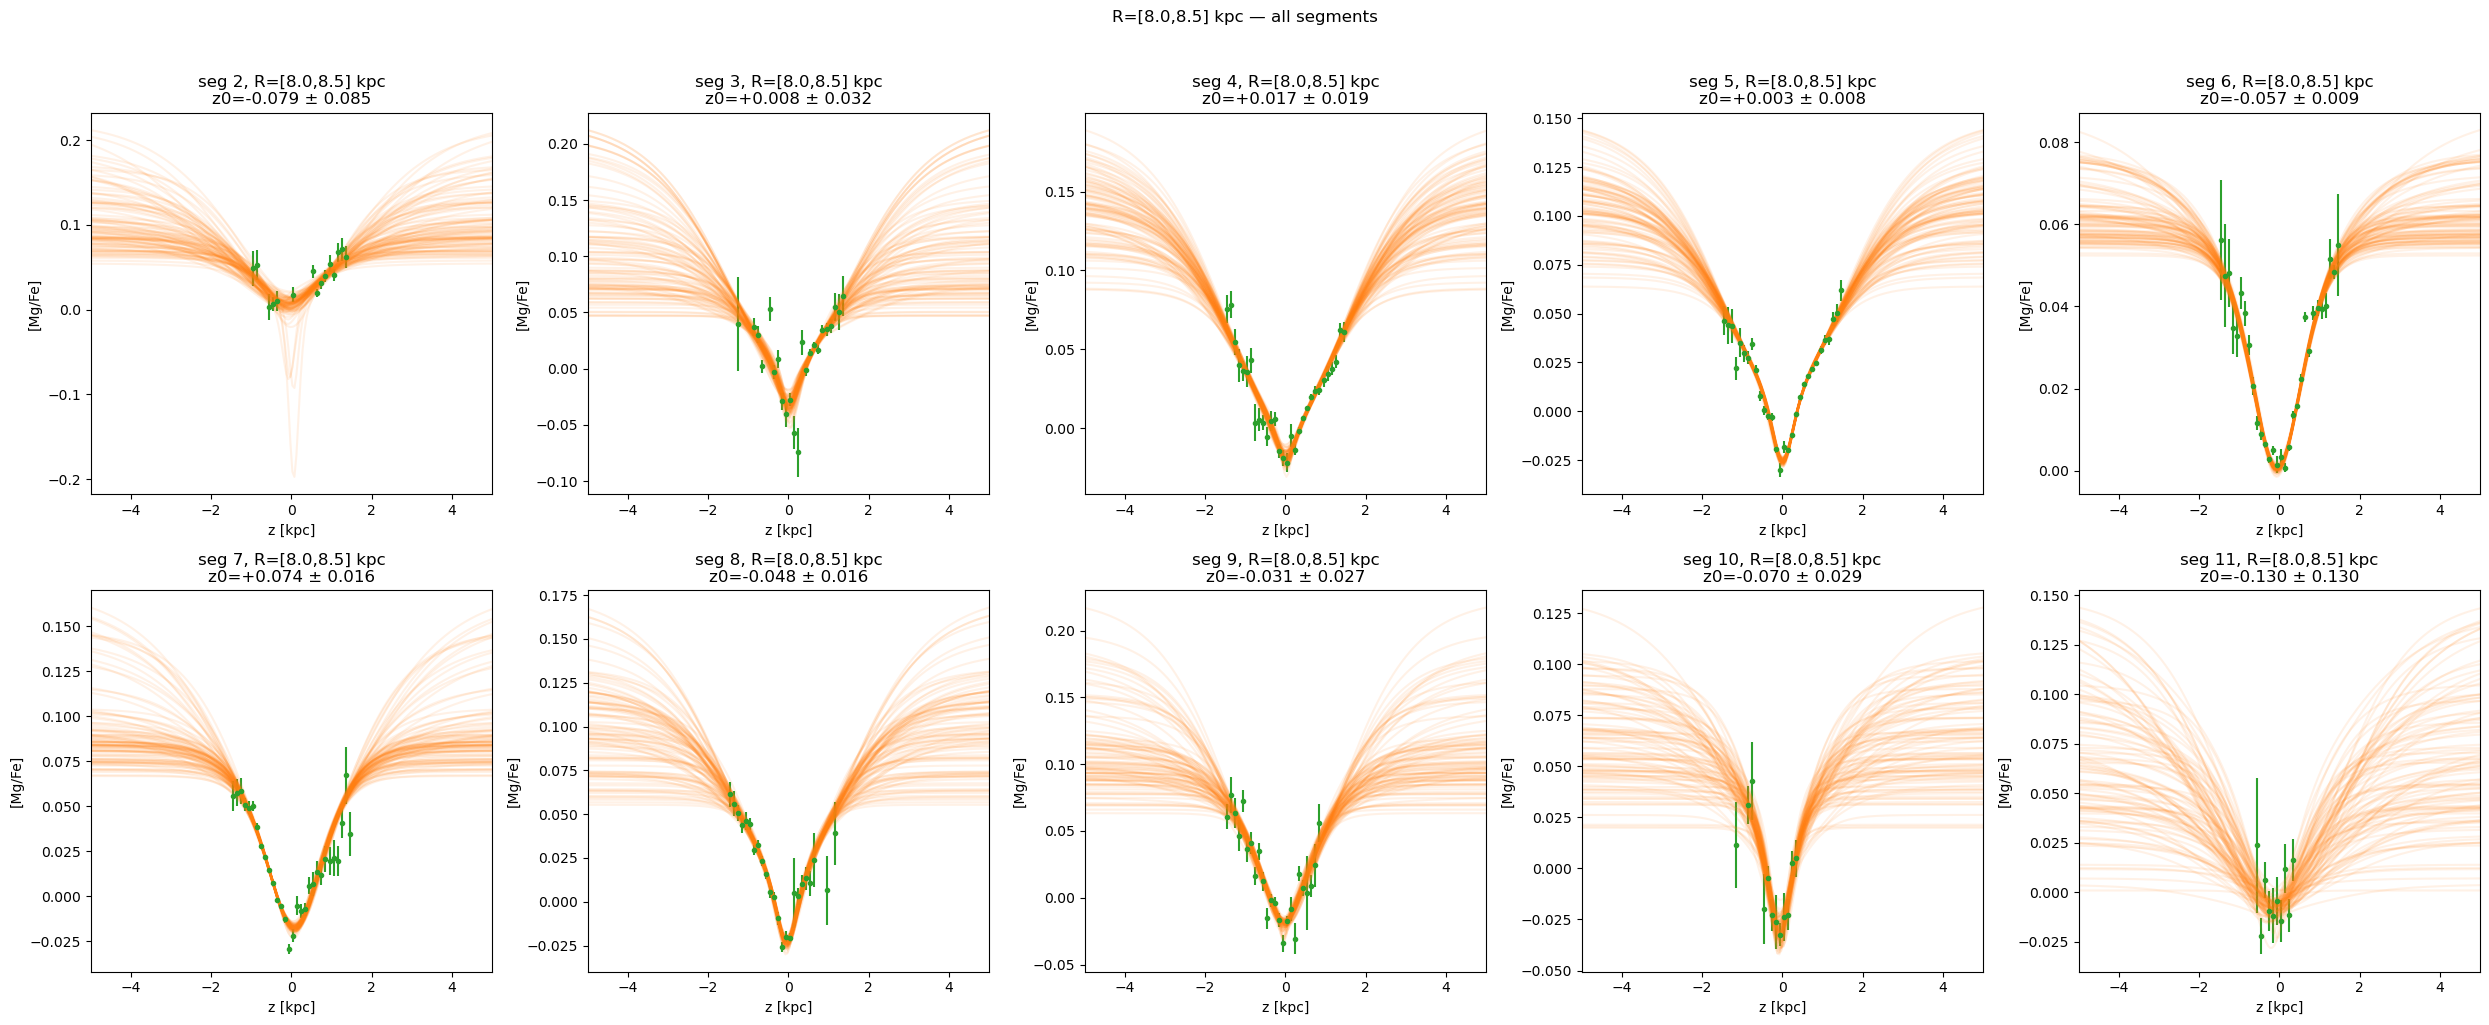

In [166]:
i_R_focus = np.searchsorted(R_edges, 8.0)
cells_in_R = [(i_R, j_seg) for (i_R, j_seg) in per_cell.keys() if i_R == i_R_focus]
n_cells = len(cells_in_R)
n_cols = 5
n_rows = int(np.ceil(n_cells / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows), squeeze=False)
z_grid = np.linspace(-5, 5, 200)

for idx, (i_R, j_seg) in enumerate(cells_in_R):
    r, c = divmod(idx, n_cols)
    ax = axes[r, c]
    cell = per_cell[(i_R, j_seg)]
    seg_id = SEG_PLOT_heat[j_seg]
    s = cell["samples"]

    ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
                color="C2", linestyle="", marker=".", label="binned mean")

    for i in range(min(100, len(s["A1"]))):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        y_pred = mixture_of_sech2(z_grid, cell_sample["A1"], cell_sample["A2"],
                                  cell_sample["h1"], cell_sample["h2"],
                                  cell_sample["z0"]) + cell_sample["offset"]
        ax.plot(z_grid, y_pred, color="C1", alpha=0.1)

    ax.set_xlabel("z [kpc]")
    ax.set_ylabel("[Mg/Fe]")
    ax.set_title(f"seg {seg_id}, R=[{R_edges[i_R]:.1f},{R_edges[i_R+1]:.1f}] kpc\n"
                 f"z0={z0_med[i_R,j_seg]:+.3f} ± {z0_std[i_R,j_seg]:.3f}")
    ax.set_xlim(-5, 5)

for idx in range(n_cells, n_rows * n_cols):
    r, c = divmod(idx, n_cols)
    axes[r, c].axis("off")

plt.suptitle(f"R=[{R_edges[i_R_focus]:.1f},{R_edges[i_R_focus+1]:.1f}] kpc — all segments", y=1.02)
plt.tight_layout()
plt.show()

In [167]:
cell = per_cell[(i_R_focus, cells_in_R[2][1])]
s = cell["samples"]
print("A1 range:", np.min(s["A1"]), np.max(s["A1"]))
print("A2 range:", np.min(s["A2"]), np.max(s["A2"]))
print("0.5*(A1+A2) range:", np.min(0.5*(s["A1"]+s["A2"])), np.max(0.5*(s["A1"]+s["A2"])))
print("offset range:", np.min(s["offset"]), np.max(s["offset"]))

A1 range: -0.04891155918829148 -0.008420327942349884
A2 range: -0.20212248053820328 -0.05847934108917821
0.5*(A1+A2) range: -0.11347635664599542 -0.044684678816837714
offset range: 0.07292458008621006 0.2026981635577517


computing h_eff: 100%|████████████████████████| 206/206 [01:09<00:00,  2.97it/s]
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_29533/102831393.py:43: RuntimeWarning: All-NaN slice encountered
  h_eff_med_R = np.nanmedian(h_eff_med, axis=1)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_29533/102831393.py:44: RuntimeWarning: All-NaN slice encountered
  h_eff_std_R = np.nanmedian(h_eff_std, axis=1)


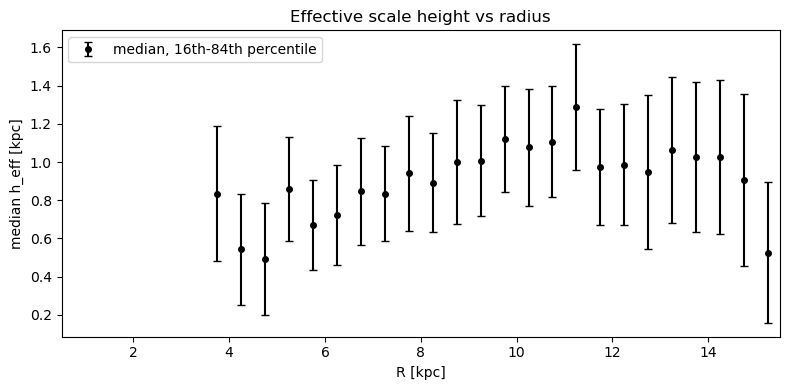

In [172]:
from scipy.optimize import brentq
from tqdm import tqdm

def compute_h_eff(pars, z_max=1.5):
    z0 = pars["z0"]
    half_max = 0.5 * (pars["A1"] + pars["A2"])
    
    f_z0 = mixture_of_sech2(z0, pars["A1"], pars["A2"], pars["h1"], pars["h2"], z0)
    f_zmax = mixture_of_sech2(z0 + z_max, pars["A1"], pars["A2"], pars["h1"], pars["h2"], z0)
    
    if (f_z0 - half_max) * (f_zmax - half_max) > 0:
        return np.nan
    
    try:
        zstar = brentq(
            lambda z: mixture_of_sech2(z, pars["A1"], pars["A2"], pars["h1"], pars["h2"], z0) - half_max,
            z0 + 1e-3, z0 + z_max
        )
        return np.abs(zstar - z0)
    except ValueError:
        return np.nan

h_eff_med = np.full((n_R, n_seg), np.nan)
h_eff_std = np.full((n_R, n_seg), np.nan)

for (i_R, j_seg), cell in tqdm(per_cell.items(), desc="computing h_eff"):
    s = cell["samples"]
    
    h_effs = []
    for i in range(256):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        h_eff = compute_h_eff(cell_sample, z_max=2.0)
        if np.isfinite(h_eff):
            h_effs.append(h_eff)
    
    if len(h_effs) > 0:
        h_effs = np.array(h_effs)
        h_eff_med[i_R, j_seg] = np.median(h_effs)
        pcl = np.percentile(h_effs, [16, 84])
        h_eff_std[i_R, j_seg] = 0.5 * (pcl[1] - pcl[0])

h_eff_med_R = np.nanmedian(h_eff_med, axis=1)
h_eff_std_R = np.nanmedian(h_eff_std, axis=1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(R_centers, h_eff_med_R, yerr=h_eff_std_R,
            fmt="o", color="k", ms=4, capsize=3,
            label="median, 16th-84th percentile")
ax.legend(loc="upper left")
ax.set_xlabel("R [kpc]")
ax.set_ylabel("median h_eff [kpc]")
ax.set_title("Effective scale height vs radius")
ax.set_xlim(R_edges[0], R_edges[-1])
plt.tight_layout()
plt.show()

segment: (15, 3)
seg_id: 4


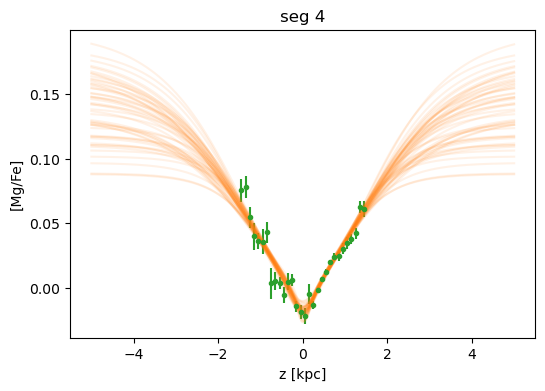

In [170]:
print("segment:", cells_in_R[2])
i_R, j_seg = cells_in_R[2]
cell = per_cell[(i_R, j_seg)]
seg_id = SEG_PLOT_heat[j_seg]
print("seg_id:", seg_id)

fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
            color="C2", linestyle="", marker=".")
s = cell["samples"]
z_grid = np.linspace(-5, 5, 200)
for i in range(50):
    cell_sample = {k: v[i] for k, v in s.items()}
    cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
    y_pred = mixture_of_sech2(z_grid, cell_sample["A1"], cell_sample["A2"],
                              cell_sample["h1"], cell_sample["h2"],
                              cell_sample["z0"]) + cell_sample["offset"]
    ax.plot(z_grid, y_pred, color="C1", alpha=0.1)
ax.set_xlabel("z [kpc]")
ax.set_ylabel("[Mg/Fe]")
ax.set_title(f"seg {seg_id}")
plt.show()

computing h_eff: 100%|████████████████████████| 206/206 [02:13<00:00,  1.54it/s]
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_29533/3120834905.py:53: RuntimeWarning: All-NaN slice encountered
  h_eff_med_R = np.nanmedian(h_eff_med, axis=1)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_29533/3120834905.py:54: RuntimeWarning: All-NaN slice encountered
  h_eff_std_R = np.nanmedian(h_eff_std, axis=1)


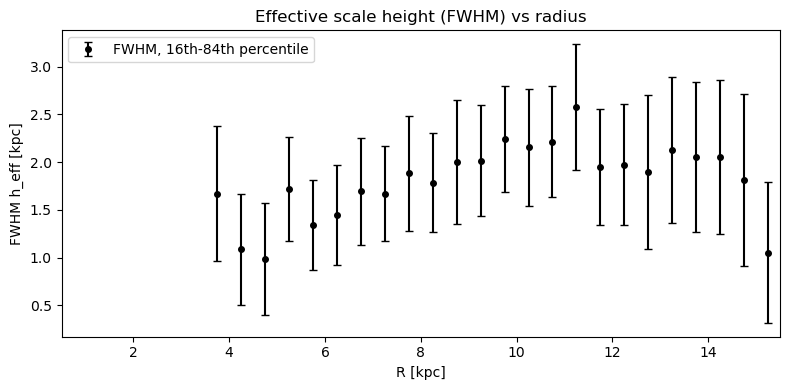

In [173]:
from scipy.optimize import brentq
from tqdm import tqdm

def compute_h_eff(pars, z_max=1.5):
    z0 = pars["z0"]
    half_max = 0.5 * (pars["A1"] + pars["A2"])
    
    f_z0 = mixture_of_sech2(z0, pars["A1"], pars["A2"], pars["h1"], pars["h2"], z0)
    f_zmax_right = mixture_of_sech2(z0 + z_max, pars["A1"], pars["A2"], pars["h1"], pars["h2"], z0)
    f_zmax_left = mixture_of_sech2(z0 - z_max, pars["A1"], pars["A2"], pars["h1"], pars["h2"], z0)
    
    try:
        if (f_z0 - half_max) * (f_zmax_right - half_max) < 0:
            zstar_right = brentq(
                lambda z: mixture_of_sech2(z, pars["A1"], pars["A2"], pars["h1"], pars["h2"], z0) - half_max,
                z0 + 1e-3, z0 + z_max
            )
        else:
            return np.nan
        
        if (f_z0 - half_max) * (f_zmax_left - half_max) < 0:
            zstar_left = brentq(
                lambda z: mixture_of_sech2(z, pars["A1"], pars["A2"], pars["h1"], pars["h2"], z0) - half_max,
                z0 - z_max, z0 - 1e-3
            )
        else:
            return np.nan
        
        return zstar_right - zstar_left
    except ValueError:
        return np.nan

h_eff_med = np.full((n_R, n_seg), np.nan)
h_eff_std = np.full((n_R, n_seg), np.nan)

for (i_R, j_seg), cell in tqdm(per_cell.items(), desc="computing h_eff"):
    s = cell["samples"]
    
    h_effs = []
    for i in range(256):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        h_eff = compute_h_eff(cell_sample, z_max=2.0)
        if np.isfinite(h_eff):
            h_effs.append(h_eff)
    
    if len(h_effs) > 0:
        h_effs = np.array(h_effs)
        h_eff_med[i_R, j_seg] = np.median(h_effs)
        pcl = np.percentile(h_effs, [16, 84])
        h_eff_std[i_R, j_seg] = 0.5 * (pcl[1] - pcl[0])

h_eff_med_R = np.nanmedian(h_eff_med, axis=1)
h_eff_std_R = np.nanmedian(h_eff_std, axis=1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(R_centers, h_eff_med_R, yerr=h_eff_std_R,
            fmt="o", color="k", ms=4, capsize=3,
            label="FWHM, 16th-84th percentile")
ax.legend(loc="upper left")
ax.set_xlabel("R [kpc]")
ax.set_ylabel("FWHM h_eff [kpc]")
ax.set_title("Effective scale height (FWHM) vs radius")
ax.set_xlim(R_edges[0], R_edges[-1])
plt.tight_layout()
plt.show()

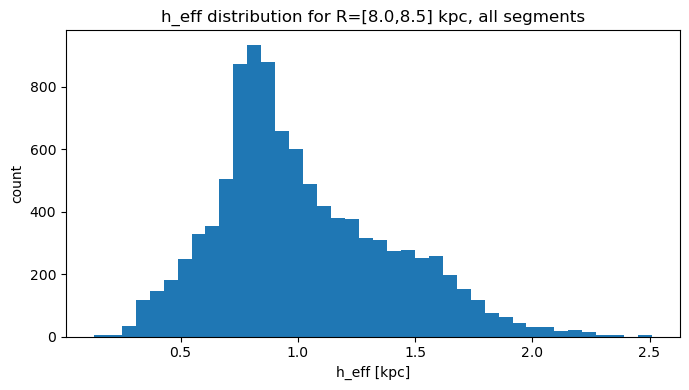

mean = 1.020 kpc
std  = 0.373 kpc


In [155]:
# pick all cells in the R=8-8.5 kpc bin
i_R_focus = np.searchsorted(R_edges, 8.0)

h_effs_all = []

for j_seg in range(n_seg):
    if (i_R_focus, j_seg) not in per_cell:
        continue
    cell = per_cell[(i_R_focus, j_seg)]
    s = cell["samples"]
    n_draws = min(1000, len(s["A1"]))
    
    for i in range(n_draws):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        result = root(root_func, x0=cell_sample["z0"] + 1e-3, args=(cell_sample,))
        if result.success:
            h_effs_all.append(np.abs(result.x[0] - cell_sample["z0"]))

h_effs_all = np.array(h_effs_all)

plt.figure(figsize=(7, 4))
plt.hist(h_effs_all, bins=40)
plt.xlabel("h_eff [kpc]")
plt.ylabel("count")
plt.title(f"h_eff distribution for R=[{R_edges[i_R_focus]:.1f},{R_edges[i_R_focus+1]:.1f}] kpc, all segments")
plt.tight_layout()
plt.show()

print(f"mean = {np.mean(h_effs_all):.3f} kpc")
print(f"std  = {np.std(h_effs_all):.3f} kpc")

computing h_eff: 100%|████████████████████████| 206/206 [06:22<00:00,  1.86s/it]


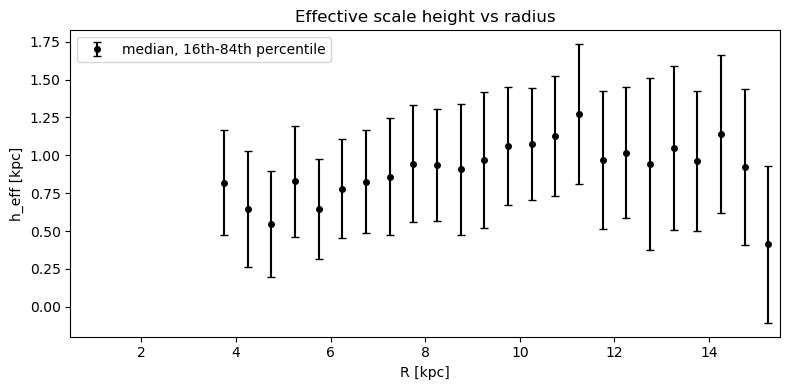

In [156]:
# collect all h_eff samples per R bin across all segments
h_effs_per_R = {i: [] for i in range(n_R)}

for (i_R, j_seg), cell in tqdm(per_cell.items(), desc="computing h_eff"):
    s = cell["samples"]
    for i in range(min(1000, len(s["A1"]))):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        result = root(root_func, x0=cell_sample["z0"] + 1e-3, args=(cell_sample,))
        if result.success:
            h_effs_per_R[i_R].append(np.abs(result.x[0] - cell_sample["z0"]))

# compute median and percentile error bars
R_centers = 0.5 * (R_edges[:-1] + R_edges[1:])
h_eff_med_R = np.full(n_R, np.nan)
h_eff_err_R = np.full(n_R, np.nan)

for i_R, h_effs in h_effs_per_R.items():
    if len(h_effs) > 0:
        h_effs_arr = np.array(h_effs)
        h_eff_med_R[i_R] = np.median(h_effs_arr)
        pcl = np.percentile(h_effs_arr, [16, 84])
        h_eff_err_R[i_R] = 0.5 * (pcl[1] - pcl[0])

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(R_centers, h_eff_med_R, yerr=h_eff_err_R,
            fmt="o", color="k", ms=4, capsize=3,
            label="median, 16th-84th percentile")
ax.set_xlabel("R [kpc]")
ax.set_ylabel("h_eff [kpc]")
ax.set_title("Effective scale height vs radius")
ax.set_xlim(R_edges[0], R_edges[-1])
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

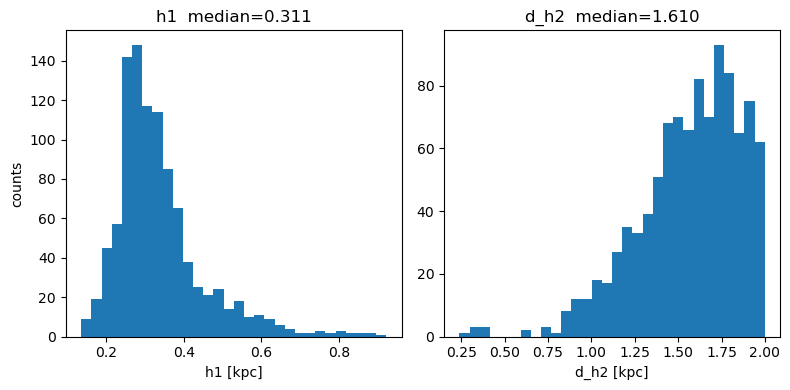

In [178]:
cell = per_cell[(i_R_focus, cells_in_R[2][1])]
s = cell["samples"]

fig, axes = plt.subplots(1, 2, figsize=(8, 4))


axes[0].hist(s["h1"], bins=30)
axes[0].set_xlabel("h1 [kpc]")
axes[0].set_ylabel("counts")
axes[0].set_title(f"h1  median={np.median(s['h1']):.3f}")

axes[1].hist(s["d_h2"], bins=30)
axes[1].set_xlabel("d_h2 [kpc]")
axes[1].set_title(f"d_h2  median={np.median(s['d_h2']):.3f}")

plt.tight_layout()
plt.show()

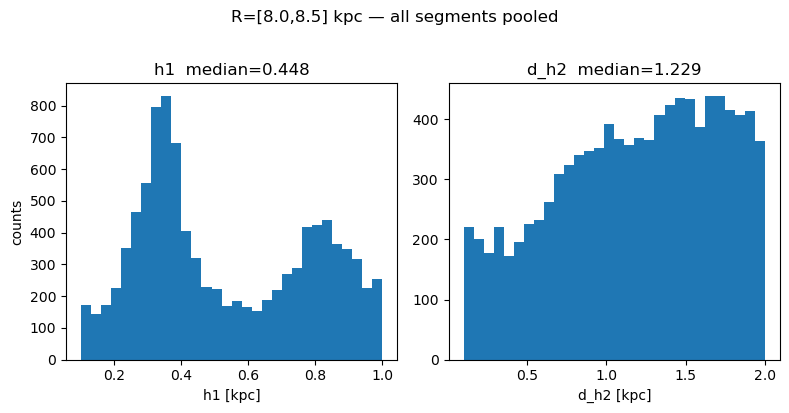

In [181]:
i_R_focus = np.searchsorted(R_edges, 8.0)
cells_in_R = [(i_R, j_seg) for (i_R, j_seg) in per_cell.keys() if i_R == i_R_focus]

h1_all = []
d_h2_all = []

for (i_R, j_seg) in cells_in_R:
    s = per_cell[(i_R, j_seg)]["samples"]
    h1_all.append(s["h1"])
    d_h2_all.append(s["d_h2"])

h1_all = np.concatenate(h1_all)
d_h2_all = np.concatenate(d_h2_all)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].hist(h1_all, bins=30)
axes[0].set_xlabel("h1 [kpc]")
axes[0].set_ylabel("counts")
axes[0].set_title(f"h1  median={np.median(h1_all):.3f}")

axes[1].hist(d_h2_all, bins=30)
axes[1].set_xlabel("d_h2 [kpc]")
axes[1].set_title(f"d_h2  median={np.median(d_h2_all):.3f}")

plt.suptitle("R=[8.0,8.5] kpc — all segments pooled", y=1.02)
plt.tight_layout()
plt.show()

In [23]:
import ipywidgets as widgets
from IPython.display import display, clear_output

PAGE_ROWS, PAGE_COLS = 2, 2
PAGE_SIZE = PAGE_ROWS * PAGE_COLS    # 4 per page

cells_ok = sorted(per_cell.keys())
n_pages  = (len(cells_ok) + PAGE_SIZE - 1) // PAGE_SIZE

out = widgets.Output()
prev_btn  = widgets.Button(description="◀ Prev", layout=widgets.Layout(width="80px"))
next_btn  = widgets.Button(description="Next ▶", layout=widgets.Layout(width="80px"))
page_lbl  = widgets.Label(value="")
state     = {"page": 0}

def render():
    page_idx = state["page"]
    page_lbl.value = f"page {page_idx + 1} / {n_pages}"
    prev_btn.disabled = (page_idx == 0)
    next_btn.disabled = (page_idx >= n_pages - 1)

    with out:
        clear_output(wait=True)
        start = page_idx * PAGE_SIZE
        end   = min(start + PAGE_SIZE, len(cells_ok))

        fig, axes = plt.subplots(PAGE_ROWS, PAGE_COLS, figsize=(12, 8), squeeze=False)
        z_grid = np.linspace(-5, 5, 1000)

        for slot in range(PAGE_SIZE):
            r, c = divmod(slot, PAGE_COLS)
            ax = axes[r, c]
            k_idx = start + slot
            if k_idx >= len(cells_ok):
                ax.axis("off")
                continue

            i_R, j_seg = cells_ok[k_idx]
            cell   = per_cell[(i_R, j_seg)]
            seg_id = SEG_PLOT_heat[j_seg]
            Rmin, Rmax = R_edges[i_R], R_edges[i_R + 1]

            ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
                        color="C2", linestyle="", marker=".")

            s = cell["samples"]
            for i in range(min(100, len(s["A1"]))):
                A1 = s["A1"][i]; A2 = s["A2"][i]
                h1 = s["h1"][i]; h2 = h1 + s["d_h2"][i]
                z0 = s["z0"][i]; off = s["offset"][i]
                y_pred = mixture_of_sech2(z_grid, A1, A2, h1, h2, z0) + off
                ax.plot(z_grid, y_pred, color="C1", alpha=0.1, marker="")

            ax.set_xlabel("z"); ax.set_ylabel("[Mg/Fe]")
            ax.set_title(
                f"segment {seg_id}, R=[{Rmin:.1f},{Rmax:.1f}] kpc\n"
                f"z0 = {z0_med[i_R,j_seg]:+.3f} ± {z0_std[i_R,j_seg]:.3f}"
            )
        plt.tight_layout(); plt.show()

def on_prev(_):
    if state["page"] > 0:
        state["page"] -= 1
        render()

def on_next(_):
    if state["page"] < n_pages - 1:
        state["page"] += 1
        render()

prev_btn.on_click(on_prev)
next_btn.on_click(on_next)

controls = widgets.HBox([prev_btn, page_lbl, next_btn])
display(controls, out)
render()

Output()

stars in cell: 1210


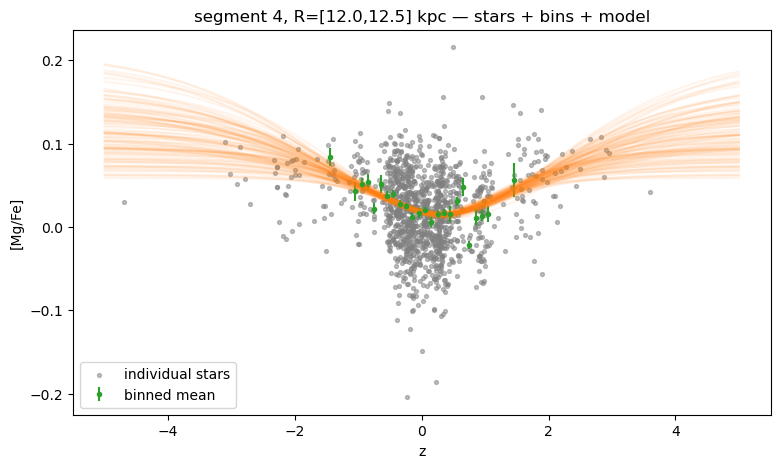

In [24]:
# ---- pick the cell ----
seg_id = 4
Rmin_focus, Rmax_focus = 12.0, 12.5
i_R   = np.searchsorted(R_edges, Rmin_focus)             # index into R_edges
j_seg = SEG_PLOT_heat.index(seg_id)

# ---- stars in this (annulus, segment) ----
m_cell = (
    segm[seg_id]
    & (R_star >= Rmin_focus) & (R_star < Rmax_focus)
    & np.isfinite(Z_star) & np.isfinite(mgfe_star)
    & np.isfinite(mgfe_err_star) & (mgfe_err_star > 0)
)
print(f"stars in cell: {int(m_cell.sum())}")

z_cell    = np.asarray(Z_star)[m_cell]
mgfe_cell = np.asarray(mgfe_star)[m_cell]
err_cell  = np.asarray(mgfe_err_star)[m_cell]
t_cell    = t_star[m_cell]

# ---- scatter of individual stars + binned means + model ----
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(z_cell, mgfe_cell, s=8, color="gray", alpha=0.5, label="individual stars")
ax.errorbar(per_cell[(i_R, j_seg)]["z_binc"],
            per_cell[(i_R, j_seg)]["mean"],
            yerr=per_cell[(i_R, j_seg)]["err"],
            color="C2", linestyle="", marker=".", label="binned mean")

z_grid = np.linspace(-5, 5, 1000)
s = per_cell[(i_R, j_seg)]["samples"]
for i in range(min(100, len(s["A1"]))):
    y_pred = mixture_of_sech2(z_grid, s["A1"][i], s["A2"][i],
                              s["h1"][i], s["h1"][i] + s["d_h2"][i],
                              s["z0"][i]) + s["offset"][i]
    ax.plot(z_grid, y_pred, color="C1", alpha=0.08, marker="")

ax.set_xlabel("z"); ax.set_ylabel("[Mg/Fe]")
ax.set_title(f"segment {seg_id}, R=[{Rmin_focus},{Rmax_focus}] kpc — stars + bins + model")
ax.legend(); plt.show()

stars in cell: 19662


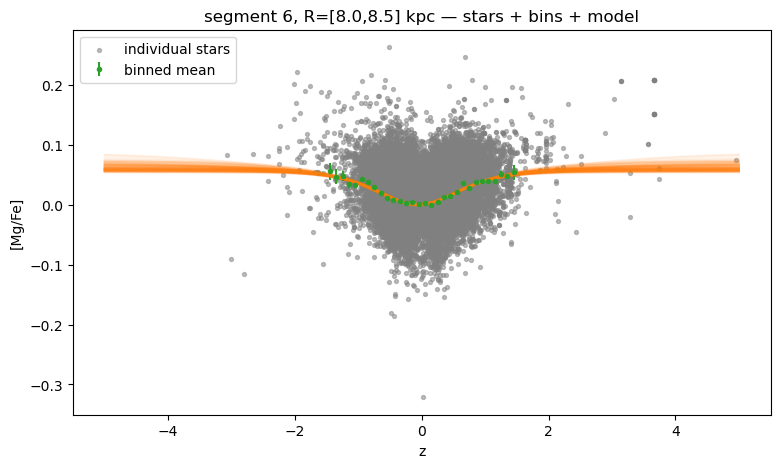

In [80]:
# ---- pick the cell ----
seg_id = 6
Rmin_focus, Rmax_focus = 8.0, 8.5
i_R   = np.searchsorted(R_edges, Rmin_focus)             # index into R_edges
j_seg = SEG_PLOT_heat.index(seg_id)

# ---- stars in this (annulus, segment) ----
m_cell = (
    segm[seg_id]
    & (R_star >= Rmin_focus) & (R_star < Rmax_focus)
    & np.isfinite(Z_star) & np.isfinite(mgfe_star)
    & np.isfinite(mgfe_err_star) & (mgfe_err_star > 0)
)
print(f"stars in cell: {int(m_cell.sum())}")

z_cell    = np.asarray(Z_star)[m_cell]
mgfe_cell = np.asarray(mgfe_star)[m_cell]
err_cell  = np.asarray(mgfe_err_star)[m_cell]
t_cell    = t_star[m_cell]

# ---- scatter of individual stars + binned means + model ----
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(z_cell, mgfe_cell, s=8, color="gray", alpha=0.5, label="individual stars")
ax.errorbar(per_cell[(i_R, j_seg)]["z_binc"],
            per_cell[(i_R, j_seg)]["mean"],
            yerr=per_cell[(i_R, j_seg)]["err"],
            color="C2", linestyle="", marker=".", label="binned mean")

z_grid = np.linspace(-5, 5, 1000)
s = per_cell[(i_R, j_seg)]["samples"]
for i in range(min(100, len(s["A1"]))):
    y_pred = mixture_of_sech2(z_grid, s["A1"][i], s["A2"][i],
                              s["h1"][i], s["h1"][i] + s["d_h2"][i],
                              s["z0"][i]) + s["offset"][i]
    ax.plot(z_grid, y_pred, color="C1", alpha=0.08, marker="")

ax.set_xlabel("z"); ax.set_ylabel("[Mg/Fe]")
ax.set_title(f"segment {seg_id}, R=[{Rmin_focus},{Rmax_focus}] kpc — stars + bins + model")
ax.legend(); plt.show()

In [48]:
!pip install emcee

/Users/emmatasso/miniforge3/lib/python3.12/pty.py:95: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()



[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: pip install --upgrade pip


R=[3,4)  n_bins=11
R=[4,5)  n_bins=12
R=[5,6)  n_bins=15
R=[6,7)  n_bins=18
R=[7,8)  n_bins=17
R=[8,9)  n_bins=20
R=[9,10)  n_bins=19
R=[10,11)  n_bins=19
R=[11,12)  n_bins=18
R=[12,13)  n_bins=20
R=[13,14)  n_bins=20
R=[14,15)  n_bins=21
R=[15,16)  n_bins=22

fitting R=[3,4) kpc  n_bins=11…


/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_29533/2519544053.py:112: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc   = MCMC(kernel, num_warmup=500, num_samples=1000,
sample: 100%|█| 1500/1500 [00:05<00:00, 264.22it/s, 127 steps of size 2.11e-02. 
sample: 100%|█| 1500/1500 [00:04<00:00, 307.39it/s, 191 steps of size 2.11e-02. 


fitting R=[4,5) kpc  n_bins=12…



sample: 100%|█| 1500/1500 [00:06<00:00, 221.19it/s, 231 steps of size 8.19e-03. 
sample: 100%|█| 1500/1500 [00:06<00:00, 237.67it/s, 255 steps of size 1.34e-02. 


fitting R=[5,6) kpc  n_bins=15…


...


fitting R=[14,15) kpc  n_bins=21…



sample: 100%|█| 1500/1500 [00:05<00:00, 257.27it/s, 255 steps of size 1.56e-02. 
sample: 100%|█| 1500/1500 [00:04<00:00, 301.80it/s, 255 steps of size 2.14e-02. 


fitting R=[15,16) kpc  n_bins=22…



sample: 100%|█| 1500/1500 [00:03<00:00, 411.90it/s, 127 steps of size 4.29e-02. 
sample: 100%|█| 1500/1500 [00:03<00:00, 410.86it/s, 127 steps of size 3.72e-02. 


saved → sech2_numpyro_flare_results.pkl


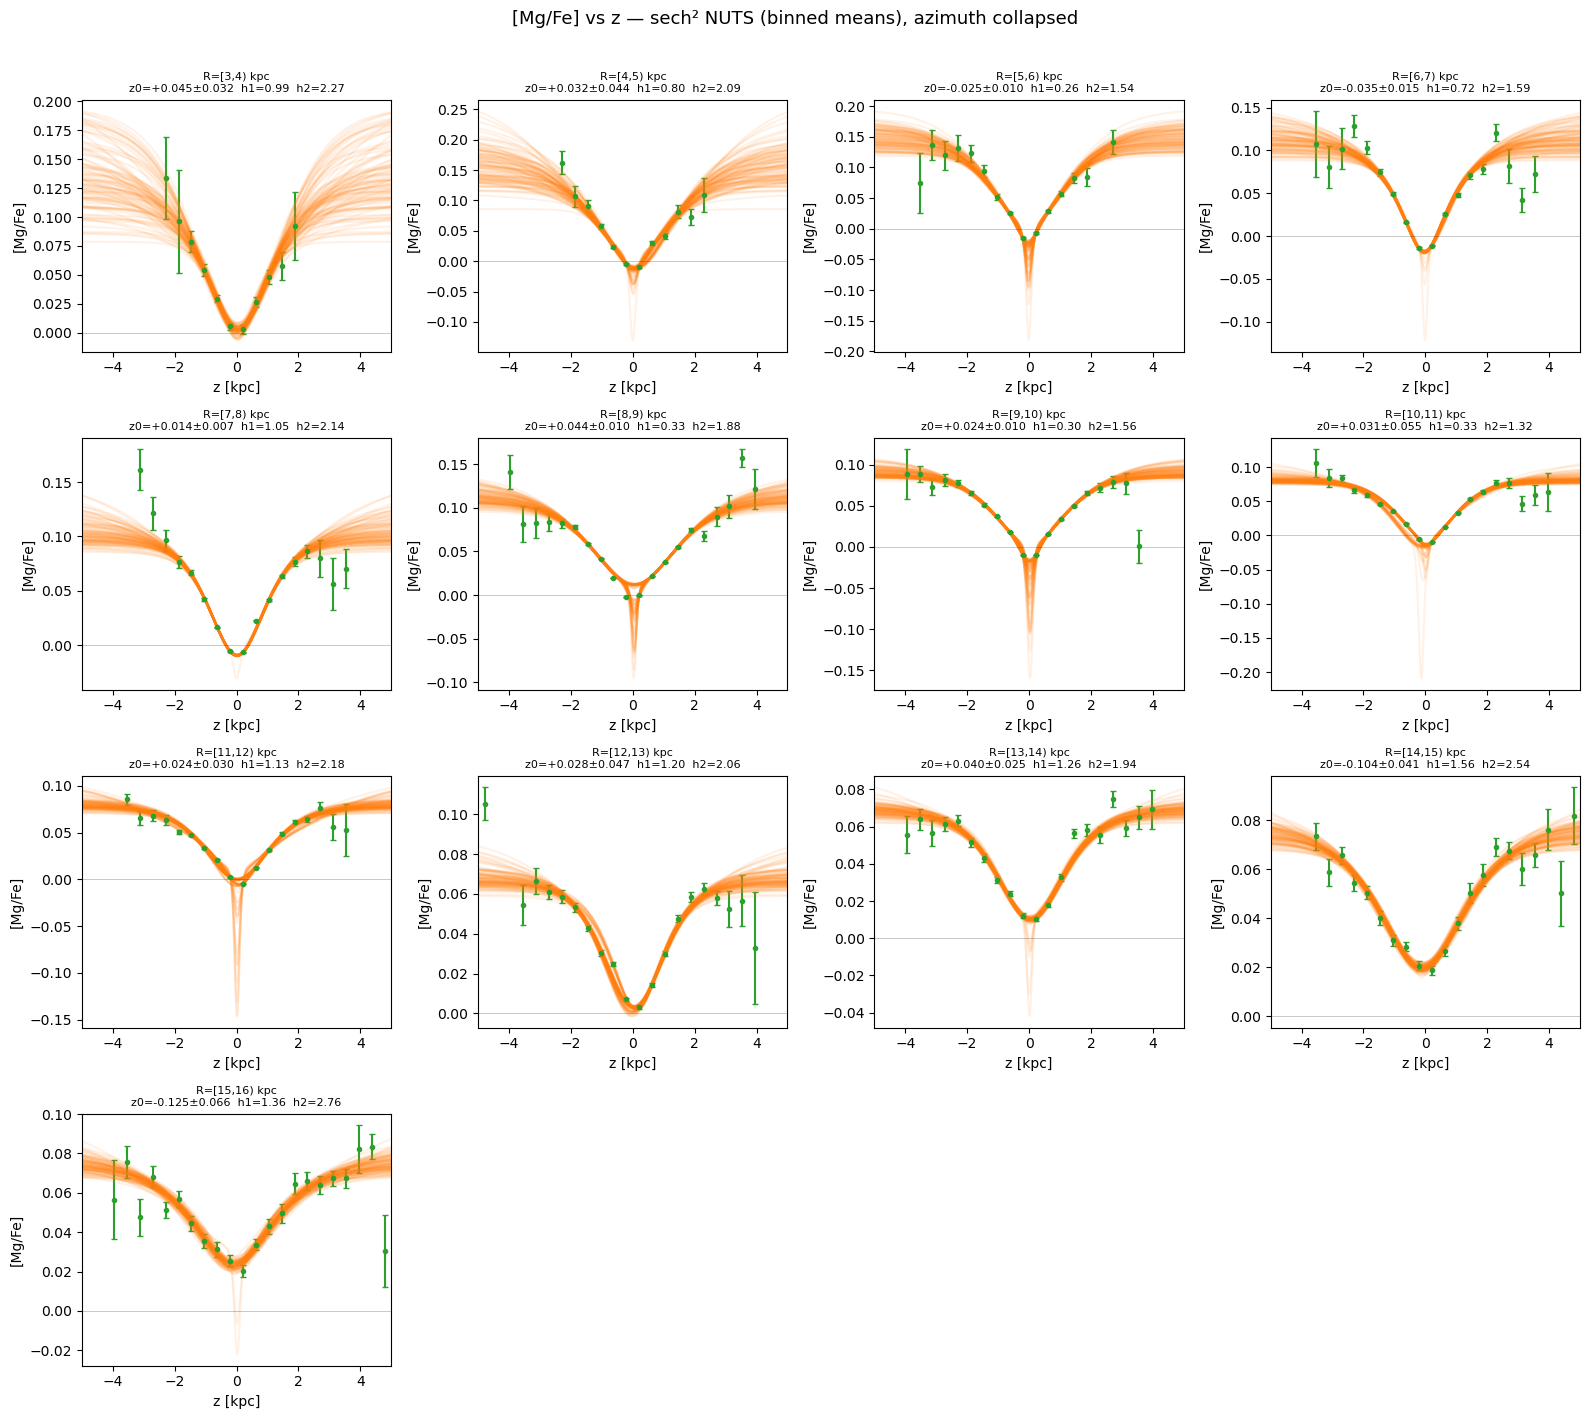

In [79]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS

# ── 1. build binned data ──────────────────────────────────────────────────────
R_edges_flare = np.arange(3, 17, 1)
n_Rbins       = len(R_edges_flare) - 1

z_bins = np.linspace(-5, 5, 25)
z_binc = 0.5 * (z_bins[:-1] + z_bins[1:])

R_arr        = np.asarray(R_star)
Z_arr        = np.asarray(Z_star)
mgfe_arr     = np.asarray(mgfe_star)
mgfe_err_arr = np.asarray(mgfe_err_star)

m_base = (
    np.isfinite(R_arr) & np.isfinite(Z_arr)
    & np.isfinite(mgfe_arr) & np.isfinite(mgfe_err_arr)
    & (mgfe_err_arr > 0)
)

per_R = {}
for i in range(n_Rbins):
    Rlo, Rhi = R_edges_flare[i], R_edges_flare[i + 1]
    m = m_base & (R_arr >= Rlo) & (R_arr < Rhi)

    means, errs = [], []
    for j in range(len(z_bins) - 1):
        mz = m & (Z_arr >= z_bins[j]) & (Z_arr < z_bins[j + 1])
        n  = mz.sum()
        if n >= 5:
            vals = mgfe_arr[mz]
            means.append(np.mean(vals))
            errs.append(np.std(vals) / np.sqrt(n))
        else:
            means.append(np.nan)
            errs.append(np.nan)

    mean_arr = np.array(means)
    err_arr  = np.array(errs)
    ok       = np.isfinite(mean_arr) & np.isfinite(err_arr) & (err_arr > 0)

    per_R[i] = dict(
        Rlo=Rlo, Rhi=Rhi,
        z=jnp.array(z_binc[ok]),
        mg_fe=jnp.array(mean_arr[ok]),
        mg_fe_err=jnp.array(err_arr[ok]),
    )
    print(f"R=[{Rlo:.0f},{Rhi:.0f})  n_bins={ok.sum()}")

# ── 2. model — simple Gaussian likelihood on binned means ─────────────────────
def mixture_of_sech2(z, A1, A2, h1, h2, z0):
    return A1 / jnp.cosh((z - z0) / h1)**2 + A2 / jnp.cosh((z - z0) / h2)**2

def model(data):
    # amplitudes: dip depth in [Mg/Fe] is ~0.05–0.15 dex, not order unity
    #A1 = numpyro.sample("A1", dist.TruncatedNormal(-0.05, 0.10, low=None, high=0.0))
    #A2 = numpyro.sample("A2", dist.TruncatedNormal(-0.05, 0.10, low=None, high=0.0))
    _A1 = numpyro.sample("_A1", dist.HalfNormal(0.1))
    _A2 = numpyro.sample("_A2", dist.HalfNormal(0.1))
    A1 = numpyro.deterministic("A1", -_A1)
    A2 = numpyro.deterministic("A2", -_A2)

    # scale heights: thin disk ~0.3 kpc, thick disk ~0.9 kpc, so cap h2 at ~3 kpc
    h1   = numpyro.sample("h1",   dist.Uniform(0.1, 2.0))
    d_h2 = numpyro.sample("d_h2", dist.Uniform(0.1, 3.0))     # was Uniform(0.1, 20)
    h2 = h1 + d_h2

    # midplane location: real warp amplitudes ~0.1–0.3 kpc, so 0.5 kpc is plenty
    z0 = numpyro.sample("z0", dist.Normal(0.0, 0.4))           # was Normal(0, 1)

    # baseline: [Mg/Fe] for low-α giants sits ~0.05 dex, with stddev ~0.1 dex
    offset = numpyro.sample("offset", dist.Normal(0.05, 0.10))  # was Normal(0, 5)

    model_y = mixture_of_sech2(data["z"], A1, A2, h1, h2, z0) + offset
    # numpyro.sample("obs", dist.Normal(model_y, data["mg_fe_err"]), obs=data["mg_fe"])

    Q = numpyro.sample("Q", dist.Beta(1.0, 9.0))
    mix = dist.Categorical(probs=jnp.array([Q, 1.0 - Q]))
    components = [
        dist.Normal(0.0, jnp.sqrt(1.0**2 + data["mg_fe_err"]**2)),
        dist.Normal(model_y, data["mg_fe_err"]),
    ]

    numpyro.sample(
        "obs",
        dist.Mixture(mix, components),
        obs=data["mg_fe"],
    ) 
# ── 3. run NUTS ───────────────────────────────────────────────────────────────
numpyro.set_host_device_count(1)
rng_key = jax.random.PRNGKey(42)

per_R_samples = {}

for i, cell in per_R.items():
    print(f"\nfitting R=[{cell['Rlo']:.0f},{cell['Rhi']:.0f}) kpc  "
          f"n_bins={len(cell['z'])}…", flush=True)

    if len(cell["z"]) < 6:
        print("  skipping — too few bins")
        continue

    rng_key, subkey = jax.random.split(rng_key)
    kernel = NUTS(model)
    mcmc   = MCMC(kernel, num_warmup=500, num_samples=1000,
                  num_chains=2, progress_bar=True)
    mcmc.run(subkey, data=cell)

    samples = mcmc.get_samples()
    per_R_samples[i] = {k: np.array(v) for k, v in samples.items()}

# ── 4. save ───────────────────────────────────────────────────────────────────
with open("sech2_numpyro_flare_results.pkl", "wb") as f:
    pickle.dump(dict(per_R=per_R, per_R_samples=per_R_samples), f)
print("saved → sech2_numpyro_flare_results.pkl")

# ── 5. summary arrays ─────────────────────────────────────────────────────────
z0_med_R = np.full(n_Rbins, np.nan)
z0_std_R = np.full(n_Rbins, np.nan)
h1_med_R = np.full(n_Rbins, np.nan)
h2_med_R = np.full(n_Rbins, np.nan)

for i, s in per_R_samples.items():
    z0_med_R[i] = np.median(s["z0"])
    z0_std_R[i] = np.std(s["z0"])
    h1_med_R[i] = np.median(s["h1"])
    h2_med_R[i] = np.median(s["h1"] + s["d_h2"])

# ── 6. plot ───────────────────────────────────────────────────────────────────
z_grid    = np.linspace(-5, 5, 500)
PAGE_COLS = 4
PAGE_ROWS = int(np.ceil(n_Rbins / PAGE_COLS))

fig, axes = plt.subplots(PAGE_ROWS, PAGE_COLS,
                          figsize=(PAGE_COLS * 4, PAGE_ROWS * 3.5),
                          squeeze=False)

for i in range(n_Rbins):
    r, c  = divmod(i, PAGE_COLS)
    ax    = axes[r, c]
    cell  = per_R[i]

    ax.errorbar(np.array(cell["z"]), np.array(cell["mg_fe"]),
                yerr=np.array(cell["mg_fe_err"]),
                color="C2", marker=".", linestyle="", capsize=2)

    if i in per_R_samples:
        s   = per_R_samples[i]
        idx = np.random.choice(len(s["z0"]), size=min(100, len(s["z0"])), replace=False)
        for k in idx:
            h1 = s["h1"][k]; h2 = h1 + s["d_h2"][k]
            y  = mixture_of_sech2(z_grid, s["A1"][k], s["A2"][k],
                                   h1, h2, s["z0"][k]) + s["offset"][k]
            ax.plot(z_grid, y, color="C1", alpha=0.1)

        ax.set_title(
            f"R=[{cell['Rlo']:.0f},{cell['Rhi']:.0f}) kpc\n"
            f"z0={z0_med_R[i]:+.3f}±{z0_std_R[i]:.3f}  "
            f"h1={h1_med_R[i]:.2f}  h2={h2_med_R[i]:.2f}",
            fontsize=8,
        )
    else:
        ax.set_title(f"R=[{cell['Rlo']:.0f},{cell['Rhi']:.0f}) kpc\n(skipped)", fontsize=8)

    ax.axhline(0, color="k", lw=0.5, alpha=0.3)
    ax.set_xlabel("z [kpc]")
    ax.set_ylabel("[Mg/Fe]")
    ax.set_xlim(-5, 5)

for i in range(n_Rbins, PAGE_ROWS * PAGE_COLS):
    r, c = divmod(i, PAGE_COLS)
    axes[r, c].axis("off")

plt.suptitle("[Mg/Fe] vs z — sech² NUTS (binned means), azimuth collapsed",
             y=1.01, fontsize=13)
plt.tight_layout()
plt.show()



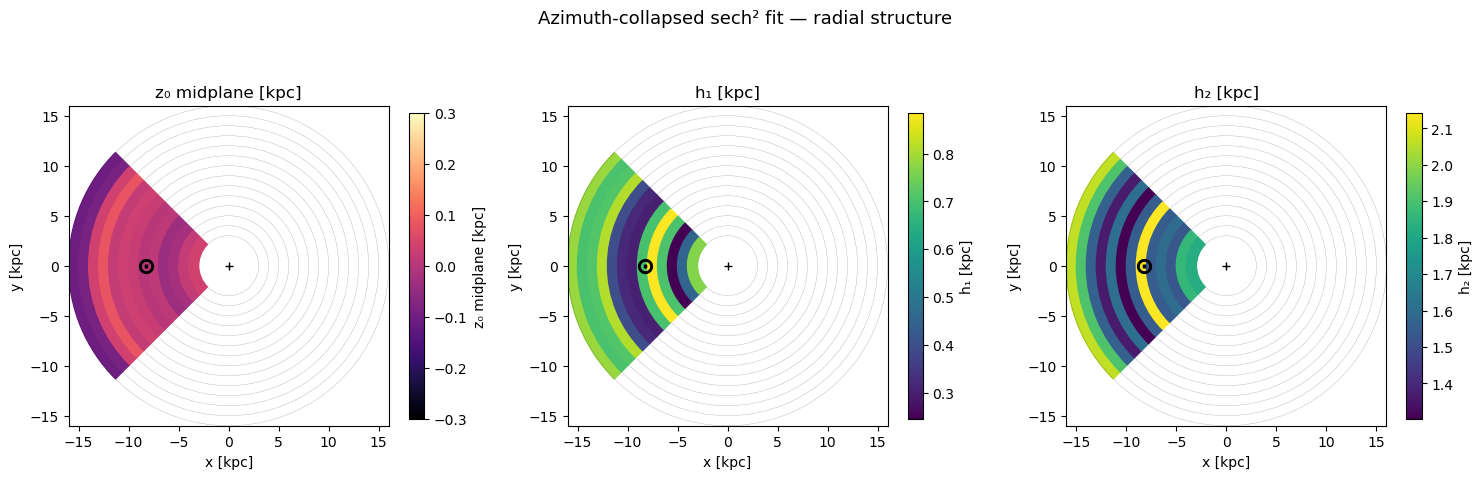

In [76]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Wedge
import numpy as np

R_centers = 0.5 * (R_edges_flare[:-1] + R_edges_flare[1:])

quantities = [
    (z0_med_R, "z₀ midplane [kpc]", "magma",  (-0.3, 0.3)),
    (h1_med_R, "h₁ [kpc]",     "viridis",  None),
    (h2_med_R, "h₂ [kpc]",    "viridis",  None),
]

# phi_star is already in radians — convert to degrees
phi_arr  = np.degrees(np.asarray(phi_star)) % 360
R_arr_np = np.asarray(R_star)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (vals, label, cmap, vlims) in zip(axes, quantities):
    finite = vals[np.isfinite(vals)]
    if vlims is None:
        vmin, vmax = np.nanmin(finite), np.nanmax(finite)
    else:
        vmin, vmax = vlims

    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
    sm   = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])

    # only show the azimuthal range that matches your existing polar heatmaps
    phi_lo, phi_hi = 135, 225
    
    for i in reversed(range(n_Rbins)):
        val = vals[i]
        if not np.isfinite(val):
            continue
        Rlo = R_edges_flare[i]
        Rhi = R_edges_flare[i + 1]
        color = sm.to_rgba(val)
    
        # restrict to the phi window of interest
        m_ring = m_base & (R_arr_np >= Rlo) & (R_arr_np < Rhi)
        if m_ring.sum() == 0:
            continue
    
        # just draw one wedge covering the fixed phi range
        w = Wedge(
            center=(0, 0), r=Rhi,
            theta1=phi_lo, theta2=phi_hi,
            width=Rhi - Rlo,
            color=color, zorder=n_Rbins - i,
        )
        ax.add_patch(w)
    # grid circles
    for R in R_edges_flare:
        ax.add_patch(plt.Circle((0, 0), R, color="k", fill=False, lw=0.3, alpha=0.3))

    ax.plot(-8.275, 0, marker=r"$\odot$", color="k", ms=10, zorder=99)
    ax.plot(0, 0, "+", color="k", ms=6, zorder=99)
    ax.set_xlim(-16, 16)
    ax.set_ylim(-16, 16)
    ax.set_aspect("equal")
    ax.set_xlabel("x [kpc]")
    ax.set_ylabel("y [kpc]")
    ax.set_title(label)
    plt.colorbar(sm, ax=ax, label=label, shrink=0.7)

plt.suptitle("Azimuth-collapsed sech² fit — radial structure", fontsize=13)
plt.tight_layout()
plt.show()

In [25]:
# ----- pick the cell and the clump within it -----
seg_id = 4
Rmin_focus, Rmax_focus = 12.0, 12.5

# circled dip region — adjust if you want a wider/narrower box
z_lo, z_hi   = 0.6, 0.8
mgfe_max     = 0.0     # only stars below this in [Mg/Fe]

m_clump = (
    segm[seg_id]
    & (R_star >= Rmin_focus) & (R_star < Rmax_focus)
    & np.isfinite(Z_star) & np.isfinite(mgfe_star)
    & (Z_star >= z_lo) & (Z_star < z_hi)
    & (mgfe_star <= mgfe_max)
)
t_clump    = t_star[m_clump]
z_clump    = np.asarray(Z_star)[m_clump]
mgfe_clump = np.asarray(mgfe_star)[m_clump]

print(f"stars in the clump (seg {seg_id}, R=[{Rmin_focus},{Rmax_focus}], "
      f"z∈[{z_lo},{z_hi}], [Mg/Fe]≤{mgfe_max}): {len(t_clump)}")

# ----- flag columns to inspect -----
flag_cols = [
    "sdss5_target_flags",
    "sdss4_apogee_target1_flags",
    "sdss4_apogee_target2_flags",
    "sdss4_apogee2_target1_flags",
    "sdss4_apogee2_target2_flags",
    "sdss4_apogee2_target3_flags",
    "sdss4_apogee_member_flags",
    "sdss4_apogee_extra_target_flags",
]

# warn about missing columns up front
missing = [c for c in flag_cols if c not in t_clump.colnames]
present = [c for c in flag_cols if c in t_clump.colnames]
if missing:
    print(f"\n(note) columns not in t_star: {missing}")

# ----- loop through each star, print the flag values -----
for i, star in enumerate(t_clump):
    sid = star["sdss4_apogee_id"] if "sdss4_apogee_id" in t_clump.colnames else "?"
    print(f"\n--- star {i+1}/{len(t_clump)}   "
          f"id={sid}   z={z_clump[i]:+.3f}   [Mg/Fe]={mgfe_clump[i]:+.4f} ---")
    for col in present:
        val = star[col]
        # try to render as integer bitmask if it is one
        try:
            print(f"  {col:>34} : {int(val):>20d}   (bin: {int(val):020b})")
        except (TypeError, ValueError):
            print(f"  {col:>34} : {val}")

stars in the clump (seg 4, R=[12.0,12.5], z∈[0.6,0.8], [Mg/Fe]≤0.0): 9

--- star 1/9   id=-1   z=+0.746   [Mg/Fe]=-0.0133 ---
                  sdss5_target_flags : [ 0  0  0  1  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0 16  0  0  0  0  0  0  0  8  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  8  0  0  0  0  0  0  0  0  0  0  0  0  0  4  0  0  0]
          sdss4_apogee_target1_flags :                    0   (bin: 00000000000000000000)
          sdss4_apogee_target2_flags :                    0   (bin: 00000000000000000000)
         sdss4_apogee2_target1_flags :                    0   (bin: 00000000000000000000)
         sdss4_apogee2_target2_flags :                    0   (bin: 00000000000000000000)
         sdss4_apogee2_target3_flags :                    0   (bin: 00000000000000000000)
           sdss4_apogee_member_flags :                    0   (bin: 00000000000000000000)
     sdss4_apogee_extra_target_flags :                    0   (bin: 0000000000

In [28]:
from sdss_semaphore.targeting import TargetingFlags
flags = TargetingFlags(t_clump["sdss5_target_flags"][0])

print("type:", type(flags))
print("\nrepr:", repr(flags))
print("\nstr:", str(flags))
print("\npublic methods/attrs:")
for name in dir(flags):
    if not name.startswith("_"):
        print(f"  {name}")

type: <class 'sdss_semaphore.targeting.TargetingFlags'>

repr: <TargetingFlags with 1 items and up to 568 flags (563 defined) at 0x17a9843b0>

str: <TargetingFlags with 1 items and up to 568 flags (563 defined) at 0x17a9843b0>

public methods/attrs:
  MAPPING_BASENAME
  MAPPING_PATH
  all_alt_carton_names
  all_alt_programs
  all_carton_names
  all_mappers
  all_programs
  are_all_bits_set
  are_any_bits_set
  array
  as_boolean_array
  bit_position_from_carton_pk
  bits_set
  clear_bit
  count
  count_by_attribute
  dtype
  flags_set
  get_alt_name
  get_alt_program
  get_attribute
  get_bits_with_attribute
  get_carton_label
  get_carton_name
  get_carton_pk
  get_mapper
  get_program
  in_alt_name
  in_alt_program
  in_carton_label
  in_carton_name
  in_carton_pk
  in_mapper
  in_program
  is_attribute_set
  is_bit_set
  mapping
  n_bits
  set_bit
  set_bit_by_carton_pk
  set_version
  shrink
  toggle_bit
  version


In [29]:
flags = TargetingFlags(t_clump["sdss5_target_flags"][0])
print(flags.all_carton_names)

(np.str_('manual_mwm_halo_mp_wise_apogee'), np.str_('manual_bhm_spiders_comm'), np.str_('ops_sky_apogee'), np.str_('openfibertargets_mwm_lvm_smc_boss'), np.str_('openfibertargets_nov2020_10'), np.str_('mwm_legacy_ir2opt_boss'), np.str_('openfibertargets_nov2020_9'), np.str_('openfibertargets_mwm_halo_gaiastreams_boss'), np.str_('openfibertargets_nov2020_47e'), np.str_('mwm_halo_distant_rrl_boss'), np.str_('ops_std_boss_lsdr8'), np.str_('mwm_cb_gaiagalex_boss'), np.str_('openfibertargets_mwm_protoclusters_apogee'), np.str_('mwm_cb_uvex1'), np.str_('mwm_bin_gaia_astb_boss'), np.str_('mwm_halo_nmp_xp_boss'), np.str_('mwm_yso_embedded_apogee_single'), np.str_('mwm_halo_bb_boss'), np.str_('mwm_bin_vis_boss'), np.str_('openfibertargets_mwm_ztf_lomb_apogee'), np.str_('mwm_cb_cvcandidates'), np.str_('openfibertargets_mwm_cvcandidates_boss'), np.str_('mwm_yso_cmz'), np.str_('mwm_yso_ob_boss'), np.str_('bhm_spiders_agn_supercosmos'), np.str_('openfibertargets_nov2020_34b'), np.str_('mwm_rv_long-

In [30]:
flags = TargetingFlags(t_clump["sdss5_target_flags"][0])
print(flags.get_carton_name())

([np.str_('mwm_gg_core'), np.str_('mwm_galactic_core'), np.str_('openfibertargets_nov2020_34a'), np.str_('openfibertargets_nov2020_34a'), np.str_('mwm_galactic_core_dist_apogee'), np.str_('mwm_galactic_core_dist_apogee_sparse')],)


In [31]:
from collections import Counter
from sdss_semaphore.targeting import TargetingFlags

flags = TargetingFlags(t_clump["sdss5_target_flags"])   # all 32 stars
all_cartons = flags.get_carton_name()                   # tuple-of-tuples, one per star

carton_counts = Counter()
for star_cartons in all_cartons:
    for name in star_cartons:
        carton_counts[name] += 1

for name, n in carton_counts.most_common():
    print(f"  {n:>3d}  {name}")

   16  openfibertargets_nov2020_34a
   10  mwm_rv_short_fps
    8  mwm_galactic_core_dist_apogee
    7  mwm_gg_core
    7  mwm_galactic_core
    5  mwm_rv_short-fps
    4  mwm_galactic_core_dist_apogee_sparse
    4  mwm_galactic_core_dist_apogee_extra
    4  mwm_tess_rgb_apogee
    3  mwm_bin_rv_short_rgb_apogee
    2  mwm_legacy_ir2opt
    1  mwm_legacy_ir2opt_boss


In [32]:
print(flags.count_by_attribute("name"))

{np.str_('na'): np.int64(0), np.str_('mwm_snc_100pc'): np.int64(0), np.str_('mwm_snc_250pc'): np.int64(0), np.str_('mwm_cb_300pc'): np.int64(0), np.str_('mwm_cb_cvcandidates'): np.int64(0), np.str_('mwm_halo_sm'): np.int64(0), np.str_('mwm_halo_bb'): np.int64(0), np.str_('mwm_yso_s1'): np.int64(0), np.str_('mwm_yso_s2'): np.int64(0), np.str_('mwm_yso_s2-5'): np.int64(0), np.str_('mwm_yso_s3'): np.int64(0), np.str_('mwm_yso_ob'): np.int64(0), np.str_('mwm_yso_cmz'): np.int64(0), np.str_('mwm_yso_cluster'): np.int64(0), np.str_('mwm_rv_long-fps'): np.int64(0), np.str_('mwm_rv_long-bplates'): np.int64(0), np.str_('mwm_ob_cepheids'): np.int64(0), np.str_('mwm_rv_short-fps'): np.int64(5), np.str_('mwm_rv_short-bplates'): np.int64(0), np.str_('mwm_ob_core'): np.int64(0), np.str_('mwm_rv_short-rm'): np.int64(0), np.str_('mwm_rv_long-rm'): np.int64(0), np.str_('ops_std_boss'): np.int64(0), np.str_('mwm_wd_core'): np.int64(0), np.str_('mwm_gg_core'): np.int64(7), np.str_('mwm_planet_tess'): np.

In [33]:
m_rest = (
    segm[seg_id]
    & (R_star >= Rmin_focus) & (R_star < Rmax_focus)
    & np.isfinite(Z_star) & np.isfinite(mgfe_star)
    & ~m_clump
)
t_rest = t_star[m_rest]

print(f"clump: {len(t_clump)}   rest of cell: {m_rest.sum()}\n")
print(f"{'column':>10} {'clump_med':>12} {'rest_med':>12} {'diff':>8}")
for c in ["teff", "logg", "fe_h", "mg_h", "snr", "v_rad", "vhelio_avg",
          "parallax", "parallax_error", "pmra", "pmdec"]:
    if c in t_star.colnames:
        cm = np.nanmedian(np.asarray(t_clump[c], float))
        rm = np.nanmedian(np.asarray(t_rest[c], float))
        print(f"{c:>10} {cm:>12.4f} {rm:>12.4f} {cm-rm:>+8.4f}")

clump: 9   rest of cell: 1205

    column    clump_med     rest_med     diff
      teff    4274.1636    4350.0337 -75.8701
      logg       1.7997       1.9306  -0.1309
      fe_h      -0.2185      -0.3205  +0.1020
      mg_h      -0.2447      -0.2977  +0.0530
       snr      71.0450      78.7974  -7.7525
     v_rad     -37.9775     -60.3939 +22.4164
      pmra       0.1073      -0.2508  +0.3581


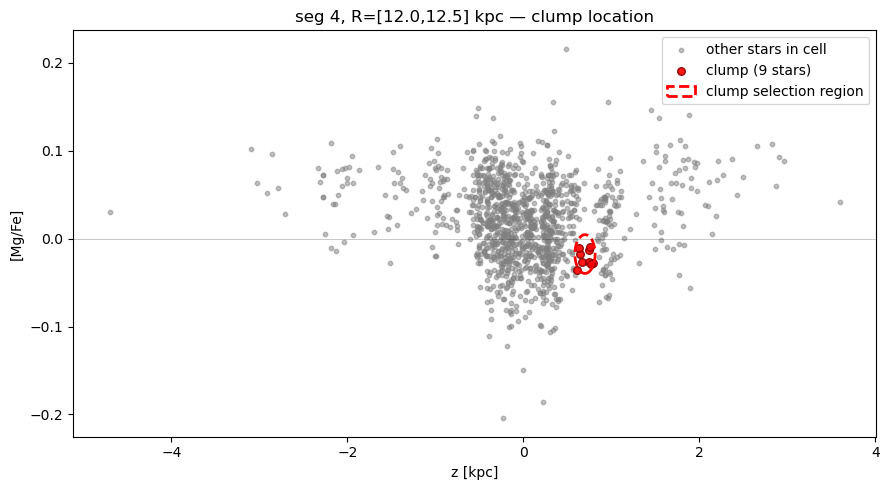

In [34]:
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

# all stars in this (annulus, segment)
m_cell = (
    segm[seg_id]
    & (R_star >= Rmin_focus) & (R_star < Rmax_focus)
    & np.isfinite(Z_star) & np.isfinite(mgfe_star)
)
z_cell    = np.asarray(Z_star)[m_cell]
mgfe_cell = np.asarray(mgfe_star)[m_cell]

# which of those are in the clump (same selection you've been using)
z_lo, z_hi  = 0.6, 0.8
mgfe_max    = 0.0
in_clump    = (z_cell >= z_lo) & (z_cell < z_hi) & (mgfe_cell <= mgfe_max)

fig, ax = plt.subplots(figsize=(9, 5))

# everything else: gray
ax.scatter(z_cell[~in_clump], mgfe_cell[~in_clump],
           s=10, color="gray", alpha=0.5, label="other stars in cell")

# the clump: red
ax.scatter(z_cell[in_clump], mgfe_cell[in_clump],
           s=30, color="red", alpha=0.9, edgecolor="darkred",
           label=f"clump ({in_clump.sum()} stars)")

# circle around the clump
z_center    = (z_lo + z_hi) / 2
mgfe_min    = float(np.nanmin(mgfe_cell[in_clump])) if in_clump.any() else -0.1
mgfe_center = (mgfe_max + mgfe_min) / 2
ellipse = Ellipse(
    (z_center, mgfe_center),
    width  = (z_hi - z_lo) * 1.15,            # slight buffer
    height = (mgfe_max - mgfe_min) * 1.25,
    fill=False, edgecolor="red", linewidth=2, linestyle="--",
    label="clump selection region",
)
ax.add_patch(ellipse)

ax.axhline(0, color="black", linewidth=0.5, alpha=0.3)
ax.set_xlabel("z [kpc]")
ax.set_ylabel("[Mg/Fe]")
ax.set_title(f"seg {seg_id}, R=[{Rmin_focus},{Rmax_focus}] kpc — clump location")
ax.legend(loc="best")
plt.tight_layout()
plt.show()

In [35]:
from sdss_semaphore.targeting import TargetingFlags

# pull the (z, [Mg/Fe]) per clump star so we can identify each star
m_cell = (
    segm[seg_id]
    & (R_star >= Rmin_focus) & (R_star < Rmax_focus)
    & np.isfinite(Z_star) & np.isfinite(mgfe_star)
    & np.isfinite(mgfe_err_star) & (mgfe_err_star > 0)
    & (Z_star >= z_lo) & (Z_star < z_hi)
    & (mgfe_star <= mgfe_max)
)
t_clump    = t_star[m_cell]
z_clump    = np.asarray(Z_star)[m_cell]
mgfe_clump = np.asarray(mgfe_star)[m_cell]

# decode all 32 stars at once (batch is fastest)
flags_all   = TargetingFlags(t_clump["sdss5_target_flags"])
star_cartons = flags_all.get_carton_name()   # tuple of tuples, one per star

# per-star printout
for i, cartons in enumerate(star_cartons):
    sid = t_clump[i]["sdss4_apogee_id"] if "sdss4_apogee_id" in t_clump.colnames else "?"
    print(f"\n--- star {i+1}/{len(t_clump)}   id={sid}   "
          f"z={z_clump[i]:+.3f}   [Mg/Fe]={mgfe_clump[i]:+.4f}   "
          f"({len(cartons)} cartons) ---")
    for name in cartons:
        print(f"   {name}")


--- star 1/9   id=-1   z=+0.746   [Mg/Fe]=-0.0133   (6 cartons) ---
   mwm_gg_core
   mwm_galactic_core
   openfibertargets_nov2020_34a
   openfibertargets_nov2020_34a
   mwm_galactic_core_dist_apogee
   mwm_galactic_core_dist_apogee_sparse

--- star 2/9   id=-1   z=+0.664   [Mg/Fe]=-0.0263   (6 cartons) ---
   mwm_gg_core
   mwm_galactic_core
   openfibertargets_nov2020_34a
   openfibertargets_nov2020_34a
   mwm_galactic_core_dist_apogee
   mwm_galactic_core_dist_apogee_sparse

--- star 3/9   id=-1   z=+0.789   [Mg/Fe]=-0.0283   (6 cartons) ---
   mwm_gg_core
   mwm_galactic_core
   openfibertargets_nov2020_34a
   openfibertargets_nov2020_34a
   mwm_galactic_core_dist_apogee
   mwm_galactic_core_dist_apogee_extra

--- star 4/9   id=-1   z=+0.748   [Mg/Fe]=-0.0263   (8 cartons) ---
   mwm_rv_short-fps
   mwm_gg_core
   mwm_galactic_core
   mwm_rv_short_fps
   mwm_rv_short_fps
   mwm_galactic_core_dist_apogee
   mwm_tess_rgb_apogee
   mwm_galactic_core_dist_apogee_extra

--- star 5/9  

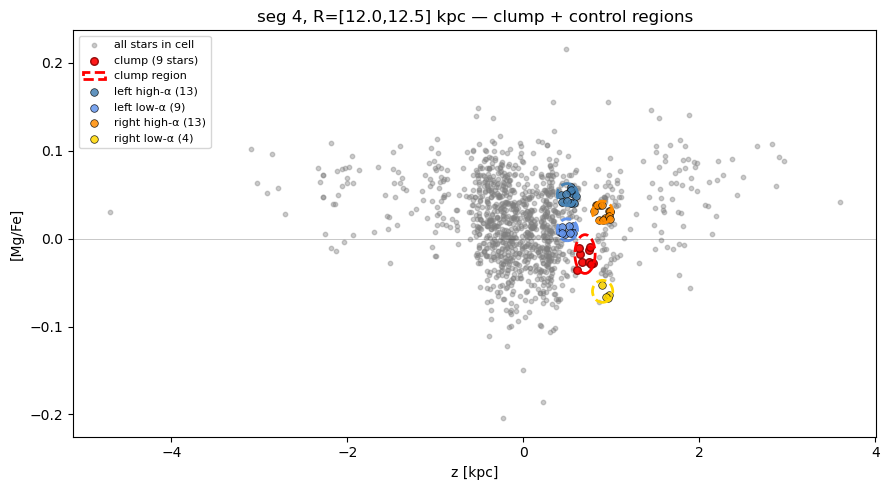


  left high-α   z=[0.4,0.6)   [Mg/Fe]=[0.04,0.06)   n=13

--- star 1/13   id=-1   z=+0.546   [Mg/Fe]=+0.0407   (11 cartons) ---
   mwm_rv_short-fps
   mwm_gg_core
   mwm_galactic_core
   mwm_rv_short_fps
   openfibertargets_nov2020_34a
   mwm_rv_short_fps
   openfibertargets_nov2020_34a
   mwm_galactic_core_dist_apogee
   mwm_legacy_ir2opt_boss
   mwm_tess_rgb_apogee
   mwm_galactic_core_dist_apogee_sparse

--- star 2/13   id=-1   z=+0.564   [Mg/Fe]=+0.0547   (12 cartons) ---
   mwm_rv_short-fps
   mwm_gg_core
   mwm_galactic_core
   mwm_rv_short_fps
   openfibertargets_nov2020_34a
   mwm_rv_short_fps
   openfibertargets_nov2020_34a
   mwm_galactic_core_dist_apogee
   mwm_legacy_ir2opt_boss
   mwm_tess_rgb_apogee
   mwm_bin_rv_short_rgb_apogee
   mwm_galactic_core_dist_apogee_sparse

--- star 3/13   id=-1   z=+0.574   [Mg/Fe]=+0.0407   (10 cartons) ---
   mwm_rv_short-fps
   mwm_gg_core
   mwm_galactic_core
   mwm_rv_short_fps
   openfibertargets_nov2020_34a
   mwm_rv_short_fps
   ope

In [45]:
# --- pick which side to check ---
# "left" flank:  z in [0.4, 0.6)
# "right" flank: z in [0.8, 1.0)
z_lo_flank, z_hi_flank = 0.4, 0.6   # or 0.8, 1.0

m_cell_flank = (
    segm[seg_id]
    & (R_star >= Rmin_focus) & (R_star < Rmax_focus)
    & np.isfinite(Z_star) & np.isfinite(mgfe_star)
    & np.isfinite(mgfe_err_star) & (mgfe_err_star > 0)
    & (Z_star >= z_lo_flank) & (Z_star < z_hi_flank)
    # no mgfe_max cut — take all [Mg/Fe] values
)

t_flank    = t_star[m_cell_flank]
z_flank    = np.asarray(Z_star)[m_cell_flank]
mgfe_flank = np.asarray(mgfe_star)[m_cell_flank]

flags_flank   = TargetingFlags(t_flank["sdss5_target_flags"])
star_cartons_flank = flags_flank.get_carton_name()

# define control regions: (z_lo, z_hi, mgfe_lo, mgfe_hi, label, color)
control_regions = [
    # left flank
    (0.4, 0.6,  0.04, 0.06, "left high-α",  "steelblue"),
    (0.4, 0.6,  0.0,0.02, "left low-α",   "cornflowerblue"),
    # right flank
    (0.8, 1.0,  0.02, 0.04, "right high-α", "darkorange"),
    (0.8, 1.0,  -0.07,-0.05, "right low-α",  "gold"),
]

fig, ax = plt.subplots(figsize=(9, 5))

# all stars in gray
m_all = (
    segm[seg_id]
    & (R_star >= Rmin_focus) & (R_star < Rmax_focus)
    & np.isfinite(Z_star) & np.isfinite(mgfe_star)
)
z_all    = np.asarray(Z_star)[m_all]
mgfe_all = np.asarray(mgfe_star)[m_all]
ax.scatter(z_all, mgfe_all, s=10, color="gray", alpha=0.4, label="all stars in cell")

# original clump in red
in_clump = (z_all >= z_lo) & (z_all < z_hi) & (mgfe_all <= mgfe_max)
ax.scatter(z_all[in_clump], mgfe_all[in_clump],
           s=30, color="red", alpha=0.9, edgecolor="darkred",
           label=f"clump ({in_clump.sum()} stars)")
# original clump ellipse
z_center    = (z_lo + z_hi) / 2
mgfe_min_cl = float(np.nanmin(mgfe_all[in_clump])) if in_clump.any() else -0.1
mgfe_center = (mgfe_max + mgfe_min_cl) / 2
ax.add_patch(Ellipse(
    (z_center, mgfe_center),
    width=(z_hi - z_lo) * 1.15, height=(mgfe_max - mgfe_min_cl) * 1.25,
    fill=False, edgecolor="red", linewidth=2, linestyle="--",
    label="clump region"
))

# control ellipses
for (zl, zh, mgl, mgh, lbl, col) in control_regions:
    in_ctrl = (z_all >= zl) & (z_all < zh) & (mgfe_all >= mgl) & (mgfe_all < mgh)
    ax.scatter(z_all[in_ctrl], mgfe_all[in_ctrl],
               s=30, color=col, alpha=0.85, edgecolor="k", linewidth=0.5,
               label=f"{lbl} ({in_ctrl.sum()})")
    ax.add_patch(Ellipse(
        ((zl + zh) / 2, (mgl + mgh) / 2),
        width=(zh - zl) * 1.15, height=(mgh - mgl) * 1.25,
        fill=False, edgecolor=col, linewidth=2, linestyle="--",
        label="_nolegend_"
    ))

ax.axhline(0, color="black", linewidth=0.5, alpha=0.3)
ax.set_xlabel("z [kpc]")
ax.set_ylabel("[Mg/Fe]")
ax.set_title(f"seg {seg_id}, R=[{Rmin_focus},{Rmax_focus}] kpc — clump + control regions")
ax.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()

# print cartons for each control region separately
for (zl, zh, mgl, mgh, lbl, col) in control_regions:
    m_ctrl = (
        segm[seg_id]
        & (R_star >= Rmin_focus) & (R_star < Rmax_focus)
        & np.isfinite(Z_star) & np.isfinite(mgfe_star)
        & np.isfinite(mgfe_err_star) & (mgfe_err_star > 0)
        & (Z_star >= zl) & (Z_star < zh)
        & (mgfe_star >= mgl) & (mgfe_star < mgh)
    )
    t_ctrl    = t_star[m_ctrl]
    z_ctrl    = np.asarray(Z_star)[m_ctrl]
    mgfe_ctrl = np.asarray(mgfe_star)[m_ctrl]

    print(f"\n{'='*60}")
    print(f"  {lbl}   z=[{zl},{zh})   [Mg/Fe]=[{mgl},{mgh})   n={m_ctrl.sum()}")
    print(f"{'='*60}")

    if m_ctrl.sum() == 0:
        print("  (no stars in this region)")
        continue

    flags_ctrl      = TargetingFlags(t_ctrl["sdss5_target_flags"])
    star_cartons_ctrl = flags_ctrl.get_carton_name()

    for i, cartons in enumerate(star_cartons_ctrl):
        sid = t_ctrl[i]["sdss4_apogee_id"] if "sdss4_apogee_id" in t_ctrl.colnames else "?"
        print(f"\n--- star {i+1}/{len(t_ctrl)}   id={sid}   "
              f"z={z_ctrl[i]:+.3f}   [Mg/Fe]={mgfe_ctrl[i]:+.4f}   "
              f"({len(cartons)} cartons) ---")
        for name in cartons:
            print(f"   {name}")

In [26]:
candidate_cols = [
    "sdss5_target_cartons",     # human-readable list of carton names per star
    "sdss5_target_pks",         # carton primary keys
    "firstcarton",              # the first carton that selected the star (single name)
    "carton",                   # carton name(s)
    "sdss5_cartons",
]
for c in candidate_cols:
    if c in t_clump.colnames:
        print(c, "→", t_clump[c][:5])  # peek at the first few"

In [234]:
print(crowd_bounds)

[2.35619449 2.49899416 2.64179382 2.78459349 2.92739315 3.07019282
 3.21299249 3.35579215 3.49859182 3.64139148 3.78419115 3.92699082]


In [29]:
# theta_edges was built earlier from crowd_bounds; rebuild here if needed
theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i - 1]:
        theta_edges[i] += 2 * np.pi

threshold = -0.3   # adjust to match how blue "blue enough" is in your eye

rows = []
for i_R in range(n_R):
    for j_seg in range(n_seg):
        z0m = z0_med[i_R, j_seg]
        z0s = z0_std[i_R, j_seg]
        if np.isfinite(z0m) and z0m < threshold:
            phi_mid = np.degrees(0.5*(theta_edges[j_seg] + theta_edges[j_seg+1])) % 360
            rows.append((i_R, j_seg, SEG_PLOT_heat[j_seg],
                         R_edges[i_R], R_edges[i_R+1], phi_mid,
                         z0m, z0s, abs(z0m/z0s) if z0s > 0 else np.nan))

rows.sort(key=lambda r: r[6])   # most negative first
print(f"{'i_R':>4} {'j_seg':>5} {'seg_id':>6} {'R range':>13} {'phi_mid':>9} {'z0_med':>8} {'z0_std':>7} {'|SNR|':>6}")
for r in rows:
    print(f"{r[0]:>4} {r[1]:>5} {r[2]:>6} [{r[3]:>4.1f},{r[4]:>4.1f}] {r[5]:>8.1f}° "
          f"{r[6]:>+7.3f} {r[7]:>7.3f} {r[8]:>6.2f}")

 i_R j_seg seg_id       R range   phi_mid   z0_med  z0_std  |SNR|
  22     9     10 [11.5,12.0]    212.7°  -0.442   0.116   3.81
  25     8      9 [13.0,13.5]    204.5°  -0.406   0.174   2.34
  26     8      9 [13.5,14.0]    204.5°  -0.406   0.101   4.03
  23     8      9 [12.0,12.5]    204.5°  -0.380   0.155   2.44
  24     9     10 [12.5,13.0]    212.7°  -0.343   0.154   2.23


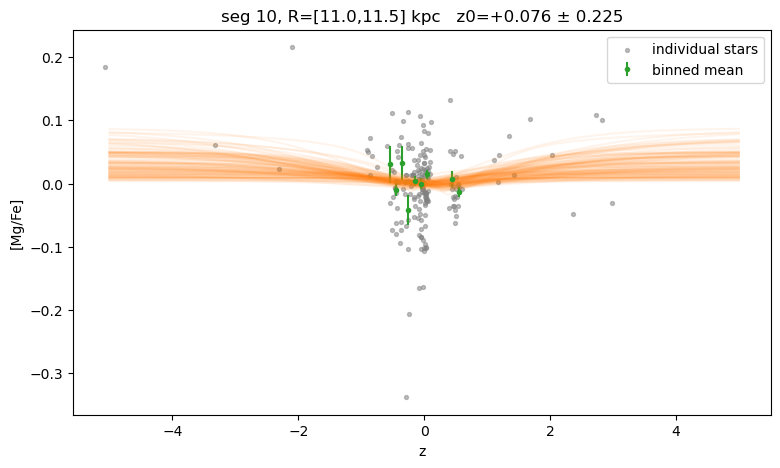

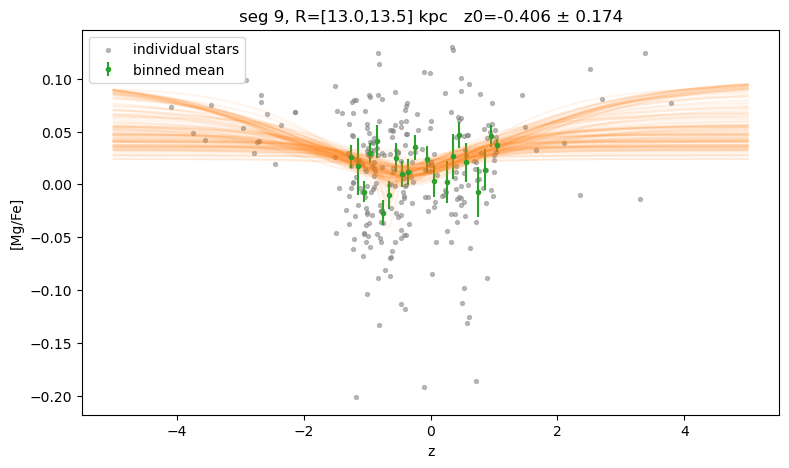

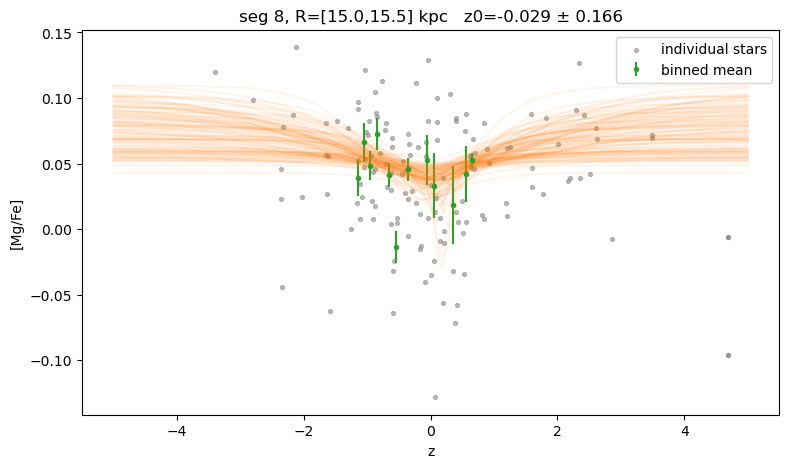

In [30]:
def plot_cell(i_R, j_seg):
    seg_id = SEG_PLOT_heat[j_seg]
    Rmin, Rmax = R_edges[i_R], R_edges[i_R + 1]

    m_cell = (
        segm[seg_id]
        & (R_star >= Rmin) & (R_star < Rmax)
        & np.isfinite(Z_star) & np.isfinite(mgfe_star)
        & np.isfinite(mgfe_err_star) & (mgfe_err_star > 0)
    )
    z_c    = np.asarray(Z_star)[m_cell]
    mgfe_c = np.asarray(mgfe_star)[m_cell]

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.scatter(z_c, mgfe_c, s=8, color="gray", alpha=0.5, label="individual stars")

    cell = per_cell.get((i_R, j_seg))
    if cell is not None:
        ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
                    color="C2", linestyle="", marker=".", label="binned mean")
        z_grid = np.linspace(-5, 5, 1000)
        s = cell["samples"]
        for i in range(min(100, len(s["A1"]))):
            y_pred = mixture_of_sech2(z_grid, s["A1"][i], s["A2"][i],
                                      s["h1"][i], s["h1"][i] + s["d_h2"][i],
                                      s["z0"][i]) + s["offset"][i]
            ax.plot(z_grid, y_pred, color="C1", alpha=0.08, marker="")
    ax.set_xlabel("z"); ax.set_ylabel("[Mg/Fe]")
    ax.set_title(f"seg {seg_id}, R=[{Rmin:.1f},{Rmax:.1f}] kpc   "
                 f"z0={z0_med[i_R,j_seg]:+.3f} ± {z0_std[i_R,j_seg]:.3f}")
    ax.legend(); plt.show()


# seg 10, R = 11.0–11.5  →  i_R=21, j_seg=9
plot_cell(i_R=21, j_seg=9)

# seg 9, R = 13.0–13.5   →  i_R=25, j_seg=8
plot_cell(i_R=25, j_seg=8)

plot_cell(i_R=29, j_seg=7)


## 6. Full loop over all (annulus, segment) pairs

Runs the demo's MCMC for every (annulus, segment) pair and stores `z0` median + stddev plus the star count per cell.

Heads up: this is many fits. After the first fit JIT-compiles (~30 s), subsequent fits are a few seconds each. The crowded-segments-only loop is `n_R × n_seg = (len(R_edges)-1) × seg_diag['n_crowd']`. Plan accordingly; you can lower `num_samples` / `num_warmup` here if you want a quick run, but I'm leaving the demo settings unchanged.


In [31]:
from itertools import product

n_R   = len(R_edges) - 1
n_seg = len(SEG_PLOT_heat)

z0_med   = np.full((n_R, n_seg), np.nan)
z0_std   = np.full((n_R, n_seg), np.nan)
n_stars  = np.zeros((n_R, n_seg), dtype=int)
n_bins   = np.zeros((n_R, n_seg), dtype=int)
ok_grid  = np.zeros((n_R, n_seg), dtype=bool)

key = jr.PRNGKey(0)

pairs = list(product(range(n_R), range(n_seg)))
print(f"running {len(pairs)} (annulus, segment) fits ...")

for k, (i_R, j_seg) in enumerate(pairs, 1):
    Rmin = float(R_edges[i_R])
    Rmax = float(R_edges[i_R + 1])
    seg_id = SEG_PLOT_heat[j_seg]

    z_binc_k, mean_k, err_k, ns_k, ok_k = select_annulus_segment(
        R_star, Z_star, mgfe_star, mgfe_err_star,
        seg_mask=segm[seg_id],
        Rmin=Rmin, Rmax=Rmax,
    )
    n_stars[i_R, j_seg] = ns_k
    if not ok_k:
        continue

    n_bins[i_R, j_seg] = len(z_binc_k)
    try:
        key, sub = jr.split(key)
        sampler_k = fit_sech2(z_binc_k, mean_k, err_k, sub, progress_bar=False)
        samples_k = sampler_k.get_samples()
        z0_med[i_R, j_seg] = float(np.median(samples_k["z0"]))
        z0_std[i_R, j_seg] = float(np.std(samples_k["z0"]))
        ok_grid[i_R, j_seg] = True
    except Exception as e:
        print(f"  fit failed: seg={seg_id} R=[{Rmin:.1f},{Rmax:.1f}] -> {e}")

    if k % 10 == 0 or k == len(pairs):
        print(f"  done {k}/{len(pairs)}")

print("fits complete:", int(ok_grid.sum()), "/", ok_grid.size)


running 330 (annulus, segment) fits ...


/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_74402/3181619348.py:14: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_74402/3181619348.py:15: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_74402/3181619348.py:45: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


  done 70/330
  done 130/330
  done 140/330
  done 150/330
  done 160/330
  done 170/330
  done 180/330
  done 190/330
  done 200/330
  done 210/330
  done 220/330
  done 230/330
  done 240/330
  done 250/330
  done 260/330
  done 270/330
  done 280/330
  done 290/330
  done 300/330
fits complete: 206 / 330


In [59]:
# save results so the loop doesn't have to be rerun
import os
out_npz = "sech2_mcmc_z0_results2.npz"
np.savez(
    out_npz,
    R_edges=R_edges,
    SEG_PLOT_heat=np.asarray(SEG_PLOT_heat),
    crowd_bounds=np.asarray(crowd_bounds),
    z0_med=z0_med,
    z0_std=z0_std,
    n_stars=n_stars,
    n_bins=n_bins,
    ok_grid=ok_grid,
)
print("saved:", os.path.abspath(out_npz))


saved: /Users/emmatasso/outerdisk/sech2_mcmc_z0_results2.npz


## 7. Polar heatmap (matches the original notebook's style)

Build `theta_edges` from `crowd_bounds` (unwrapped, same logic as cell 16 of the master notebook), then plot a polar `pcolormesh` of `z0_med` over (R, θ). Cells with no fit appear as masked / nan.


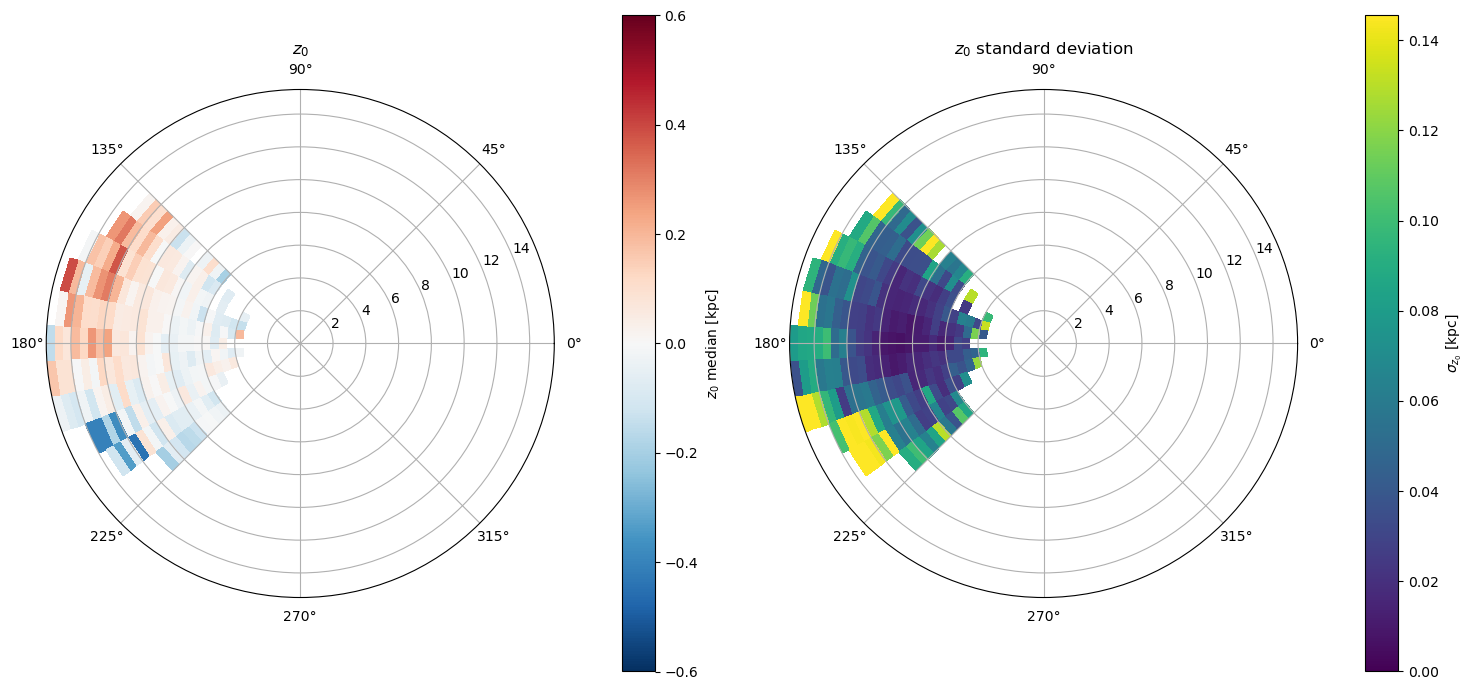

In [222]:
# build unwrapped theta edges from crowd_bounds (same construction as the master notebook)
theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i - 1]:
        theta_edges[i] += 2 * np.pi
assert len(theta_edges) - 1 == n_seg, "theta_edges length must match number of crowded segments"
# meshgrid for polar pcolormesh
T_mesh, R_mesh = np.meshgrid(theta_edges, R_edges)
Zmap_med = np.ma.masked_invalid(z0_med)

# z0 stddev
Zmap_std = np.ma.masked_invalid(z0_std)
std_max = float(np.nanpercentile(z0_std[np.isfinite(z0_std)], 95)) if np.isfinite(z0_std).any() else 1.0

fig = plt.figure(figsize=(15, 7))
# left: z0 median
ax1 = plt.subplot(1, 2, 1, projection="polar")
pcm1 = ax1.pcolormesh(T_mesh, R_mesh, Zmap_med, cmap="RdBu_r", vmin=-zlim, vmax=zlim, shading="flat")
fig.colorbar(pcm1, ax=ax1, pad=0.1, label=r"$z_0$ median [kpc]")
ax1.set_title(r"$z_0$")
ax1.set_theta_zero_location("E")
ax1.set_theta_direction(1)
ax1.set_rmax(R_edges[-1])
# right: z0 stddev
ax2 = plt.subplot(1, 2, 2, projection="polar")
pcm2 = ax2.pcolormesh(T_mesh, R_mesh, Zmap_std, cmap="viridis",
                      vmin=0.0, vmax=std_max, shading="flat")
fig.colorbar(pcm2, ax=ax2, pad=0.1, label=r"$\sigma_{z_0}$ [kpc]")
ax2.set_title(r"$z_0$ standard deviation")
ax2.set_theta_zero_location("E")
ax2.set_theta_direction(1)
ax2.set_rmax(R_edges[-1])
plt.tight_layout()
plt.show()

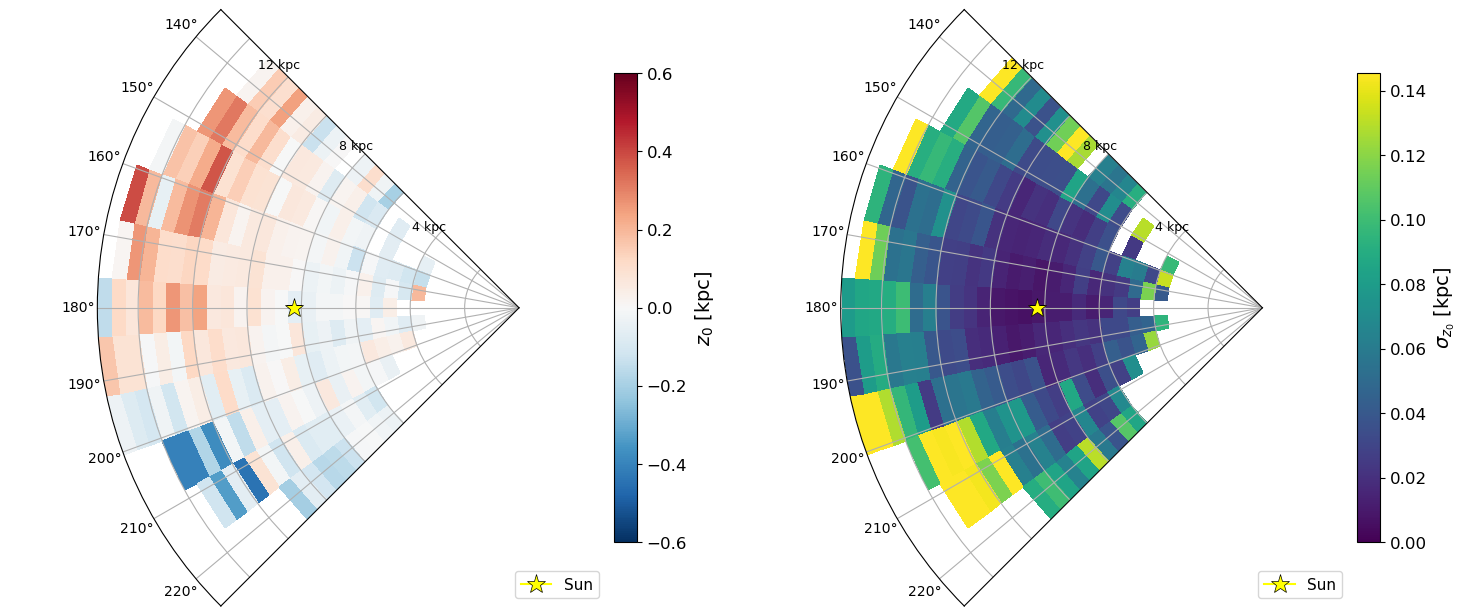

In [232]:
# build unwrapped theta edges from crowd_bounds
theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i - 1]:
        theta_edges[i] += 2 * np.pi
assert len(theta_edges) - 1 == n_seg, "theta_edges length must match number of crowded segments"

T_mesh, R_mesh = np.meshgrid(theta_edges, R_edges)
Zmap_med = np.ma.masked_invalid(z0_med)
Zmap_std = np.ma.masked_invalid(z0_std)
std_max = float(np.nanpercentile(z0_std[np.isfinite(z0_std)], 95)) if np.isfinite(z0_std).any() else 1.0

theta_min = theta_edges[0]
theta_max = theta_edges[-1]
theta_sun = np.radians(180)  # sun is at phi=180 in Galactocentric
R_sun = 8.275

fig = plt.figure(figsize=(15, 7))

# left: z0 median
ax1 = plt.subplot(1, 2, 1, projection="polar")
pcm1 = ax1.pcolormesh(T_mesh, R_mesh, Zmap_med, cmap="RdBu_r", vmin=-zlim, vmax=zlim, shading="flat")
cb1 = fig.colorbar(pcm1, ax=ax1, pad=0.01, shrink=0.7)
cb1.set_label(r"$z_0$ [kpc]", fontsize=14)
cb1.ax.tick_params(labelsize=12)
ax1.set_theta_zero_location("E")
ax1.set_theta_direction(1)
ax1.set_rmax(R_edges[-1])
ax1.set_thetamin(np.degrees(theta_min))
ax1.set_thetamax(np.degrees(theta_max))
ax1.set_title("")
# R labels
for r in R_edges[R_edges % 4 == 0]:
    ax1.text(theta_min - np.radians(3), r, f"{r:.0f} kpc",
             fontsize=9, ha="right", va="center")
ax1.set_yticklabels([])
# sun marker
ax1.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=14,
         markeredgecolor="k", markeredgewidth=0.5, zorder=5, label="Sun")
ax1.legend(loc="lower right", fontsize=11)

# right: z0 stddev
ax2 = plt.subplot(1, 2, 2, projection="polar")
pcm2 = ax2.pcolormesh(T_mesh, R_mesh, Zmap_std, cmap="viridis",
                      vmin=0.0, vmax=std_max, shading="flat")
cb2 = fig.colorbar(pcm2, ax=ax2, pad=0.01, shrink=0.7)
cb2.set_label(r"$\sigma_{z_0}$ [kpc]", fontsize=14)
cb2.ax.tick_params(labelsize=12)
ax2.set_theta_zero_location("E")
ax2.set_theta_direction(1)
ax2.set_rmax(R_edges[-1])
ax2.set_thetamin(np.degrees(theta_min))
ax2.set_thetamax(np.degrees(theta_max))
ax2.set_title("")
# R labels
for r in R_edges[R_edges % 4 == 0]:
    ax2.text(theta_min - np.radians(3), r, f"{r:.0f} kpc",
             fontsize=9, ha="right", va="center")
ax2.set_yticklabels([])
# sun marker
ax2.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=14,
         markeredgecolor="k", markeredgewidth=0.5, zorder=5, label="Sun")
ax2.legend(loc="lower right", fontsize=11)

plt.tight_layout()
plt.show()

In [51]:
n_R   = len(R_edges) - 1
n_seg = len(SEG_PLOT_heat)
z0_med  = np.full((n_R, n_seg), np.nan)
z0_std  = np.full((n_R, n_seg), np.nan)
n_stars = np.zeros((n_R, n_seg), dtype=int)
n_bins  = np.zeros((n_R, n_seg), dtype=int)
ok_grid = np.zeros((n_R, n_seg), dtype=bool)
per_cell = {}   # (i_R, j_seg) -> dict with binned data + samples


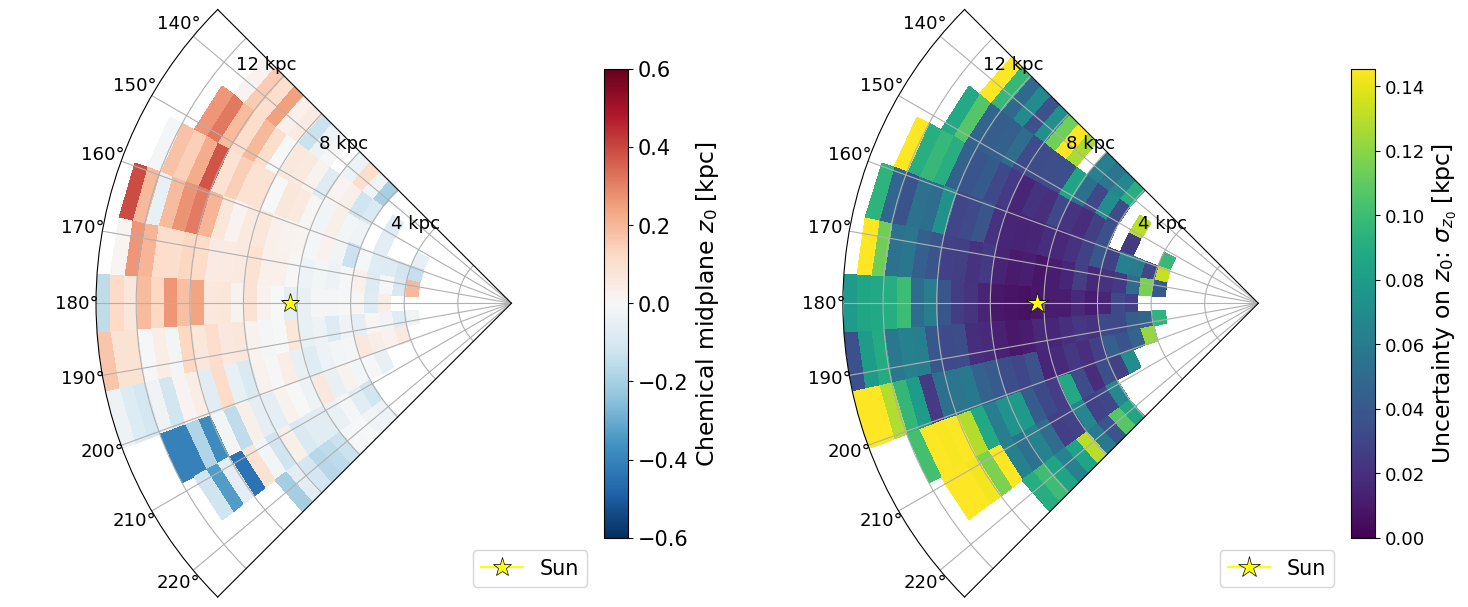

In [64]:
# build unwrapped theta edges from crowd_bounds
theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i - 1]:
        theta_edges[i] += 2 * np.pi
assert len(theta_edges) - 1 == n_seg, "theta_edges length must match number of crowded segments"

T_mesh, R_mesh = np.meshgrid(theta_edges, R_edges)
Zmap_med = np.ma.masked_invalid(z0_med)
Zmap_std = np.ma.masked_invalid(z0_std)
std_max = float(np.nanpercentile(z0_std[np.isfinite(z0_std)], 95)) if np.isfinite(z0_std).any() else 1.0
theta_min = theta_edges[0]
theta_max = theta_edges[-1]
theta_sun = np.radians(180)
R_sun = 8.275

fig = plt.figure(figsize=(15, 7))

# left: z0 median
ax1 = plt.subplot(1, 2, 1, projection="polar")
pcm1 = ax1.pcolormesh(T_mesh, R_mesh, Zmap_med, cmap="RdBu_r", vmin=-zlim, vmax=zlim, shading="flat")
cb1 = fig.colorbar(pcm1, ax=ax1, pad=0.01, shrink=0.7)
cb1.set_label(r"Chemical midplane $z_0$ [kpc]", fontsize=17)
cb1.ax.tick_params(labelsize=15)
ax1.tick_params(labelsize=13)
ax1.set_theta_zero_location("E")
ax1.set_theta_direction(1)
ax1.set_rmax(R_edges[-1])
ax1.set_thetamin(np.degrees(theta_min))
ax1.set_thetamax(np.degrees(theta_max))
ax1.set_title("")
for r in R_edges[R_edges % 4 == 0]:
    ax1.text(theta_min - np.radians(3), r, f"{r:.0f} kpc",
             fontsize=13, ha="right", va="center")
ax1.set_yticklabels([])
ax1.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=14,
         markeredgecolor="k", markeredgewidth=0.5, zorder=5, label="Sun")
ax1.legend(loc="lower right", fontsize=15)

# right: z0 stddev
ax2 = plt.subplot(1, 2, 2, projection="polar")
pcm2 = ax2.pcolormesh(T_mesh, R_mesh, Zmap_std, cmap="viridis",
                      vmin=0.0, vmax=std_max, shading="flat")
cb2 = fig.colorbar(pcm2, ax=ax2, pad=0.01, shrink=0.7)
cb2.set_label(r"Uncertainty on $z_0$: $\sigma_{z_0}$ [kpc]", fontsize=17)
cb2.ax.tick_params(labelsize=13)
ax2.set_theta_zero_location("E")
ax2.set_theta_direction(1)
ax2.tick_params(labelsize=13)
ax2.set_rmax(R_edges[-1])
ax2.set_thetamin(np.degrees(theta_min))
ax2.set_thetamax(np.degrees(theta_max))
ax2.set_title("")
for r in R_edges[R_edges % 4 == 0]:
    ax2.text(theta_min - np.radians(3), r, f"{r:.0f} kpc",
             fontsize=13, ha="right", va="center")
ax2.set_yticklabels([])
ax2.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=16,
         markeredgecolor="k", markeredgewidth=0.5, zorder=5, label="Sun")
ax2.legend(loc="lower right", fontsize=15)

plt.tight_layout()
plt.show()

In [104]:
# ---- collect per-cell medians + stddevs for any variable ----
def collect_stats(varname):
    """Pull a variable's samples from every cell in per_cell, return (med, std) grids."""
    med = np.full((n_R, n_seg), np.nan)
    std = np.full((n_R, n_seg), np.nan)
    for (i_R, j_seg), cell in per_cell.items():
        s = cell["samples"]
        if varname in s:
            med[i_R, j_seg] = float(np.median(s[varname]))
            std[i_R, j_seg] = float(np.std(s[varname]))
    return med, std

h1_med, h1_std = collect_stats("h1")
Q_med,  Q_std  = collect_stats("Q")
A1_med,  A1_std  = collect_stats("A1")
A2_med,  A2_std  = collect_stats("A2")
Aratio_med = A1_med / A2_med
Aratio_std = Aratio_med*np.sqrt((A1_std / A1_med)**2 + (A2_std / A2_med)**2 )# Emma double check error propogation

# h2 = h1 + d_h2 — compute from samples
h2_med = np.full((n_R, n_seg), np.nan)
h2_std = np.full((n_R, n_seg), np.nan)
for (i_R, j_seg), cell in per_cell.items():
    s = cell["samples"]
    if "h1" in s and "d_h2" in s:
        h2_samples = np.asarray(s["h1"]) + np.asarray(s["d_h2"])
        h2_med[i_R, j_seg] = float(np.median(h2_samples))
        h2_std[i_R, j_seg] = float(np.std(h2_samples))

print("collected.  Q present:", np.isfinite(Q_med).any())

collected.  Q present: True


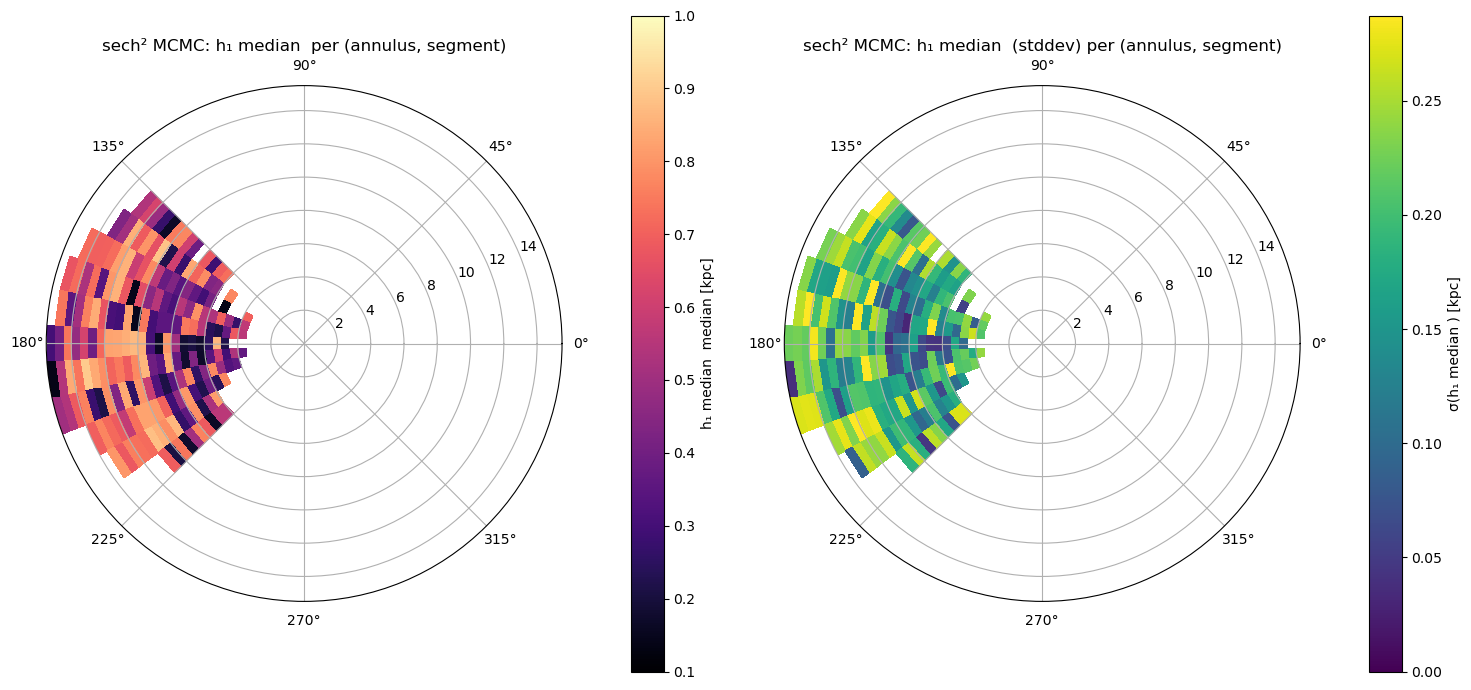

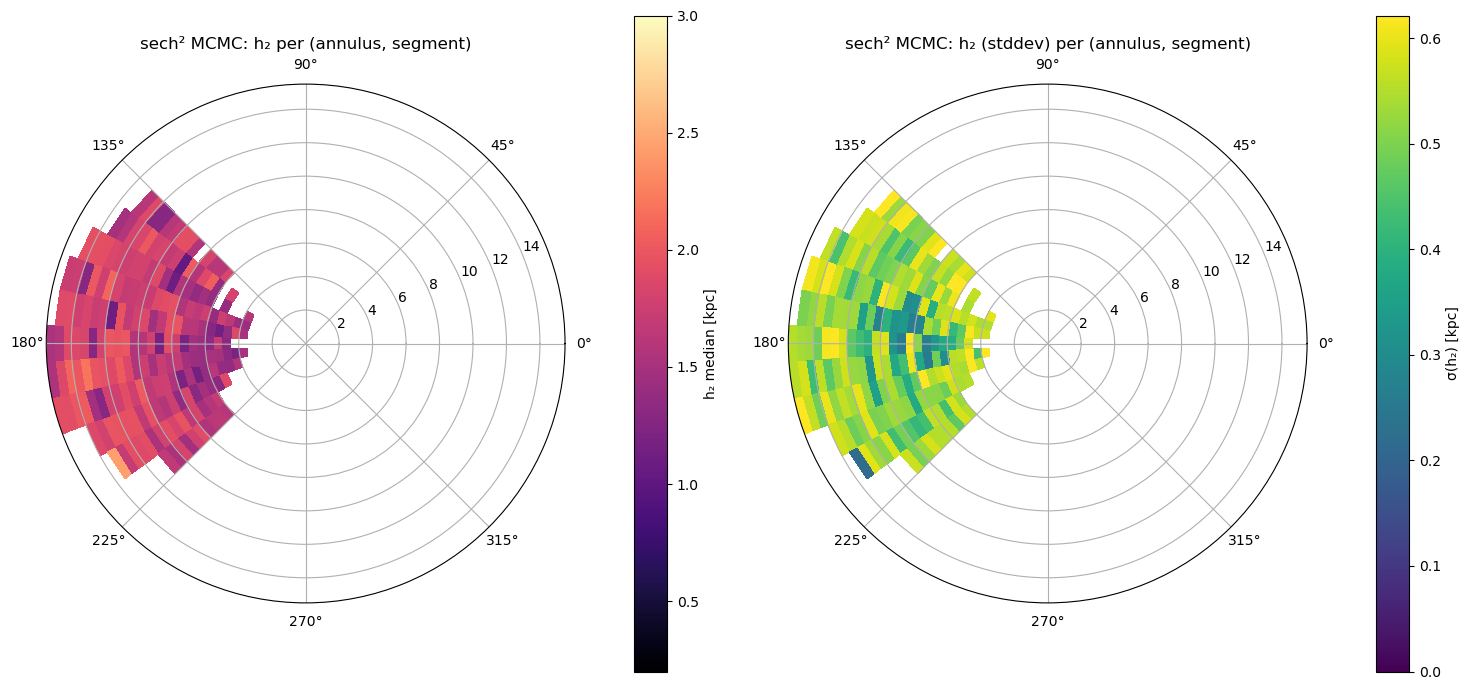

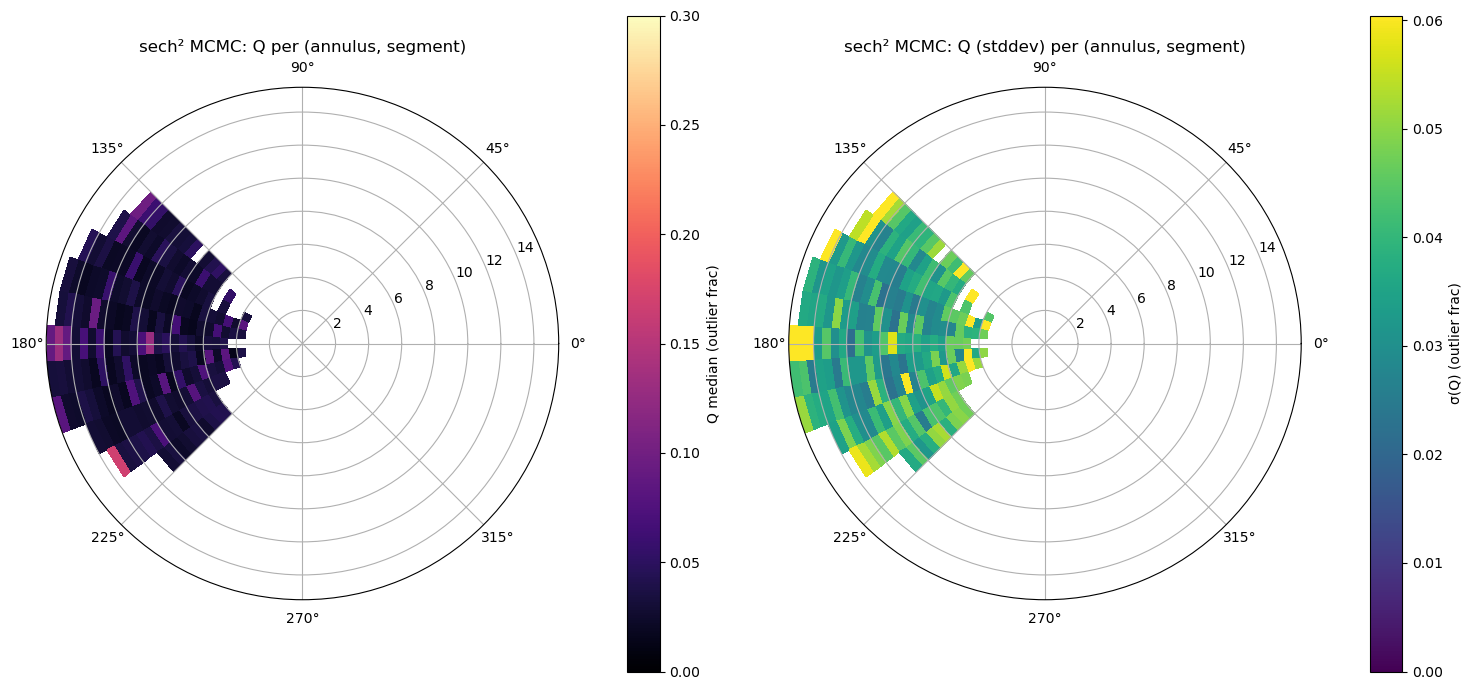

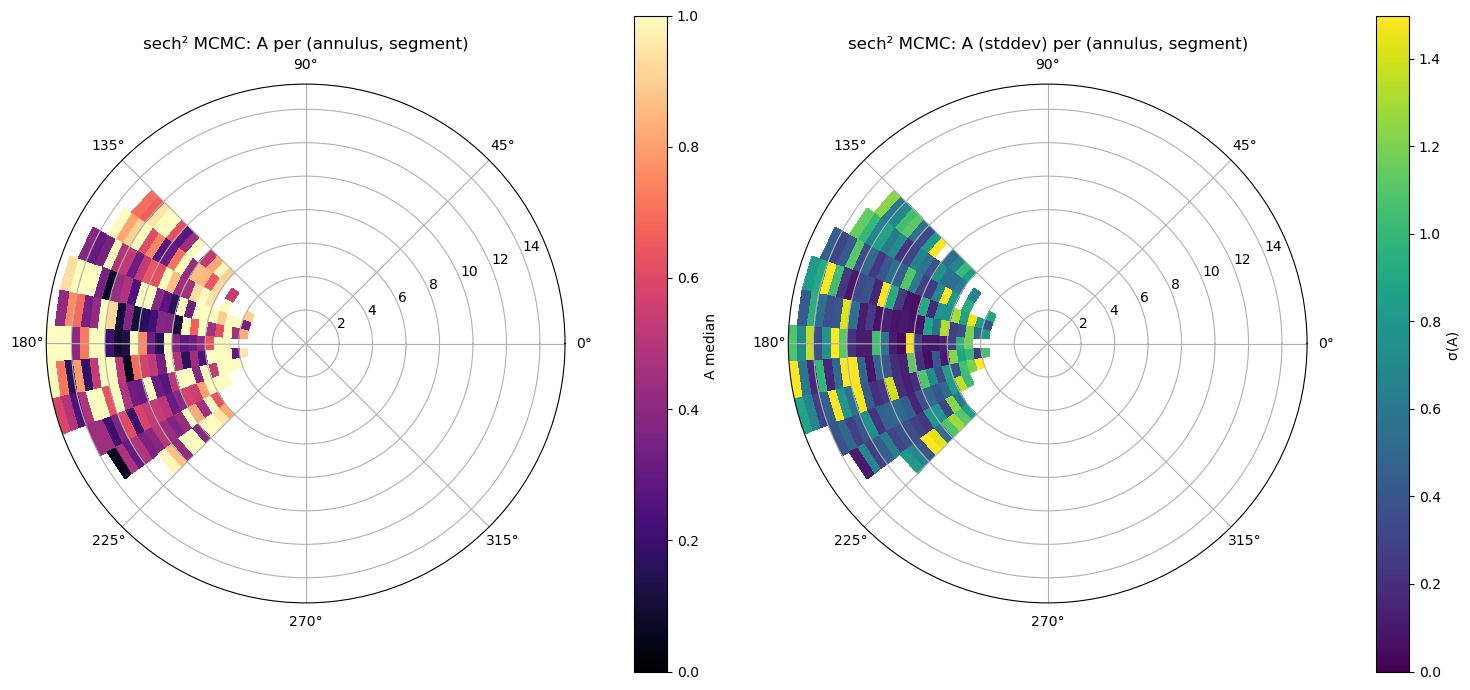

In [152]:
def heatmap_pair(med_grid, std_grid, name, units="",
                 vmin=None, vmax=None,
                 cmap_med="magma", cmap_std="viridis"):
    Zmap_med = np.ma.masked_invalid(med_grid)
    Zmap_std = np.ma.masked_invalid(std_grid)
    T_mesh, R_mesh = np.meshgrid(theta_edges, R_edges)

    std_vmax = (float(np.nanpercentile(std_grid[np.isfinite(std_grid)], 95))
                if np.isfinite(std_grid).any() else 1.0)

    fig = plt.figure(figsize=(15, 7))

    ax1 = plt.subplot(1, 2, 1, projection="polar")
    pcm1 = ax1.pcolormesh(T_mesh, R_mesh, Zmap_med, cmap=cmap_med,
                          vmin=vmin, vmax=vmax, shading="flat")
    fig.colorbar(pcm1, ax=ax1, pad=0.1, label=f"{name} median {units}")
    ax1.set_title(f"sech² MCMC: {name} per (annulus, segment)")
    ax1.set_theta_zero_location("E"); ax1.set_theta_direction(1); ax1.set_rmax(R_edges[-1])

    ax2 = plt.subplot(1, 2, 2, projection="polar")
    pcm2 = ax2.pcolormesh(T_mesh, R_mesh, Zmap_std, cmap=cmap_std,
                          vmin=0.0, vmax=std_vmax, shading="flat") #std_vmax
    fig.colorbar(pcm2, ax=ax2, pad=0.1, label=f"σ({name}) {units}")
    ax2.set_title(f"sech² MCMC: {name} (stddev) per (annulus, segment)")
    ax2.set_theta_zero_location("E"); ax2.set_theta_direction(1); ax2.set_rmax(R_edges[-1])

    plt.tight_layout(); plt.show()

# h1: prior support [0.1, 1.0]
heatmap_pair(h1_med, h1_std, name="h₁ median ", units="[kpc]", vmin=0.1, vmax=1.0)

# h2 = h1 + d_h2: support [0.2, 3.0]
heatmap_pair(h2_med, h2_std, name="h₂", units="[kpc]", vmin=0.2, vmax=3.0)

# Q: outlier fraction, support [0, 1]
heatmap_pair(Q_med,  Q_std,  name="Q",  units="(outlier frac)", vmin=0.0, vmax=0.3)

heatmap_pair(Aratio_med,  Aratio_std,  name="A",  units="", vmin=0.0, vmax=1.0)

## Addressing Eloisa's comments

1. Make a sky plot to check for holes or gaps in spatial coverage


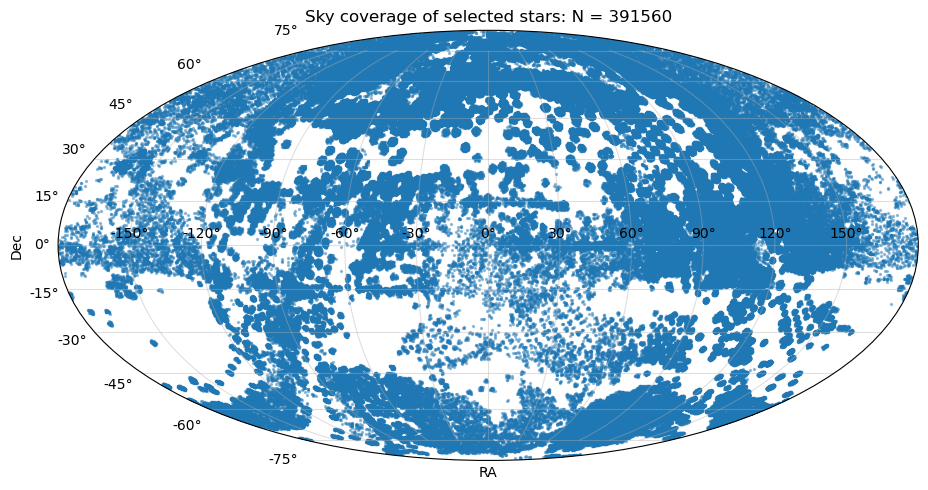

In [80]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord

# Use the table corresponding to your selected stars
tab = t_final   # or use t_final if you want the pre-star_pack final chemistry sample

# ---- helper to find RA/Dec column names ----
def find_col(tab, possible_names):
    for name in possible_names:
        if name in tab.colnames:
            return name
    raise KeyError(f"None of these columns found: {possible_names}")

ra_col  = find_col(tab, ["ra", "RA", "sdss4_ra", "sdss5_ra"])
dec_col = find_col(tab, ["dec", "DEC", "sdss4_dec", "sdss5_dec"])

ra  = np.asarray(tab[ra_col], dtype=float)
dec = np.asarray(tab[dec_col], dtype=float)

m = np.isfinite(ra) & np.isfinite(dec)

# Convert RA to wrapped radians for all-sky projection
ra_wrap = coord_ra = SkyCoord(
    ra=ra[m] * u.deg,
    dec=dec[m] * u.deg,
    frame="icrs"
).ra.wrap_at(180 * u.deg).radian

dec_rad = np.deg2rad(dec[m])

fig = plt.figure(figsize=(10, 5))
ax = fig.add_subplot(111, projection="mollweide")

ax.scatter(
    ra_wrap,
    dec_rad,
    s=2,
    alpha=0.4,
    rasterized=True
)

ax.set_xlabel("RA")
ax.set_ylabel("Dec")
ax.set_title(f"Sky coverage of selected stars: N = {m.sum()}")

ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

2. Check whether red clump stars reveal a ring-around-the-Sun artifact in the data


In [91]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord

tab = t_final

def find_col(tab, possible_names, required=False):
    for name in possible_names:
        if name in tab.colnames:
            return name
    if required:
        raise KeyError(f"None of these columns found: {possible_names}")
    return None

ra_col  = find_col(tab, ["ra", "RA", "sdss4_ra", "sdss5_ra"], required=True)
dec_col = find_col(tab, ["dec", "DEC", "sdss4_dec", "sdss5_dec"], required=True)
plx_col = find_col(tab, ["zgr_plx", "parallax", "PARALLAX"], required=True)

ra  = np.asarray(tab[ra_col], dtype=float)
dec = np.asarray(tab[dec_col], dtype=float)
plx = np.asarray(tab[plx_col], dtype=float)

# ZGR parallax distance
dist_kpc = np.full(len(tab), np.nan)

good_plx = np.isfinite(plx) & (plx > 0)
dist_kpc[good_plx] = 1.0 / plx[good_plx]   # kpc if parallax is in mas

m = (
    np.isfinite(ra)
    & np.isfinite(dec)
    & np.isfinite(dist_kpc)
    & (dist_kpc > 0)
)

print("len(t_final):", len(t_final))
print("usable with positive ZGR parallax:", int(m.sum()))
print("missing/bad ZGR parallax:", int((~m).sum()))

c = SkyCoord(
    ra=ra[m] * u.deg,
    dec=dec[m] * u.deg,
    distance=dist_kpc[m] * u.kpc,
    frame="icrs"
)

gal = c.galactic

l = gal.l.radian
b = gal.b.radian
d = gal.distance.to_value(u.kpc)

x_helio = d * np.cos(b) * np.cos(l)
y_helio = d * np.cos(b) * np.sin(l)
z_helio = d * np.sin(b)

len(t_final): 391560
usable with positive ZGR parallax: 391560
missing/bad ZGR parallax: 0


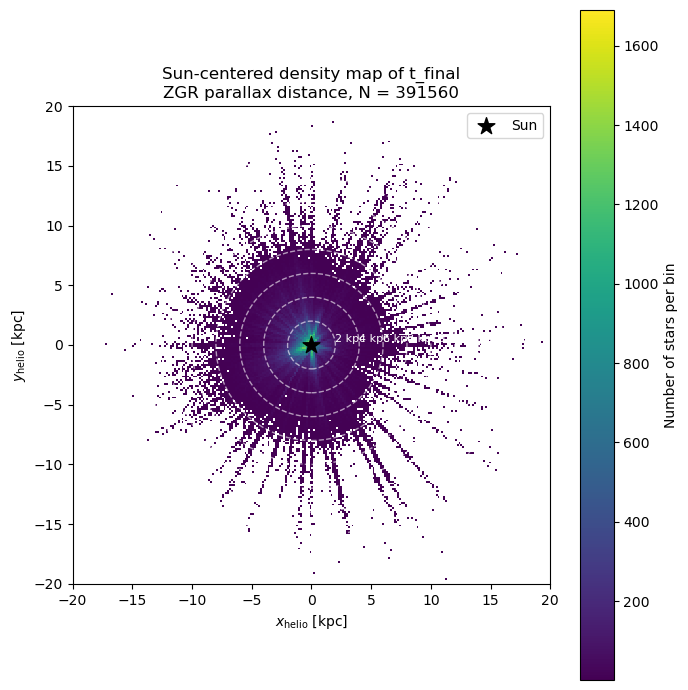

In [92]:
fig, ax = plt.subplots(figsize=(7, 7))

h = ax.hist2d(
    x_helio,
    y_helio,
    bins=250,
    range=[[-20, 20], [-20, 20]],
    cmin=1
)

cb = plt.colorbar(h[3], ax=ax)
cb.set_label("Number of stars per bin")

ax.scatter(0, 0, marker="*", s=160, color="black", label="Sun")

for r in [2, 4, 6, 8, 10, 12, 14, 16]:
    circle = plt.Circle(
        (0, 0),
        r,
        fill=False,
        color="white",
        alpha=0.6,
        linestyle="--",
        linewidth=1
    )
    ax.add_patch(circle)
    ax.text(r, 0.25, f"{r} kpc", color="white", fontsize=8)

ax.set_xlabel(r"$x_{\rm helio}$ [kpc]")
ax.set_ylabel(r"$y_{\rm helio}$ [kpc]")
ax.set_title(f"Sun-centered density map of t_final\nZGR parallax distance, N = {m.sum()}")

ax.set_aspect("equal", adjustable="box")
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

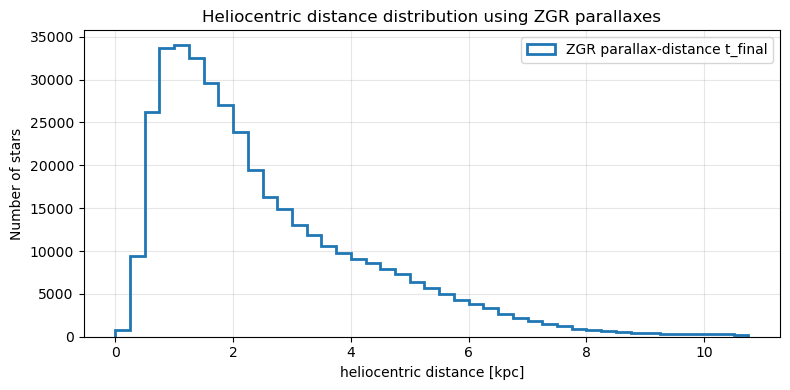

In [93]:
fig, ax = plt.subplots(figsize=(8, 4))

bins = np.arange(0, np.nanpercentile(dist_kpc[m], 99.5) + 0.25, 0.25)

ax.hist(
    dist_kpc[m],
    bins=bins,
    histtype="step",
    linewidth=2,
    label="ZGR parallax-distance t_final"
)

ax.set_xlabel("heliocentric distance [kpc]")
ax.set_ylabel("Number of stars")
ax.set_title("Heliocentric distance distribution using ZGR parallaxes")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

3. Bin stars by log g along the giant branch, separating stars brighter than the red clump; include comparison plots of just red clump stars vs. others in the index


In [95]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord

tab = t_final

def find_col(tab, possible_names, required=False):
    for name in possible_names:
        if name in tab.colnames:
            return name
    if required:
        raise KeyError(f"None of these columns found: {possible_names}")
    return None

# -----------------------------
# Required columns
# -----------------------------
ra_col   = find_col(tab, ["ra", "RA", "sdss4_ra", "sdss5_ra"], required=True)
dec_col  = find_col(tab, ["dec", "DEC", "sdss4_dec", "sdss5_dec"], required=True)
logg_col = find_col(tab, ["logg", "LOGG"], required=True)
teff_col = find_col(tab, ["teff", "TEFF"], required=False)

# Force ZGR parallax if available
plx_col = find_col(tab, ["zgr_plx", "ZGR_PLX"], required=True)

ra   = np.asarray(tab[ra_col], dtype=float)
dec  = np.asarray(tab[dec_col], dtype=float)
logg = np.asarray(tab[logg_col], dtype=float)
plx  = np.asarray(tab[plx_col], dtype=float)

if teff_col is not None:
    teff = np.asarray(tab[teff_col], dtype=float)
else:
    teff = np.full(len(tab), np.nan)

# -----------------------------
# ZGR distance
# -----------------------------
dist_kpc = np.full(len(tab), np.nan)

good_plx = np.isfinite(plx) & (plx > 0)
dist_kpc[good_plx] = 1.0 / plx[good_plx]   # d[kpc] = 1 / plx[mas]

base = (
    np.isfinite(ra)
    & np.isfinite(dec)
    & np.isfinite(logg)
    & np.isfinite(dist_kpc)
    & (dist_kpc > 0)
)

print("len(t_final):", len(t_final))
print("usable with logg + positive ZGR parallax:", int(base.sum()))
print("missing/bad ZGR parallax or required values:", int((~base).sum()))

len(t_final): 391560
usable with logg + positive ZGR parallax: 391560
missing/bad ZGR parallax or required values: 0


In [96]:
# Approximate diagnostic bins
m_bright_rgb = base & (logg < 2.3)
m_rc_like    = base & (logg >= 2.3) & (logg < 2.6)
m_lower_rgb  = base & (logg >= 2.6) & (logg < 3.5)

m_not_rc = base & ~m_rc_like

logg_groups = {
    "bright RGB / above RC": m_bright_rgb,
    "red-clump-like": m_rc_like,
    "lower RGB / below RC": m_lower_rgb,
    "not red-clump-like": m_not_rc,
}

print(f"{'group':28s} {'N':>10s} {'frac usable':>12s}")
print("-" * 55)

for name, mask in logg_groups.items():
    n = int(mask.sum())
    print(f"{name:28s} {n:10d} {n / base.sum():12.4f}")

group                                 N  frac usable
-------------------------------------------------------
bright RGB / above RC            148754       0.3799
red-clump-like                   138938       0.3548
lower RGB / below RC              97113       0.2480
not red-clump-like               252622       0.6452


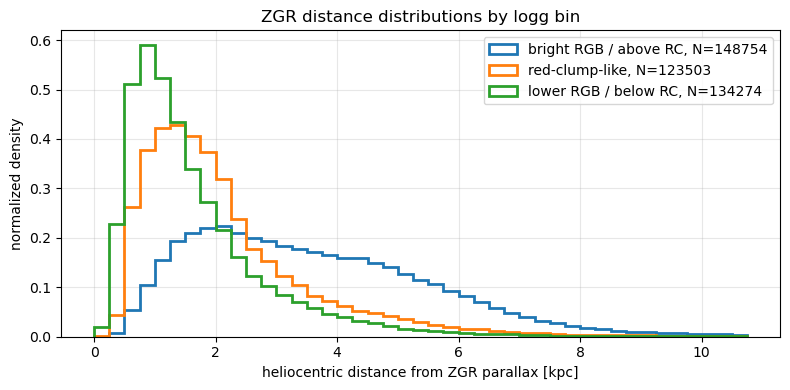

In [139]:
fig, ax = plt.subplots(figsize=(8, 4))

bins = np.arange(0, np.nanpercentile(dist_kpc[base], 99.5) + 0.25, 0.25)

for name, mask in {
    "bright RGB / above RC": m_bright_rgb,
    "red-clump-like": m_rc_like,
    "lower RGB / below RC": m_lower_rgb,
}.items():
    ax.hist(
        dist_kpc[mask],
        bins=bins,
        histtype="step",
        linewidth=2,
        density=True,
        label=f"{name}, N={mask.sum()}"
    )

ax.set_xlabel("heliocentric distance from ZGR parallax [kpc]")
ax.set_ylabel("normalized density")
ax.set_title("ZGR distance distributions by logg bin")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

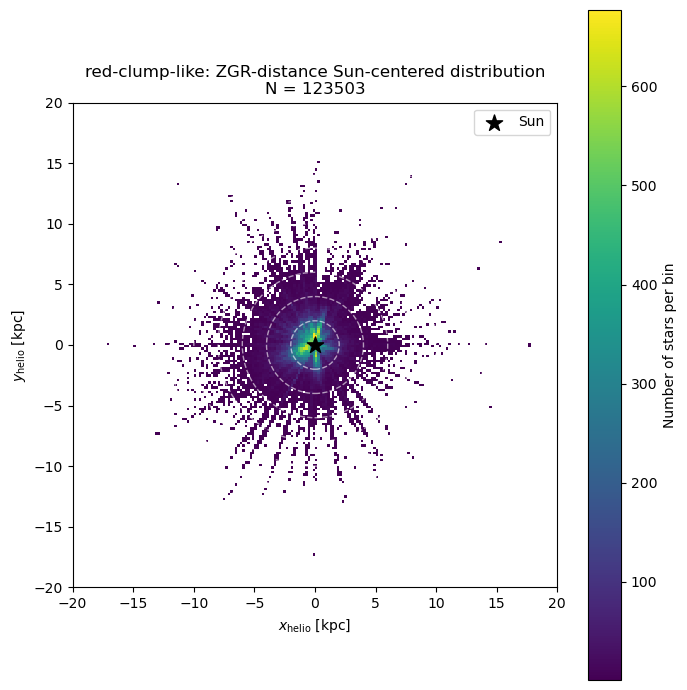

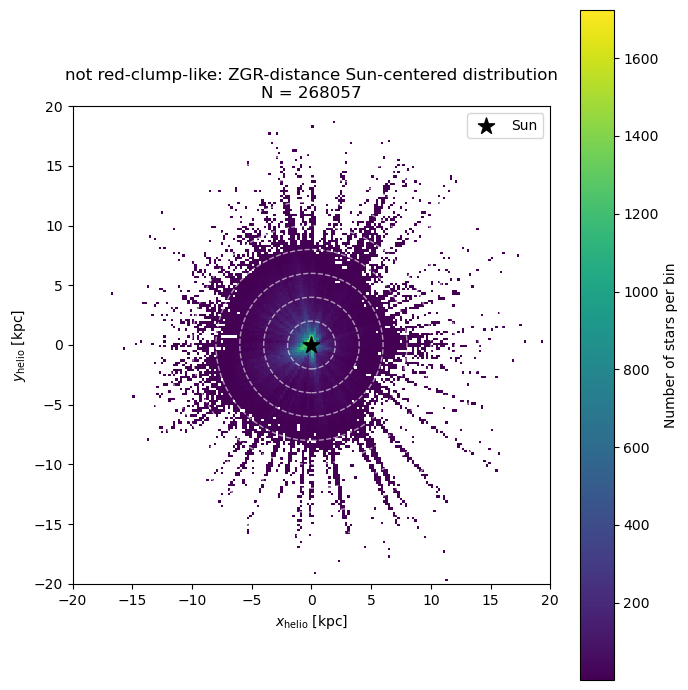

In [140]:
compare_groups = {
    "red-clump-like": m_rc_like,
    "not red-clump-like": m_not_rc,
}

for name, mask in compare_groups.items():
    x, y = helio_xy_from_mask(mask)

    fig, ax = plt.subplots(figsize=(7, 7))

    h = ax.hist2d(
        x,
        y,
        bins=200,
        range=[[-20, 20], [-20, 20]],
        cmin=1
    )

    cb = plt.colorbar(h[3], ax=ax)
    cb.set_label("Number of stars per bin")

    ax.scatter(0, 0, marker="*", s=150, color="black", label="Sun")

    for r in [2, 4, 6, 8, 10, 12, 14, 16]:
        circle = plt.Circle(
            (0, 0),
            r,
            fill=False,
            color="white",
            alpha=0.6,
            linestyle="--",
            linewidth=1
        )
        ax.add_patch(circle)

    ax.set_xlabel(r"$x_{\rm helio}$ [kpc]")
    ax.set_ylabel(r"$y_{\rm helio}$ [kpc]")
    ax.set_title(f"{name}: ZGR-distance Sun-centered distribution\nN = {mask.sum()}")

    ax.set_aspect("equal", adjustable="box")
    ax.legend(loc="upper right")

    plt.tight_layout()
    plt.show()

In [101]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord

tab = t_final

def find_col(tab, possible_names, required=False):
    for name in possible_names:
        if name in tab.colnames:
            return name
    if required:
        raise KeyError(f"None of these columns found: {possible_names}")
    return None

ra_col   = find_col(tab, ["ra", "RA", "sdss4_ra", "sdss5_ra"], required=True)
dec_col  = find_col(tab, ["dec", "DEC", "sdss4_dec", "sdss5_dec"], required=True)
plx_col  = find_col(tab, ["zgr_plx", "ZGR_PLX"], required=True)
logg_col = find_col(tab, ["logg", "LOGG"], required=True)
teff_col = find_col(tab, ["teff", "TEFF"], required=True)

fe_col = find_col(tab, ["fe_h", "FE_H"], required=True)
mg_col = find_col(tab, ["mg_h", "MG_H"], required=True)

ra   = np.asarray(tab[ra_col], dtype=float)
dec  = np.asarray(tab[dec_col], dtype=float)
plx  = np.asarray(tab[plx_col], dtype=float)
logg = np.asarray(tab[logg_col], dtype=float)
teff = np.asarray(tab[teff_col], dtype=float)

fe   = np.asarray(tab[fe_col], dtype=float)
mg   = np.asarray(tab[mg_col], dtype=float)
mgfe = mg - fe

# ZGR parallax distance
dist_kpc = np.full(len(tab), np.nan)
good_plx = np.isfinite(plx) & (plx > 0)
dist_kpc[good_plx] = 1.0 / plx[good_plx]  # kpc if parallax is in mas

base = (
    np.isfinite(ra)
    & np.isfinite(dec)
    & np.isfinite(dist_kpc)
    & (dist_kpc > 0)
    & np.isfinite(logg)
    & np.isfinite(teff)
    & np.isfinite(mgfe)
)

print("len(t_final):", len(t_final))
print("usable with ZGR distance + logg + chemistry:", int(base.sum()))

len(t_final): 391560
usable with ZGR distance + logg + chemistry: 391560


In [102]:
c = SkyCoord(
    ra=ra[base] * u.deg,
    dec=dec[base] * u.deg,
    distance=dist_kpc[base] * u.kpc,
    frame="icrs"
)

galcen = c.transform_to(
    coord.Galactocentric(
        galcen_distance=8.275 * u.kpc,
        galcen_v_sun=[8, 254, 8] * u.km / u.s
    )
)

X_zgr = galcen.x.to_value(u.kpc)
Y_zgr = galcen.y.to_value(u.kpc)
Z_zgr = galcen.z.to_value(u.kpc)

R_zgr   = np.sqrt(X_zgr**2 + Y_zgr**2)
phi_zgr = np.arctan2(Y_zgr, X_zgr)

logg_zgr = logg[base]
teff_zgr = teff[base]
mgfe_zgr = mgfe[base]

print("ZGR coordinate sample:", len(R_zgr))

ZGR coordinate sample: 391560


In [111]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

tab = t_final

def find_col(tab, possible_names, required=False):
    for name in possible_names:
        if name in tab.colnames:
            return name
    if required:
        raise KeyError(f"None of these columns found: {possible_names}")
    return None

teff_col = find_col(tab, ["teff", "TEFF"], required=True)
logg_col = find_col(tab, ["logg", "LOGG"], required=True)

teff = np.asarray(tab[teff_col], dtype=float)
logg = np.asarray(tab[logg_col], dtype=float)

base = np.isfinite(teff) & np.isfinite(logg)

print("len(t_final):", len(t_final))
print("usable Teff/logg:", int(base.sum()))

len(t_final): 391560
usable Teff/logg: 391560


In [122]:
# --------------------------------------------------
# Define a more precise RC-like box in Kiel space
# --------------------------------------------------
rc_teff_min, rc_teff_max = 4450, 4900
rc_logg_min, rc_logg_max = 2.3, 2.5

m_rc_like = (
    base
    & (teff >= rc_teff_min)
    & (teff <= rc_teff_max)
    & (logg >= rc_logg_min)
    & (logg <= rc_logg_max)
)

# Brighter than the red clump = lower surface gravity
m_bright_rgb = (
    base
    & (logg < rc_logg_min)
)

# Fainter/lower RGB = higher surface gravity
m_lower_rgb = (
    base
    & (logg > rc_logg_max)
    & (logg < 3.6)
)

# Outside the box but in the same broad logg range
m_other_same_logg = (
    base
    & (logg >= rc_logg_min)
    & (logg <= rc_logg_max)
    & ~m_rc_like
)

print(f"{'group':30s} {'N':>10s} {'frac usable':>12s}")
print("-" * 58)
for name, mask in {
    "RC-like Teff-logg box": m_rc_like,
    "bright RGB / above RC": m_bright_rgb,
    "lower RGB / fainter giants": m_lower_rgb,
    "same logg but outside RC box": m_other_same_logg,
}.items():
    print(f"{name:30s} {mask.sum():10d} {mask.sum()/base.sum():12.4f}")

group                                   N  frac usable
----------------------------------------------------------
RC-like Teff-logg box               93952       0.2399
bright RGB / above RC              148754       0.3799
lower RGB / fainter giants         134274       0.3429
same logg but outside RC box        11425       0.0292


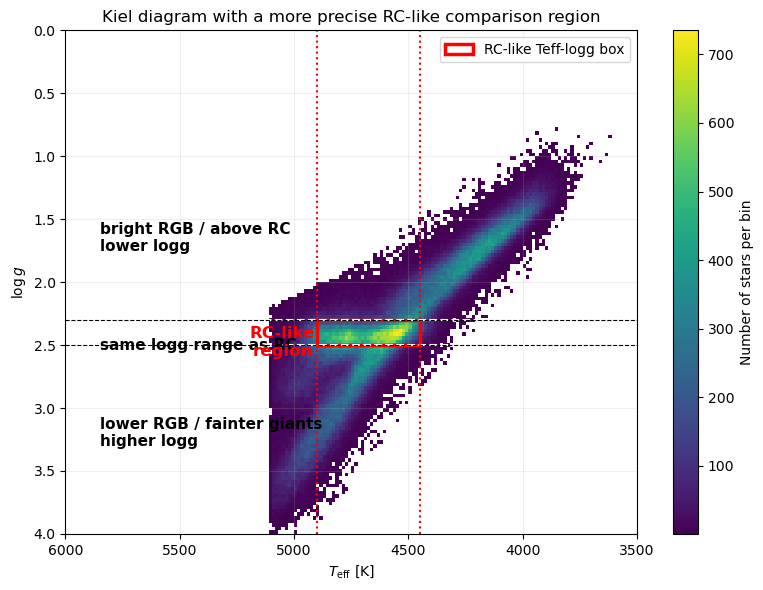

In [124]:
fig, ax = plt.subplots(figsize=(8, 6))

# Background density
h = ax.hist2d(
    teff[base],
    logg[base],
    bins=[180, 140],
    range=[[3500, 6000], [0.0, 4.0]],
    cmin=1
)

cb = plt.colorbar(h[3], ax=ax)
cb.set_label("Number of stars per bin")

# RC-like box
rc_box = Rectangle(
    (rc_teff_min, rc_logg_min),
    rc_teff_max - rc_teff_min,
    rc_logg_max - rc_logg_min,
    fill=False,
    edgecolor="red",
    linewidth=2.5,
    label="RC-like Teff-logg box"
)
ax.add_patch(rc_box)

# Horizontal boundaries for brighter/fainter than RC
ax.axhline(rc_logg_min, color="white", linestyle="--", linewidth=1.5)
ax.axhline(rc_logg_max, color="white", linestyle="--", linewidth=1.5)

ax.axhline(rc_logg_min, color="black", linestyle="--", linewidth=0.8)
ax.axhline(rc_logg_max, color="black", linestyle="--", linewidth=0.8)

# Optional vertical boundaries of the RC-like box
ax.axvline(rc_teff_min, color="red", linestyle=":", linewidth=1.5)
ax.axvline(rc_teff_max, color="red", linestyle=":", linewidth=1.5)

# Labels
ax.text(
    5850, 1.65,
    "bright RGB / above RC\nlower logg",
    color="black",
    fontsize=11,
    weight="bold",
    va="center"
)

ax.text(
    5850, 2.50,
    "same logg range as RC",
    color="black",
    fontsize=11,
    weight="bold",
    va="center"
)

ax.text(
    5850, 3.20,
    "lower RGB / fainter giants\nhigher logg",
    color="black",
    fontsize=11,
    weight="bold",
    va="center"
)

ax.text(
    5050, 2.48,
    "RC-like\nregion",
    color="red",
    fontsize=12,
    weight="bold",
    ha="center",
    va="center"
)

ax.set_xlabel(r"$T_{\rm eff}$ [K]")
ax.set_ylabel(r"$\log g$")
ax.set_title("Kiel diagram with a more precise RC-like comparison region")

# Kiel diagram convention
ax.set_xlim(6000, 3500)
ax.set_ylim(4.0, 0.0)

ax.grid(alpha=0.2)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

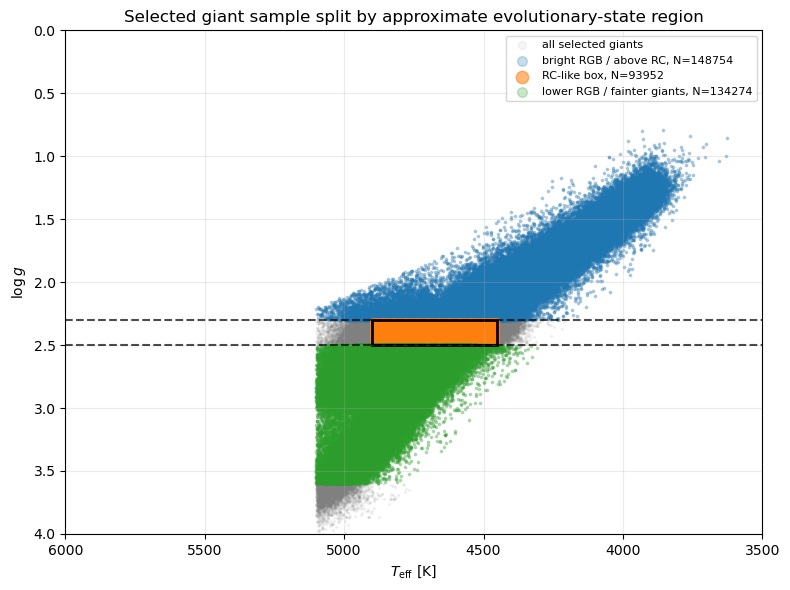

In [125]:
fig, ax = plt.subplots(figsize=(8, 6))

# Full sample background
ax.scatter(
    teff[base],
    logg[base],
    s=2,
    alpha=0.08,
    color="gray",
    rasterized=True,
    label="all selected giants"
)

ax.scatter(
    teff[m_bright_rgb],
    logg[m_bright_rgb],
    s=3,
    alpha=0.25,
    rasterized=True,
    label=f"bright RGB / above RC, N={m_bright_rgb.sum()}"
)

ax.scatter(
    teff[m_rc_like],
    logg[m_rc_like],
    s=5,
    alpha=0.55,
    rasterized=True,
    label=f"RC-like box, N={m_rc_like.sum()}"
)

ax.scatter(
    teff[m_lower_rgb],
    logg[m_lower_rgb],
    s=3,
    alpha=0.25,
    rasterized=True,
    label=f"lower RGB / fainter giants, N={m_lower_rgb.sum()}"
)

# Draw RC box
rc_box = Rectangle(
    (rc_teff_min, rc_logg_min),
    rc_teff_max - rc_teff_min,
    rc_logg_max - rc_logg_min,
    fill=False,
    edgecolor="black",
    linewidth=2.0
)
ax.add_patch(rc_box)

ax.axhline(rc_logg_min, color="black", linestyle="--", alpha=0.7)
ax.axhline(rc_logg_max, color="black", linestyle="--", alpha=0.7)

ax.set_xlabel(r"$T_{\rm eff}$ [K]")
ax.set_ylabel(r"$\log g$")
ax.set_title("Selected giant sample split by approximate evolutionary-state region")

ax.set_xlim(6000, 3500)
ax.set_ylim(4.0, 0.0)

ax.grid(alpha=0.25)
ax.legend(markerscale=4, fontsize=8, loc="best")

plt.tight_layout()
plt.show()

In [128]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord

tab = t_final

def find_col(tab, possible_names, required=False):
    for name in possible_names:
        if name in tab.colnames:
            return name
    if required:
        raise KeyError(f"None of these columns found: {possible_names}")
    return None

ra_col   = find_col(tab, ["ra", "RA", "sdss4_ra", "sdss5_ra"], required=True)
dec_col  = find_col(tab, ["dec", "DEC", "sdss4_dec", "sdss5_dec"], required=True)
plx_col  = find_col(tab, ["zgr_plx", "ZGR_PLX"], required=True)

teff_col = find_col(tab, ["teff", "TEFF"], required=True)
logg_col = find_col(tab, ["logg", "LOGG"], required=True)

fe_col = find_col(tab, ["fe_h", "FE_H"], required=True)
mg_col = find_col(tab, ["mg_h", "MG_H"], required=True)

ra   = np.asarray(tab[ra_col], dtype=float)
dec  = np.asarray(tab[dec_col], dtype=float)
plx  = np.asarray(tab[plx_col], dtype=float)

teff = np.asarray(tab[teff_col], dtype=float)
logg = np.asarray(tab[logg_col], dtype=float)

fe   = np.asarray(tab[fe_col], dtype=float)
mg   = np.asarray(tab[mg_col], dtype=float)
mgfe = mg - fe

# ZGR parallax distance
dist_kpc = np.full(len(tab), np.nan)
good_plx = np.isfinite(plx) & (plx > 0)
dist_kpc[good_plx] = 1.0 / plx[good_plx]

base = (
    np.isfinite(ra)
    & np.isfinite(dec)
    & np.isfinite(dist_kpc)
    & (dist_kpc > 0)
    & np.isfinite(teff)
    & np.isfinite(logg)
    & np.isfinite(mgfe)
)

# adopted RC-like box
rc_teff_min, rc_teff_max = 4450, 4compare_groups = {
    "RC-like": rc_b,
    "not RC-like": not_rc_b,
}

for name, mask in compare_groups.items():
    fig, ax = plt.subplots(figsize=(7, 5))

    h = ax.hist2d(
        Z[mask],
        mgfe_b[mask],
        bins=[160, 120],
        range=[[-3, 3], [-0.2, 0.6]],
        cmin=1
    )

    cb = plt.colorbar(h[3], ax=ax)
    cb.set_label("Number of stars per bin")

    ax.set_xlabel(r"$Z_{\rm Gal}$ from ZGR distances [kpc]")
    ax.set_ylabel(r"$[\mathrm{Mg}/\mathrm{Fe}]$")
    ax.set_title(f"{name}: [Mg/Fe] vs Z\nN = {mask.sum()}")

    plt.tight_layout()
    plt.show()900
rc_logg_min, rc_logg_max = 2.3, 2.6

m_rc_like = (
    base
    & (teff >= rc_teff_min)
    & (teff <= rc_teff_max)
    & (logg >= rc_logg_min)
    & (logg <= rc_logg_max)
)

m_not_rc = base & ~m_rc_like

m_brighter_than_rc = base & (logg < rc_logg_min)
m_fainter_than_rc  = base & (logg > rc_logg_max)

print("usable base sample:", base.sum())
print("RC-like:", m_rc_like.sum())
print("not RC-like:", m_not_rc.sum())
print("brighter than RC:", m_brighter_than_rc.sum())
print("fainter than RC:", m_fainter_than_rc.sum())

usable base sample: 391560
RC-like: 123503
not RC-like: 268057
brighter than RC: 148754
fainter than RC: 103868


In [129]:
c = SkyCoord(
    ra=ra[base] * u.deg,
    dec=dec[base] * u.deg,
    distance=dist_kpc[base] * u.kpc,
    frame="icrs"
)

galcen = c.transform_to(
    coord.Galactocentric(
        galcen_distance=8.275 * u.kpc,
        galcen_v_sun=[8, 254, 8] * u.km / u.s
    )
)

X = galcen.x.to_value(u.kpc)
Y = galcen.y.to_value(u.kpc)
Z = galcen.z.to_value(u.kpc)

R = np.sqrt(X**2 + Y**2)
phi = np.arctan2(Y, X)

# These arrays are now only for the base sample,
# so also reduce the masks/quantities to base length.
teff_b = teff[base]
logg_b = logg[base]
mgfe_b = mgfe[base]
dist_b = dist_kpc[base]

rc_b = m_rc_like[base]
not_rc_b = ~rc_b

bright_b = m_brighter_than_rc[base]
faint_b  = m_fainter_than_rc[base]

print("coordinate sample:", len(R))
print("RC-like in coordinate sample:", rc_b.sum())
print("not RC-like in coordinate sample:", not_rc_b.sum())

coordinate sample: 391560
RC-like in coordinate sample: 123503
not RC-like in coordinate sample: 268057


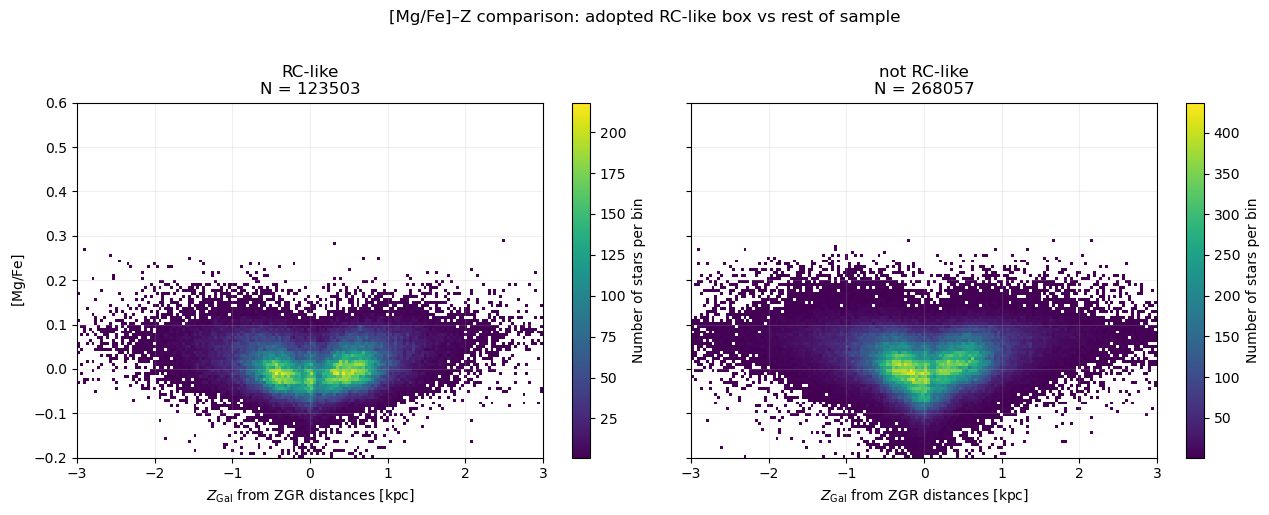

In [130]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)

groups = [
    ("RC-like", rc_b),
    ("not RC-like", not_rc_b),
]

for ax, (name, mask) in zip(axes, groups):
    h = ax.hist2d(
        Z[mask],
        mgfe_b[mask],
        bins=[160, 120],
        range=[[-3, 3], [-0.2, 0.6]],
        cmin=1
    )

    cb = plt.colorbar(h[3], ax=ax)
    cb.set_label("Number of stars per bin")

    ax.set_title(f"{name}\nN = {mask.sum()}")
    ax.set_xlabel(r"$Z_{\rm Gal}$ from ZGR distances [kpc]")
    ax.grid(alpha=0.2)

axes[0].set_ylabel(r"$[\mathrm{Mg}/\mathrm{Fe}]$")

fig.suptitle("[Mg/Fe]–Z comparison: adopted RC-like box vs rest of sample", y=1.02)
plt.tight_layout()
plt.show()

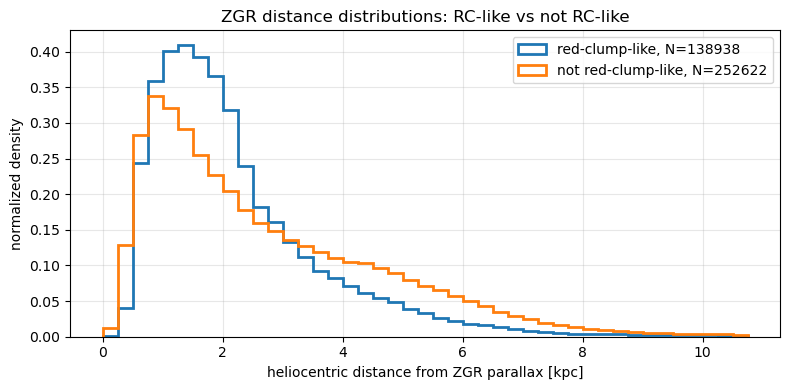

In [132]:
fig, ax = plt.subplots(figsize=(8, 4))

bins = np.arange(0, np.nanpercentile(dist_b, 99.5) + 0.25, 0.25)

for name, mask in compare_groups.items():
    ax.hist(
        dist_b[mask],
        bins=bins,
        histtype="step",
        linewidth=2,
        density=True,
        label=f"{name}, N={mask.sum()}"
    )

ax.set_xlabel("heliocentric distance from ZGR parallax [kpc]")
ax.set_ylabel("normalized density")
ax.set_title("ZGR distance distributions: RC-like vs not RC-like")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

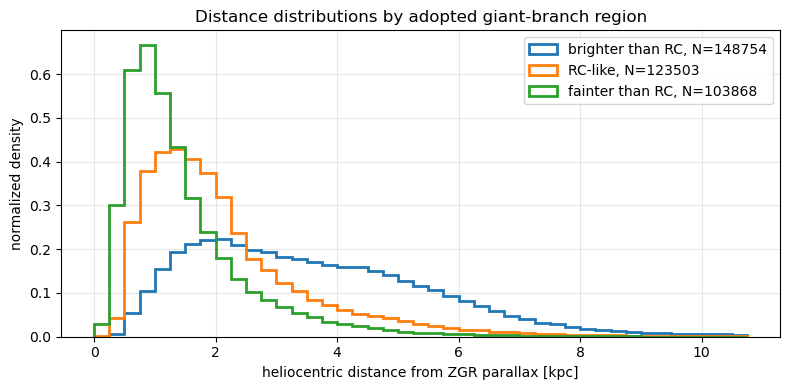

In [133]:
evolution_groups = {
    "brighter than RC": bright_b,
    "RC-like": rc_b,
    "fainter than RC": faint_b,
}

fig, ax = plt.subplots(figsize=(8, 4))

bins = np.arange(0, np.nanpercentile(dist_b, 99.5) + 0.25, 0.25)

for name, mask in evolution_groups.items():
    ax.hist(
        dist_b[mask],
        bins=bins,
        histtype="step",
        linewidth=2,
        density=True,
        label=f"{name}, N={mask.sum()}"
    )

ax.set_xlabel("heliocentric distance from ZGR parallax [kpc]")
ax.set_ylabel("normalized density")
ax.set_title("Distance distributions by adopted giant-branch region")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

4. Make a top-down visualization of the Galaxy showing the typical distance uncertainty in each spatial bin


In [134]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord
from scipy.stats import binned_statistic_2d

tab = t_final

def find_col(tab, possible_names, required=False):
    for name in possible_names:
        if name in tab.colnames:
            return name
    if required:
        raise KeyError(f"None of these columns found: {possible_names}")
    return None

ra_col  = find_col(tab, ["ra", "RA", "sdss4_ra", "sdss5_ra"], required=True)
dec_col = find_col(tab, ["dec", "DEC", "sdss4_dec", "sdss5_dec"], required=True)

# ZGR parallax and uncertainty columns
plx_col = find_col(tab, ["zgr_plx", "ZGR_PLX"], required=True)

# Try likely uncertainty names
plxerr_col = find_col(
    tab,
    [
        "zgr_plx_error", "zgr_plx_err", "zgr_e_plx", "e_zgr_plx",
        "parallax_error", "PARALLAX_ERROR"
    ],
    required=False
)

print("Using parallax column:", plx_col)
print("Using parallax error column:", plxerr_col)

ra  = np.asarray(tab[ra_col], dtype=float)
dec = np.asarray(tab[dec_col], dtype=float)
plx = np.asarray(tab[plx_col], dtype=float)

if plxerr_col is None:
    raise KeyError(
        "Could not find a parallax uncertainty column. "
        "Check t_final.colnames for the ZGR parallax error name."
    )

plx_err = np.asarray(tab[plxerr_col], dtype=float)

# ZGR distance and propagated uncertainty
dist_kpc = np.full(len(tab), np.nan)
dist_err_kpc = np.full(len(tab), np.nan)
frac_dist_err = np.full(len(tab), np.nan)

good_plx = (
    np.isfinite(plx)
    & np.isfinite(plx_err)
    & (plx > 0)
    & (plx_err > 0)
)

dist_kpc[good_plx] = 1.0 / plx[good_plx]
dist_err_kpc[good_plx] = plx_err[good_plx] / plx[good_plx]**2
frac_dist_err[good_plx] = plx_err[good_plx] / plx[good_plx]

base = (
    np.isfinite(ra)
    & np.isfinite(dec)
    & np.isfinite(dist_kpc)
    & np.isfinite(dist_err_kpc)
    & np.isfinite(frac_dist_err)
    & (dist_kpc > 0)
    & (dist_err_kpc > 0)
)

print("len(t_final):", len(t_final))
print("usable with ZGR distance uncertainty:", int(base.sum()))

Using parallax column: zgr_plx
Using parallax error column: zgr_e_plx
len(t_final): 391560
usable with ZGR distance uncertainty: 391560


In [135]:
c = SkyCoord(
    ra=ra[base] * u.deg,
    dec=dec[base] * u.deg,
    distance=dist_kpc[base] * u.kpc,
    frame="icrs"
)

galcen = c.transform_to(
    coord.Galactocentric(
        galcen_distance=8.275 * u.kpc,
        galcen_v_sun=[8, 254, 8] * u.km / u.s
    )
)

X = galcen.x.to_value(u.kpc)
Y = galcen.y.to_value(u.kpc)
R = np.sqrt(X**2 + Y**2)

d_err = dist_err_kpc[base]
frac_err = frac_dist_err[base]

print("coordinate sample:", len(X))
print("median distance uncertainty [kpc]:", np.nanmedian(d_err))
print("median fractional distance uncertainty:", np.nanmedian(frac_err))

coordinate sample: 391560
median distance uncertainty [kpc]: 0.05627679093087674
median fractional distance uncertainty: 0.02815457784158527


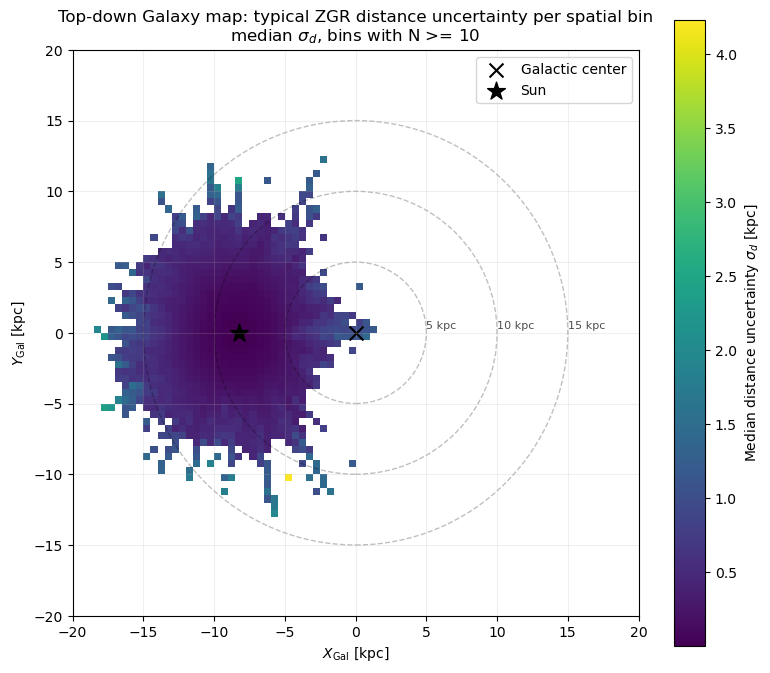

In [136]:
# Spatial binning
x_edges = np.arange(-20, 20.5, 0.5)
y_edges = np.arange(-20, 20.5, 0.5)

stat, x_edges_out, y_edges_out, binnum = binned_statistic_2d(
    X,
    Y,
    d_err,
    statistic="median",
    bins=[x_edges, y_edges]
)

count, _, _, _ = binned_statistic_2d(
    X,
    Y,
    d_err,
    statistic="count",
    bins=[x_edges, y_edges]
)

# Mask bins with too few stars
min_count = 10
stat_masked = np.ma.masked_where(count < min_count, stat)

fig, ax = plt.subplots(figsize=(8, 7))

im = ax.pcolormesh(
    x_edges,
    y_edges,
    stat_masked.T,
    shading="auto"
)

cb = plt.colorbar(im, ax=ax)
cb.set_label(r"Median distance uncertainty $\sigma_d$ [kpc]")

# Mark Galactic center and Sun
ax.scatter(0, 0, marker="x", s=100, color="black", label="Galactic center")
ax.scatter(-8.275, 0, marker="*", s=180, color="black", label="Sun")

# Optional Galactocentric radius circles
for r in [5, 10, 15]:
    circ = plt.Circle((0, 0), r, fill=False, color="black", alpha=0.25, linestyle="--")
    ax.add_patch(circ)
    ax.text(r, 0.3, f"{r} kpc", fontsize=8, color="black", alpha=0.7)

ax.set_xlabel(r"$X_{\rm Gal}$ [kpc]")
ax.set_ylabel(r"$Y_{\rm Gal}$ [kpc]")
ax.set_title(
    "Top-down Galaxy map: typical ZGR distance uncertainty per spatial bin\n"
    f"median $\\sigma_d$, bins with N >= {min_count}"
)

ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-20, 20)
ax.set_ylim(-20, 20)
ax.legend(loc="upper right")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Flare

In [150]:
from tqdm import tqdm
import jax
import jax.random as jr

# radial edges — adjust to whatever range you want
# R_edges_flare = np.arange(4, 16, 0.5)
# n_R_flare = len(R_edges_flare) - 1
# R_centers_flare = 0.5 * (R_edges_flare[:-1] + R_edges_flare[1:])

#TEMPORARY
#R_centers_flare = np.arange(7, 9+1e-3, 0.5)
R_centers_flare = np.arange(4, 15+1e-3, 0.5)
R_width = 1.0
n_R_flare = len(R_centers_flare)

R_arr     = np.asarray(R_star)
Z_arr     = np.asarray(Z_star)
mgfe_arr  = np.asarray(mgfe_star)
err_arr   = np.asarray(mgfe_err_star)

m_base = (
    np.isfinite(R_arr) & np.isfinite(Z_arr)
    & np.isfinite(mgfe_arr) & np.isfinite(err_arr)
    & (err_arr > 0)
)

# store results
per_R_flare = {}
key = jr.PRNGKey(0)

for i_R in tqdm(range(n_R_flare), desc="fitting radial bins"):
    # Rlo, Rhi = R_edges_flare[i_R], R_edges_flare[i_R + 1]
    Rlo = R_centers_flare[i_R] - R_width / 2
    Rhi = R_centers_flare[i_R] + R_width / 2
    
    m = m_base & (R_arr >= Rlo) & (R_arr < Rhi)
    n_stars = int(m.sum())
    
    if n_stars < minN_seg_total:
        print(f"R=[{Rlo:.1f},{Rhi:.1f}]: skipping, only {n_stars} stars")
        continue
    
    z_binc, mean_mg_fe, mean_mg_fe_err, counts = bin_one(
        Z_arr[m], mgfe_arr[m], err_arr[m]
    )
    
    good = (
        np.isfinite(mean_mg_fe) & np.isfinite(mean_mg_fe_err)
        & (counts >= min_bin_count)
        & (z_binc >= z_fit_min) & (z_binc <= z_fit_max)
    )
    
    if good.sum() < min_bins_for_fit:
        print(f"R=[{Rlo:.1f},{Rhi:.1f}]: skipping, only {good.sum()} good bins")
        continue
    
    try:
        key, sub = jr.split(key)
        sampler = fit_sech2(
            np.asarray(z_binc[good], float),
            np.asarray(mean_mg_fe[good], float),
            np.asarray(mean_mg_fe_err[good], float),
            sub,
            progress_bar=False
        )
        samples = sampler.get_samples()
        per_R_flare[i_R] = {
            "Rlo": Rlo, "Rhi": Rhi,
            "n_stars": n_stars,
            "z_binc": np.asarray(z_binc[good]),
            "mean": np.asarray(mean_mg_fe[good]),
            "err": np.asarray(mean_mg_fe_err[good]),
            "samples": {k: np.asarray(v) for k, v in samples.items()},
        }
        print(f"R=[{Rlo:.1f},{Rhi:.1f}]: fit ok, n_stars={n_stars}")
    except Exception as e:
        print(f"R=[{Rlo:.1f},{Rhi:.1f}]: fit failed -> {e}")

print(f"fits complete: {len(per_R_flare)}/{n_R_flare}")

import pickle

# save
# with open("per_R_flare.pkl", "wb") as f:
with open("per_R_flare3.pkl", "wb") as f:
    pickle.dump(per_R_flare, f)


fitting radial bins:   0%|                               | 0/23 [00:00<?, ?it/s]/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_6080/3181619348.py:14: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_6080/3181619348.py:15: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_6080/3181619348.py:45: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(
fitting radial bins:   4%|█                      | 1/23 [00:12<04:31, 12.32s/it]

R=[3.5,4.5]: fit ok, n_stars=1993


fitting radial bins:   9%|██                     | 2/23 [00:19<03:13,  9.23s/it]

R=[4.0,5.0]: fit ok, n_stars=2866


fitting radial bins:  13%|███                    | 3/23 [00:27<02:50,  8.50s/it]

...

R=[13.5,14.5]: fit ok, n_stars=5969


fitting radial bins:  96%|█████████████████████ | 22/23 [06:33<00:15, 15.60s/it]

R=[14.0,15.0]: fit ok, n_stars=3903


fitting radial bins: 100%|██████████████████████| 23/23 [06:42<00:00, 17.50s/it]

R=[14.5,15.5]: fit ok, n_stars=2517
fits complete: 23/23


In [155]:
def root_func(z, pars):
    Ystar = mixture_of_sech2(
        z, pars["A1"], pars["A2"], pars["h1"], pars["h2"], pars["z0"]
    )
    return Ystar - 0.5 * (pars["A1"] + pars["A2"])


loaded 23 radial bins


computing h_eff: 100%|██████████████████████████| 23/23 [00:08<00:00,  2.59it/s]


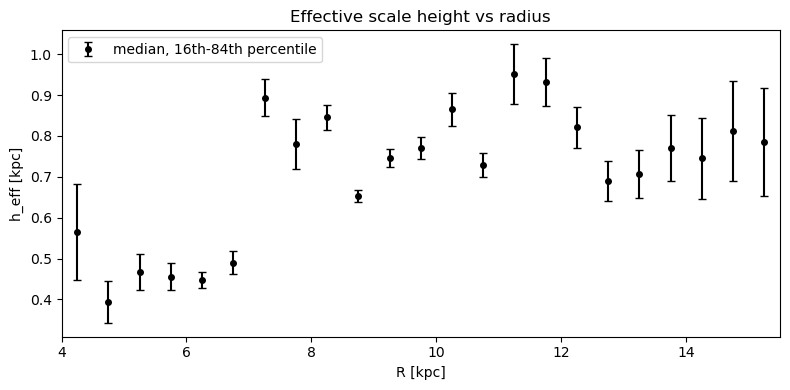

In [157]:
import pickle
import numpy as np
from scipy.optimize import brentq

# reload saved results
with open("per_R_flare3.pkl", "rb") as f:
    per_R_flare = pickle.load(f)
print(f"loaded {len(per_R_flare)} radial bins")

R_edges_flare = np.arange(4, 16, 0.5)
n_R_flare = len(R_edges_flare) - 1
R_centers_flare = 0.5 * (R_edges_flare[:-1] + R_edges_flare[1:])

from tqdm import tqdm
h_eff_med_flare = np.full(n_R_flare, np.nan)
h_eff_std_flare = np.full(n_R_flare, np.nan)

for i_R, cell in tqdm(per_R_flare.items(), desc="computing h_eff"):
    s = cell["samples"]
    
    h_effs = []
    for i in range(256):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        hi = 8 * max(cell_sample["h1"], cell_sample["h2"])
        try:
            zstar = brentq(root_func, cell_sample["z0"] + 1e-9, hi, args=(cell_sample,))
            h_effs.append(zstar - cell_sample["z0"])
        except ValueError:
            continue
    
    if len(h_effs) > 0:
        h_effs = np.array(h_effs)
        h_eff_med_flare[i_R] = np.median(h_effs)
        pcl = np.percentile(h_effs, [16, 84])
        h_eff_std_flare[i_R] = 0.5 * (pcl[1] - pcl[0])

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(R_centers_flare, h_eff_med_flare, yerr=h_eff_std_flare,
            fmt="o", color="k", ms=4, capsize=3,
            label="median, 16th-84th percentile")
ax.legend(loc="upper left")
ax.set_xlabel("R [kpc]")
ax.set_ylabel("h_eff [kpc]")
ax.set_title("Effective scale height vs radius")
ax.set_xlim(R_edges_flare[0], R_edges_flare[-1])
plt.tight_layout()
plt.show()

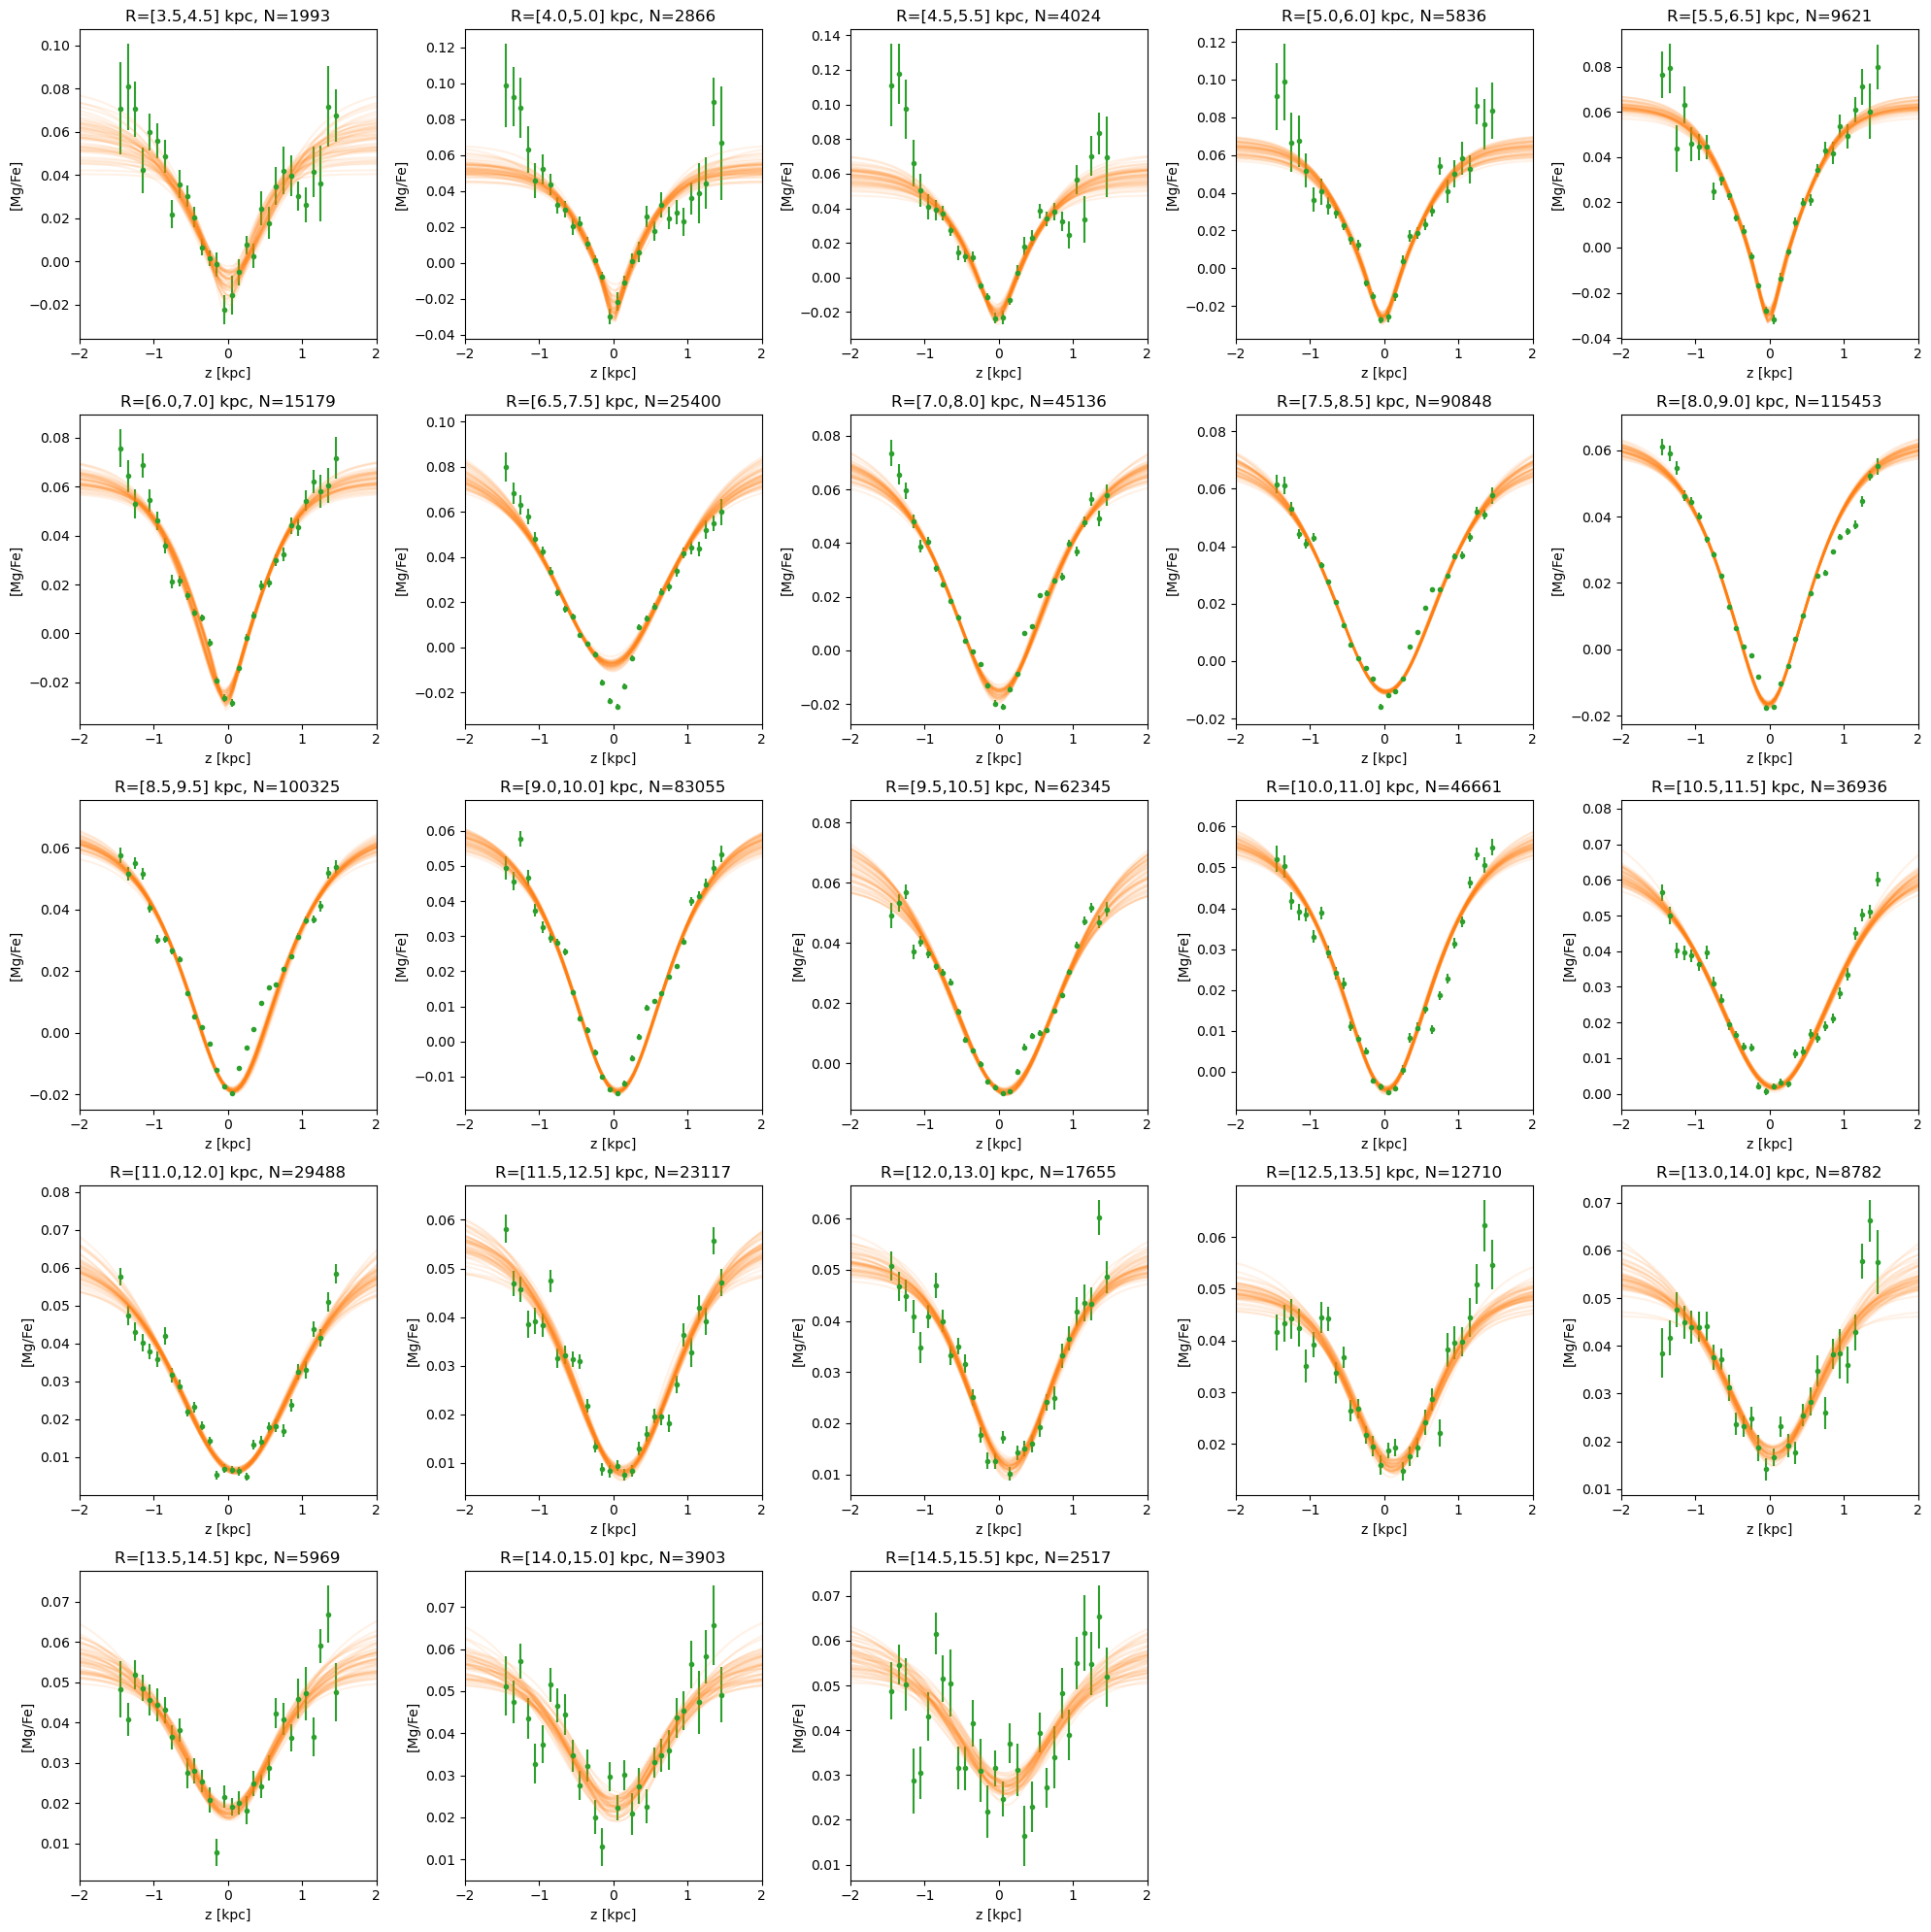

In [158]:
z_grid = np.linspace(-5, 5, 200)
fig, axes = plt.subplots(5, 5, figsize=(20, 20), squeeze=False)

for idx, (i_R, cell) in enumerate(per_R_flare.items()):
    r, c = divmod(idx, 5)
    ax = axes[r, c]
    s = cell["samples"]
    
    ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
                color="C2", linestyle="", marker=".")
    
    for i in range(min(50, len(s["A1"]))):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        y_pred = mixture_of_sech2(z_grid, cell_sample["A1"], cell_sample["A2"],
                                  cell_sample["h1"], cell_sample["h2"],
                                  cell_sample["z0"]) + cell_sample["offset"]
        ax.plot(z_grid, y_pred, color="C1", alpha=0.1)
    
    ax.set_xlabel("z [kpc]")
    ax.set_ylabel("[Mg/Fe]")
    ax.set_title(f"R=[{cell['Rlo']:.1f},{cell['Rhi']:.1f}] kpc, N={cell['n_stars']}")
    ax.set_xlim(-2, 2)

for idx in range(len(per_R_flare), 25):
    r, c = divmod(idx, 5)
    axes[r, c].axis("off")

plt.tight_layout()
plt.show()

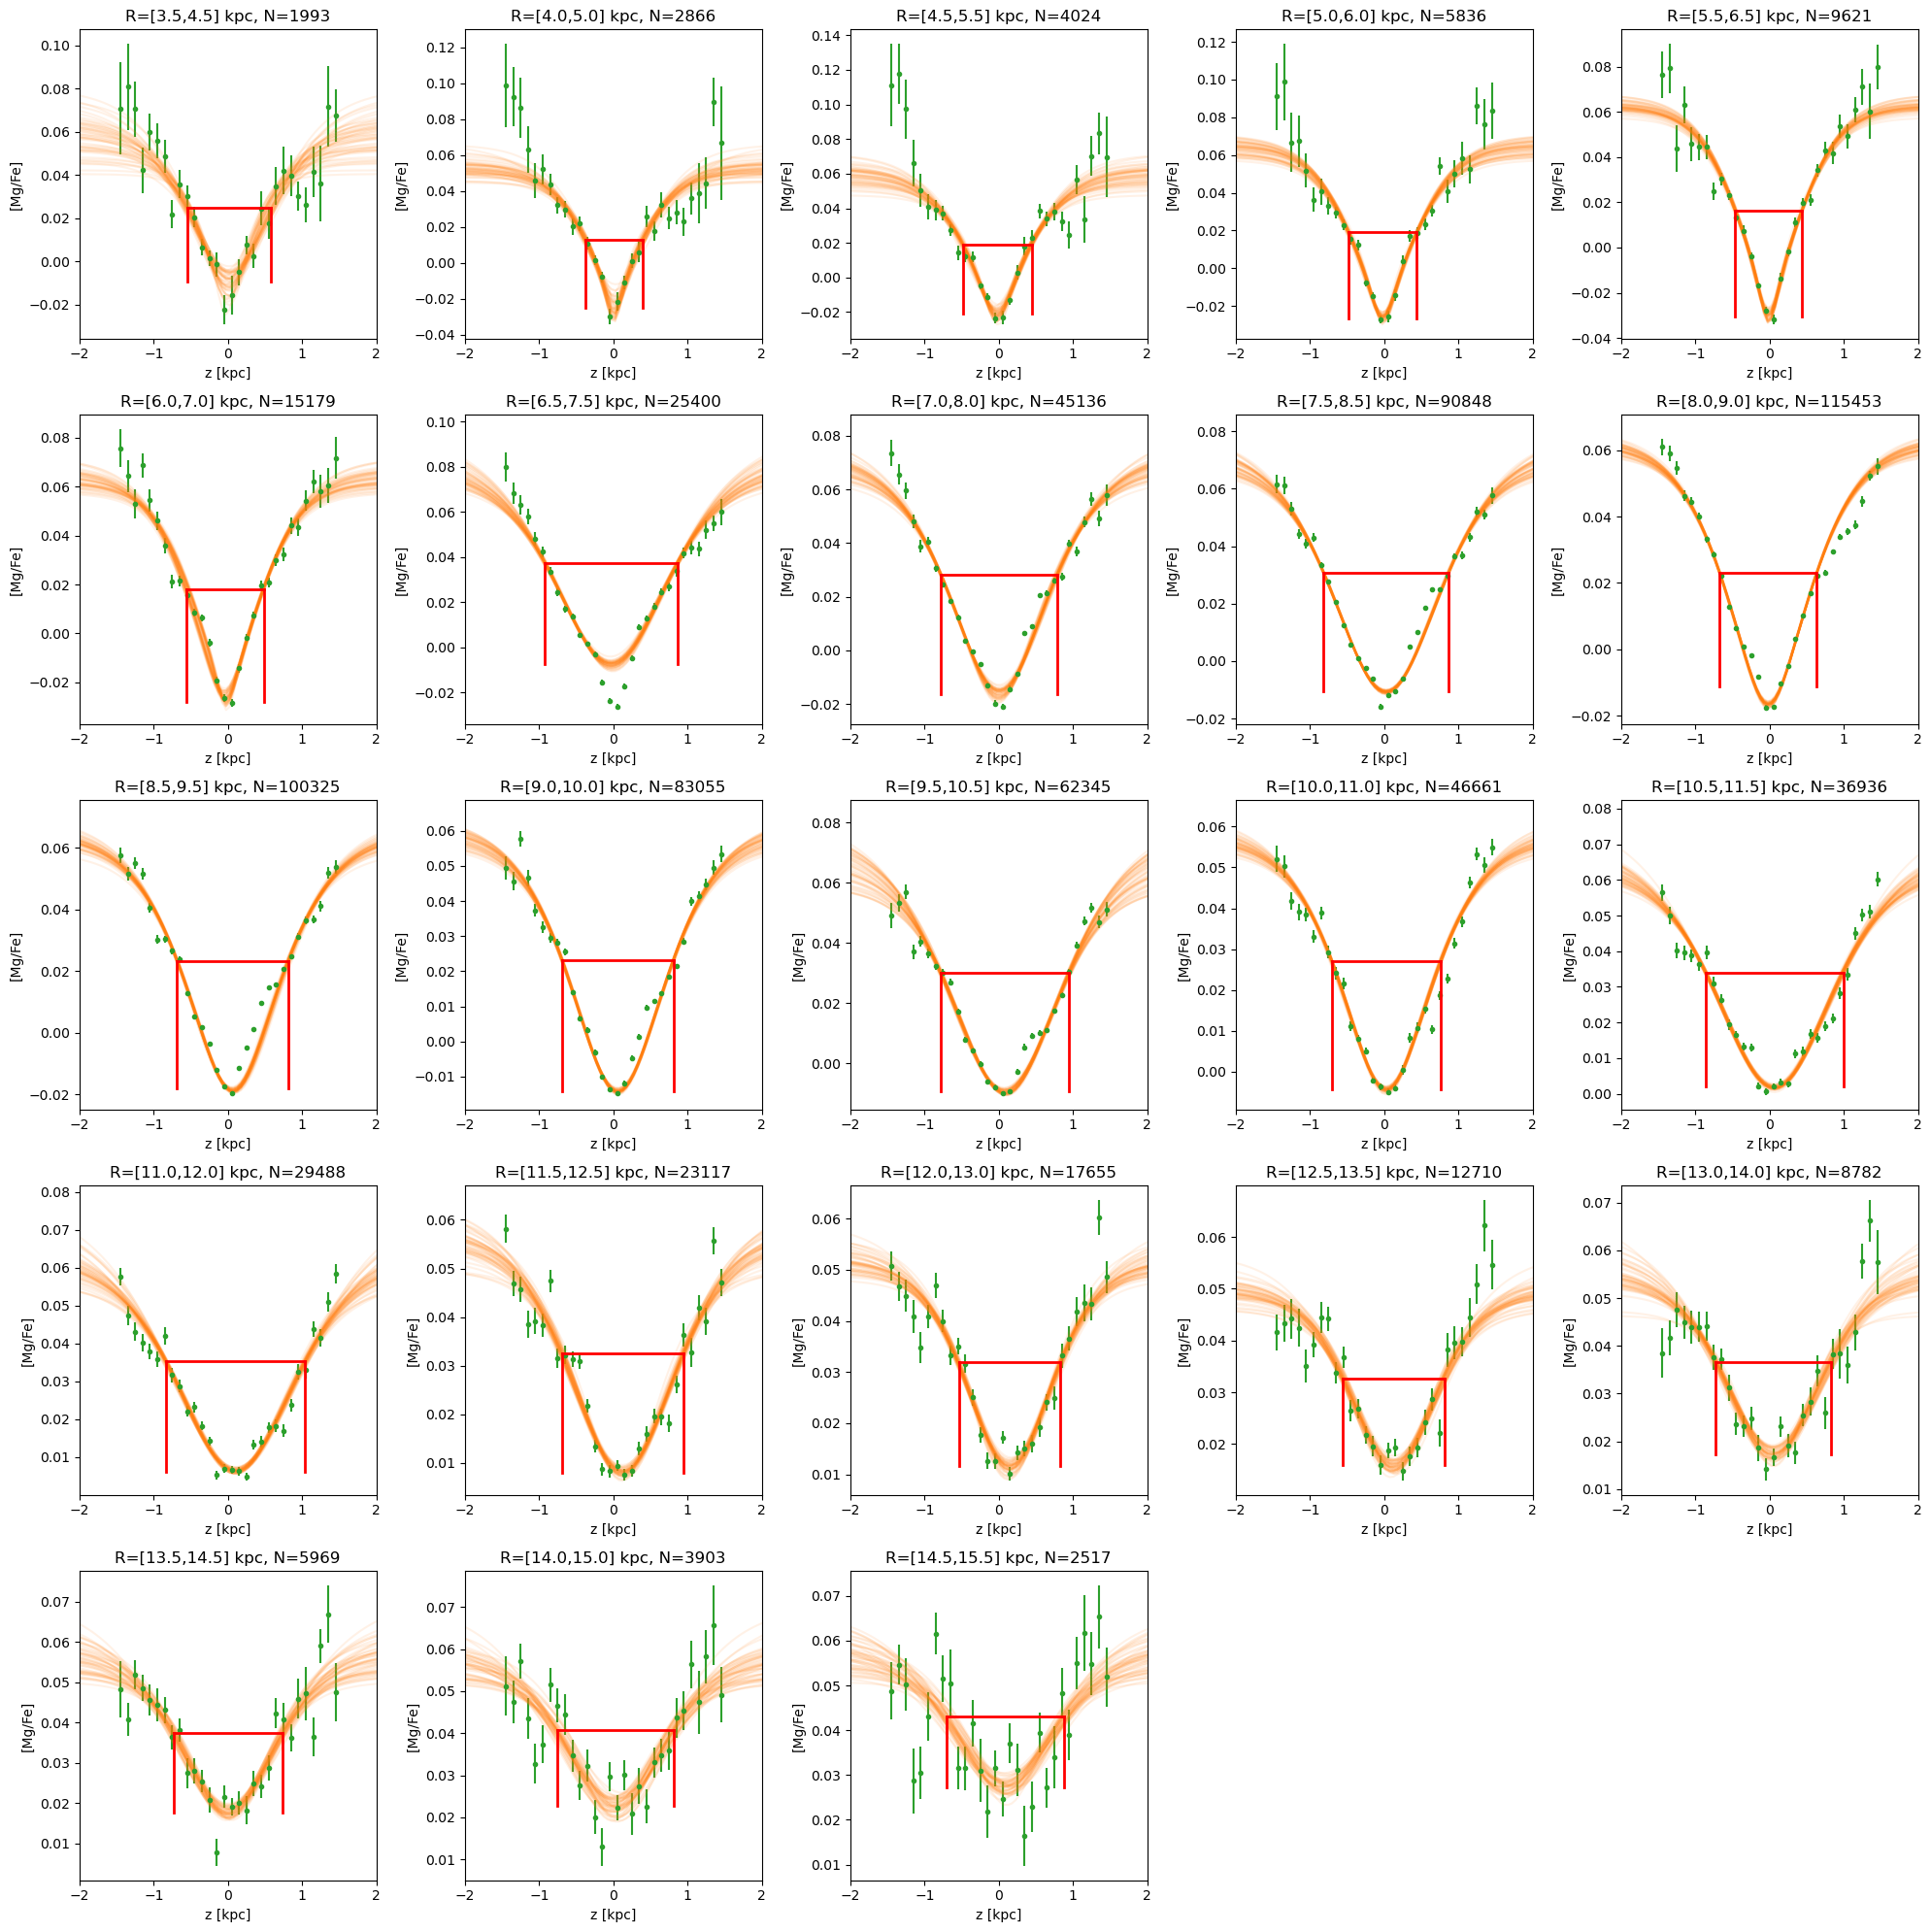

In [159]:
z_grid = np.linspace(-5, 5, 200)
fig, axes = plt.subplots(5, 5, figsize=(20, 20), squeeze=False)

for idx, (i_R, cell) in enumerate(per_R_flare.items()):
    r, c = divmod(idx, 5)
    ax = axes[r, c]
    s = cell["samples"]
    
    ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
                color="C2", linestyle="", marker=".")
    
    for i in range(min(50, len(s["A1"]))):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        y_pred = mixture_of_sech2(z_grid, cell_sample["A1"], cell_sample["A2"],
                                  cell_sample["h1"], cell_sample["h2"],
                                  cell_sample["z0"]) + cell_sample["offset"]
        ax.plot(z_grid, y_pred, color="C1", alpha=0.1)
    
    # compute median zstar on both sides across all draws
    zstar_rights = []
    zstar_lefts = []
    y_halfs = []
    for i in range(min(50, len(s["A1"]))):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        z0 = cell_sample["z0"]
        hi = 8 * max(cell_sample["h1"], cell_sample["h2"])
        half_max = 0.5 * (cell_sample["A1"] + cell_sample["A2"])
        y_half = half_max + cell_sample["offset"]
        try:
            zstar_right = brentq(root_func, z0 + 1e-9, hi, args=(cell_sample,))
            zstar_left = brentq(root_func, -hi, z0 - 1e-9, args=(cell_sample,))
            zstar_rights.append(zstar_right)
            zstar_lefts.append(zstar_left)
            y_halfs.append(y_half)
        except ValueError:
            continue
    
    if len(zstar_rights) > 0:
        med_right = np.median(zstar_rights)
        med_left = np.median(zstar_lefts)
        med_y = np.median(y_halfs)
        med_z0 = np.median(s["z0"])
        y_min = np.median([mixture_of_sech2(med_z0, s["A1"][i], s["A2"][i],
                           s["h1"][i], s["h1"][i] + s["d_h2"][i], med_z0) + s["offset"][i]
                           for i in range(len(s["A1"]))])
        
        # horizontal line at half-max level
        ax.plot([med_left, med_right], [med_y, med_y], color="red", lw=2, zorder=5)
        # vertical lines from half-max down to minimum
        ax.plot([med_left, med_left], [y_min, med_y], color="red", lw=2, zorder=5)
        ax.plot([med_right, med_right], [y_min, med_y], color="red", lw=2, zorder=5)
    
    ax.set_xlabel("z [kpc]")
    ax.set_ylabel("[Mg/Fe]")
    ax.set_title(f"R=[{cell['Rlo']:.1f},{cell['Rhi']:.1f}] kpc, N={cell['n_stars']}")
    ax.set_xlim(-2, 2)

for idx in range(len(per_R_flare), 25):
    r, c = divmod(idx, 5)
    axes[r, c].axis("off")

plt.tight_layout()
plt.show()

loaded 23 radial bins


computing h_eff: 100%|██████████████████████████| 23/23 [00:08<00:00,  2.63it/s]


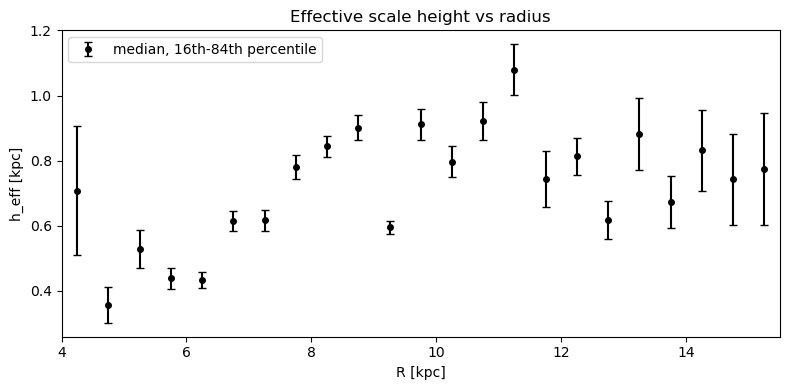

In [160]:
import pickle
import numpy as np
from scipy.optimize import brentq

# reload saved results
with open("per_R_flare.pkl", "rb") as f:
    per_R_flare = pickle.load(f)
print(f"loaded {len(per_R_flare)} radial bins")

R_edges_flare = np.arange(4, 16, 0.5)
n_R_flare = len(R_edges_flare) - 1
R_centers_flare = 0.5 * (R_edges_flare[:-1] + R_edges_flare[1:])

from tqdm import tqdm
h_eff_med_flare = np.full(n_R_flare, np.nan)
h_eff_std_flare = np.full(n_R_flare, np.nan)

for i_R, cell in tqdm(per_R_flare.items(), desc="computing h_eff"):
    s = cell["samples"]
    
    h_effs = []
    for i in range(256):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        hi = 8 * max(cell_sample["h1"], cell_sample["h2"])
        try:
            zstar = brentq(root_func, cell_sample["z0"] + 1e-9, hi, args=(cell_sample,))
            h_effs.append(zstar - cell_sample["z0"])
        except ValueError:
            continue
    
    if len(h_effs) > 0:
        h_effs = np.array(h_effs)
        h_eff_med_flare[i_R] = np.median(h_effs)
        pcl = np.percentile(h_effs, [16, 84])
        h_eff_std_flare[i_R] = 0.5 * (pcl[1] - pcl[0])

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(R_centers_flare, h_eff_med_flare, yerr=h_eff_std_flare,
            fmt="o", color="k", ms=4, capsize=3,
            label="median, 16th-84th percentile")
ax.legend(loc="upper left")
ax.set_xlabel("R [kpc]")
ax.set_ylabel("h_eff [kpc]")
ax.set_title("Effective scale height vs radius")
ax.set_xlim(R_edges_flare[0], R_edges_flare[-1])
plt.tight_layout()
plt.show()

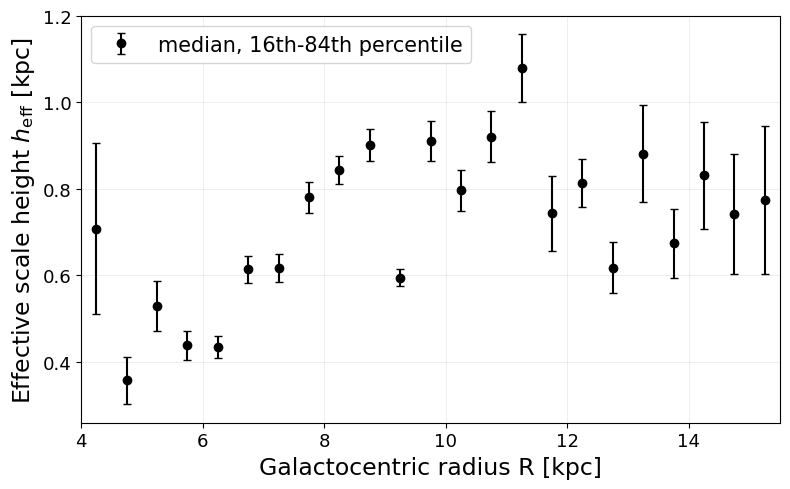

In [146]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(R_centers_flare, h_eff_med_flare, yerr=h_eff_std_flare,
            fmt="o", color="k", ms=6, capsize=3, lw=1.5,
            label="median, 16th-84th percentile")
ax.legend(loc="upper left", fontsize=15)
ax.set_xlabel("Galactocentric radius R [kpc]", fontsize=17)
ax.set_ylabel(r"Effective scale height $h_\mathrm{eff}$ [kpc]", fontsize=17)
ax.tick_params(labelsize=13)
ax.grid(True, alpha=0.25, lw=0.6)
ax.set_xlim(R_edges_flare[0], R_edges_flare[-1])
plt.tight_layout()
plt.show()

loaded 23 radial bins


computing h_eff: 100%|██████████████████████████| 23/23 [00:08<00:00,  2.61it/s]


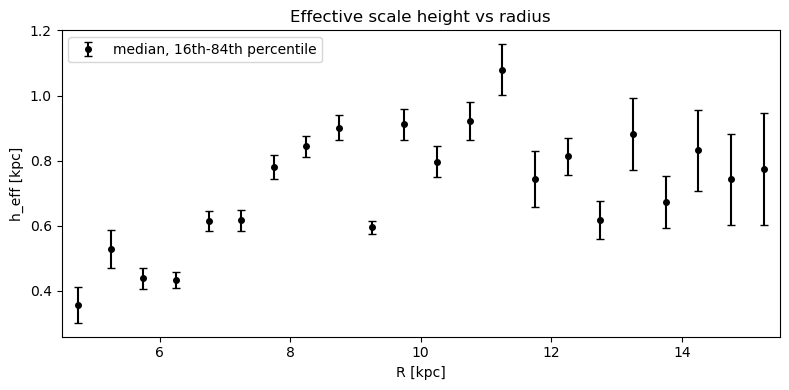

In [147]:
import pickle
import numpy as np
from scipy.optimize import brentq

# reload saved results
with open("per_R_flare.pkl", "rb") as f:
    per_R_flare = pickle.load(f)
print(f"loaded {len(per_R_flare)} radial bins")

R_edges_flare = np.arange(4.5, 16, 0.5)
# n_R_flare = len(R_edges_flare) - 1
# R_centers_flare = 0.5 * (R_edges_flare[:-1] + R_edges_flare[1:])

from tqdm import tqdm
h_eff_med_flare = np.full(n_R_flare, np.nan)
h_eff_std_flare = np.full(n_R_flare, np.nan)

for i_R, cell in tqdm(per_R_flare.items(), desc="computing h_eff"):
    s = cell["samples"]
    
    h_effs = []
    for i in range(256):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        hi = 8 * max(cell_sample["h1"], cell_sample["h2"])
        try:
            zstar = brentq(root_func, cell_sample["z0"] + 1e-9, hi, args=(cell_sample,))
            h_effs.append(zstar - cell_sample["z0"])
        except ValueError:
            continue
    
    if len(h_effs) > 0:
        h_effs = np.array(h_effs)
        h_eff_med_flare[i_R] = np.median(h_effs)
        pcl = np.percentile(h_effs, [16, 84])
        h_eff_std_flare[i_R] = 0.5 * (pcl[1] - pcl[0])

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(R_centers_flare, h_eff_med_flare, yerr=h_eff_std_flare,
            fmt="o", color="k", ms=4, capsize=3,
            label="median, 16th-84th percentile")
ax.legend(loc="upper left")
ax.set_xlabel("R [kpc]")
ax.set_ylabel("h_eff [kpc]")
ax.set_title("Effective scale height vs radius")
ax.set_xlim(R_edges_flare[0], R_edges_flare[-1])
plt.tight_layout()
plt.show()

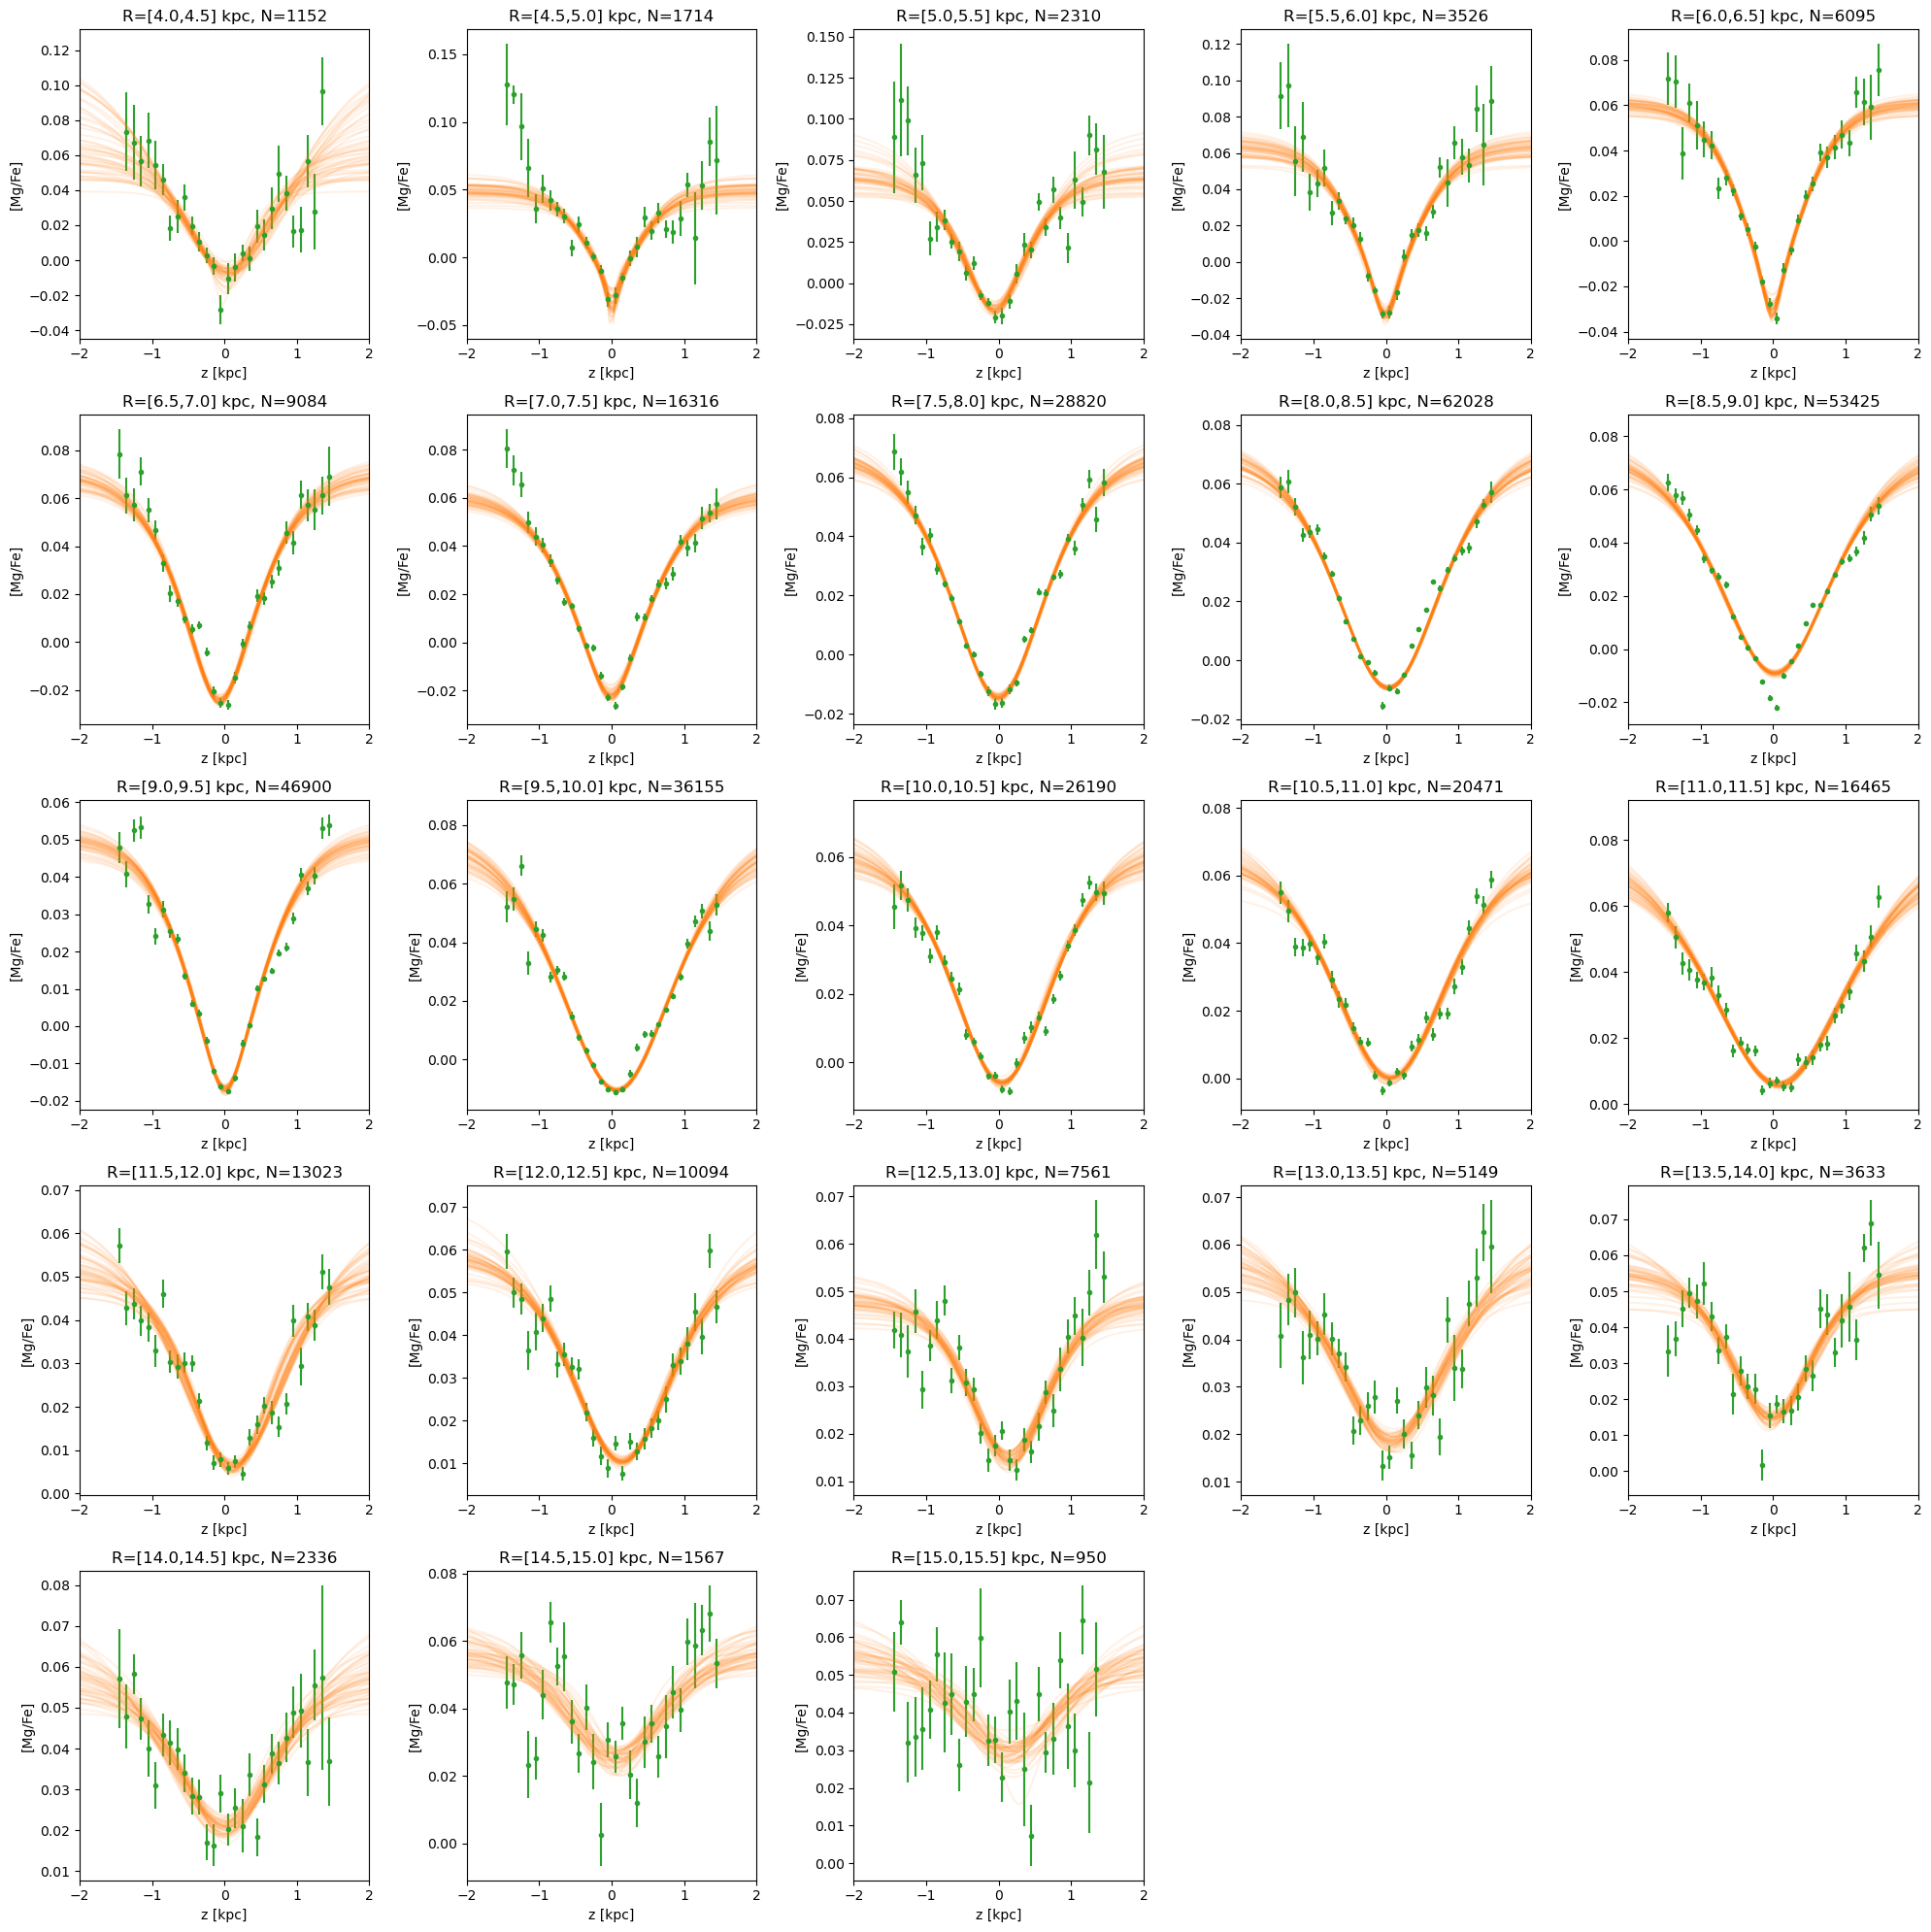

In [148]:
import pickle
with open("per_R_flare.pkl", "rb") as f:
    per_R_flare = pickle.load(f)

z_grid = np.linspace(-5, 5, 200)
fig, axes = plt.subplots(5, 5, figsize=(20, 20), squeeze=False)
for idx, (i_R, cell) in enumerate(per_R_flare.items()):
    r, c = divmod(idx, 5)
    ax = axes[r, c]
    s = cell["samples"]
    
    ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
                color="C2", linestyle="", marker=".")
    
    for i in range(min(50, len(s["A1"]))):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        y_pred = mixture_of_sech2(z_grid, cell_sample["A1"], cell_sample["A2"],
                                  cell_sample["h1"], cell_sample["h2"],
                                  cell_sample["z0"]) + cell_sample["offset"]
        ax.plot(z_grid, y_pred, color="C1", alpha=0.1)
    
    ax.set_xlabel("z [kpc]")
    ax.set_ylabel("[Mg/Fe]")
    ax.set_title(f"R=[{cell['Rlo']:.1f},{cell['Rhi']:.1f}] kpc, N={cell['n_stars']}")
    ax.set_xlim(-2, 2)

for idx in range(len(per_R_flare), 25):
    r, c = divmod(idx, 5)
    axes[r, c].axis("off")

plt.tight_layout()
plt.show()

In [46]:
for i_R, cell in per_R_flare.items():
    s = cell["samples"]
    
    h_effs = []
    failed = 0
    for i in range(256):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        hi = 8 * max(cell_sample["h1"], cell_sample["h2"])
        try:
            zstar = brentq(root_func, cell_sample["z0"] + 1e-9, hi, args=(cell_sample,))
            h_effs.append(zstar - cell_sample["z0"])
        except ValueError:
            failed += 1
    
    h_effs = np.array(h_effs)
    print(f"R=[{cell['Rlo']:.1f},{cell['Rhi']:.1f}]: "
          f"kept={len(h_effs)}/256, failed={failed}, "
          f"h_eff min={np.min(h_effs):.3f}, max={np.max(h_effs):.3f}, "
          f"median={np.median(h_effs):.3f}, std={np.std(h_effs):.3f}")

R=[6.5,7.5]: kept=256/256, failed=0, h_eff min=0.769, max=1.051, median=0.907, std=0.051
R=[7.0,8.0]: kept=256/256, failed=0, h_eff min=0.652, max=0.938, median=0.776, std=0.054
R=[7.5,8.5]: kept=256/256, failed=0, h_eff min=0.610, max=0.731, median=0.671, std=0.022
R=[8.0,9.0]: kept=256/256, failed=0, h_eff min=0.710, max=0.934, median=0.834, std=0.057
R=[8.5,9.5]: kept=256/256, failed=0, h_eff min=0.848, max=1.055, median=0.941, std=0.039


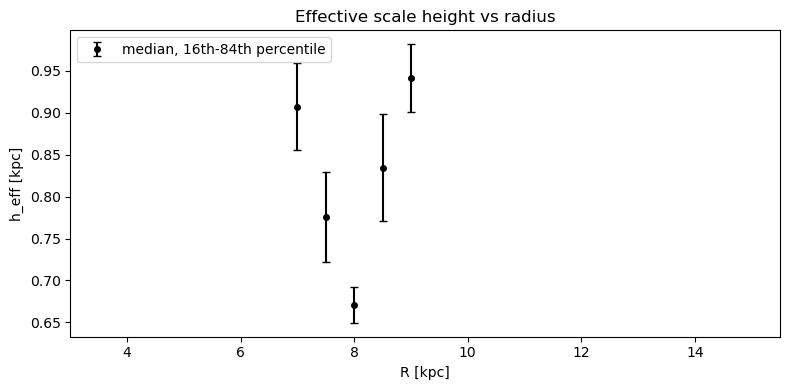

In [47]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(R_centers_flare, h_eff_med_flare, yerr=h_eff_std_flare,
            fmt="o", color="k", ms=4, capsize=3,
            label="median, 16th-84th percentile")
ax.legend(loc="upper left")
ax.set_xlabel("R [kpc]")
ax.set_ylabel("h_eff [kpc]")
ax.set_title("Effective scale height vs radius")
ax.set_xlim(R_edges_flare[0], R_edges_flare[-1])
plt.tight_layout()
plt.show()

In [22]:
cell = per_R_flare[list(per_R_flare.keys())[10]]
s = cell["samples"]
for i in range(5):
    cell_sample = {k: v[i] for k, v in s.items()}
    cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
    f_min = mixture_of_sech2(cell_sample["z0"], cell_sample["A1"], cell_sample["A2"],
                             cell_sample["h1"], cell_sample["h2"], cell_sample["z0"])
    print(f"A1={cell_sample['A1']:.4f}, A2={cell_sample['A2']:.4f}, "
          f"0.5*(A1+A2)={0.5*(cell_sample['A1']+cell_sample['A2']):.4f}, "
          f"f_min={f_min:.4f}, offset={cell_sample['offset']:.4f}")

A1=-0.0366, A2=-0.0416, 0.5*(A1+A2)=-0.0391, f_min=-0.0781, offset=0.0682
A1=-0.0269, A2=-0.0605, 0.5*(A1+A2)=-0.0437, f_min=-0.0874, offset=0.0782
A1=-0.0225, A2=-0.0663, 0.5*(A1+A2)=-0.0444, f_min=-0.0888, offset=0.0791
A1=-0.0392, A2=-0.0380, 0.5*(A1+A2)=-0.0386, f_min=-0.0772, offset=0.0685
A1=-0.0468, A2=-0.0320, 0.5*(A1+A2)=-0.0394, f_min=-0.0788, offset=0.0683


In [1]:
from tqdm import tqdm
import jax
import jax.random as jr

R_centers_flare = np.arange(4, 15+1e-3, 0.5)
R_width = 1.0
n_R_flare = len(R_centers_flare)

R_arr     = np.asarray(R_star)
Z_arr     = np.asarray(Z_star)
mgfe_arr  = np.asarray(mgfe_star)
err_arr   = np.asarray(mgfe_err_star)

m_base = (
    np.isfinite(R_arr) & np.isfinite(Z_arr)
    & np.isfinite(mgfe_arr) & np.isfinite(err_arr)
    & (err_arr > 0)
)

# store results
per_R_flare = {}
key = jr.PRNGKey(0)

for i_R in tqdm(range(n_R_flare), desc="fitting radial bins"):
    Rlo = R_centers_flare[i_R] - R_width / 2
    Rhi = R_centers_flare[i_R] + R_width / 2
    
    m = m_base & (R_arr >= Rlo) & (R_arr < Rhi)
    n_stars = int(m.sum())
    
    if n_stars < minN_seg_total:
        print(f"R=[{Rlo:.1f},{Rhi:.1f}]: skipping, only {n_stars} stars")
        continue
    
    z_binc, mean_mg_fe, mean_mg_fe_err, counts = bin_one(
        Z_arr[m], mgfe_arr[m], err_arr[m]
    )
    
    good = (
        np.isfinite(mean_mg_fe) & np.isfinite(mean_mg_fe_err)
        & (counts >= min_bin_count)
        & (z_binc >= z_fit_min) & (z_binc <= z_fit_max)
    )
    
    if good.sum() < min_bins_for_fit:
        print(f"R=[{Rlo:.1f},{Rhi:.1f}]: skipping, only {good.sum()} good bins")
        continue
    
    try:
        key, sub = jr.split(key)
        sampler = fit_sech2(
            np.asarray(z_binc[good], float),
            np.asarray(mean_mg_fe[good], float),
            np.asarray(mean_mg_fe_err[good], float),
            sub,
            progress_bar=False
        )
        samples = sampler.get_samples()
        per_R_flare[i_R] = {
            "Rlo": Rlo, "Rhi": Rhi,
            "n_stars": n_stars,
            "z_binc": np.asarray(z_binc[good]),
            "mean": np.asarray(mean_mg_fe[good]),
            "err": np.asarray(mean_mg_fe_err[good]),
            "samples": {k: np.asarray(v) for k, v in samples.items()},
        }
        print(f"R=[{Rlo:.1f},{Rhi:.1f}]: fit ok, n_stars={n_stars}")
    except Exception as e:
        print(f"R=[{Rlo:.1f},{Rhi:.1f}]: fit failed -> {e}")

print(f"fits complete: {len(per_R_flare)}/{n_R_flare}")


NameError: name 'np' is not defined